# 1. A letöltést két ütemben hajtom végre: Először a tumoros képeket töltöm le a projektből (ez kb. 500 képet jelent, jóval több mint a normal képek száma), aztán a normal képek következnek.


A továbbiakban az a cél, hogy a két metadata táblázatot összehasonlítva megmutathassam hogy van olyan Patient akinek létezik tumoros és normal felvétele is az adatbázisban. Az ő felvételeiknek a train/test halmazoknál lesz fontos szerepük mert az a tervem, hogy:
  1. Tegyük fel, hogy a 97 normal felvétel közül minden CaseID-hoz tartozik egy tumoros felvétel is.
  2. Kiválasztok pl. 20 CaseID-t ezek közül amelyek felvételeit mindkét halmazból áthelyezem egy TEST halmazba, így azokat a modellem a tanítás során nem látja majd
  3. A maradék lesz a TRAIN halmaz.
  4. A szétválasztás után kezdem el a patchekre bontást.
  5. Az arányok kiegyensúlyozása érdekében a lehetséges megoldások:
*     Undersampling
*     Oversampling / augmentáció
*     tanítási fázisban class_weights paraméter hangolása


GDC Client telepítése

In [ ]:
!wget https://gdc.cancer.gov/files/public/file/gdc-client_v1.6.1_Ubuntu_x64.zip
!unzip gdc-client_v1.6.1_Ubuntu_x64.zip
!chmod +x gdc-client

--2026-06-12 21:22:37--  https://gdc.cancer.gov/files/public/file/gdc-client_v1.6.1_Ubuntu_x64.zip
Resolving gdc.cancer.gov (gdc.cancer.gov)... 54.83.136.42, 100.57.17.155
Connecting to gdc.cancer.gov (gdc.cancer.gov)|54.83.136.42|:443... connected.
HTTP request sent, awaiting response... 302 Moved Temporarily
Location: https://gdc.cancer.gov:443/system/files/public/file/gdc-client_v1.6.1_Ubuntu_x64.zip [following]
--2026-06-12 21:22:38--  https://gdc.cancer.gov/system/files/public/file/gdc-client_v1.6.1_Ubuntu_x64.zip
Reusing existing connection to gdc.cancer.gov:443.
HTTP request sent, awaiting response... 200 OK
Length: 23940006 (23M) [application/zip]
Saving to: ‘gdc-client_v1.6.1_Ubuntu_x64.zip’

gdc-client_v1.6.1_U 100%[===================>]  22.83M  67.8MB/s    in 0.3s    

2026-06-12 21:22:38 (67.8 MB/s) - ‘gdc-client_v1.6.1_Ubuntu_x64.zip’ saved [23940006/23940006]

Archive:  gdc-client_v1.6.1_Ubuntu_x64.zip
 extracting: gdc-client              


SVS fájlok letöltése

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!apt-get install libopenslide0
!pip install openslide-python

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  libopenslide0
0 upgraded, 1 newly installed, 0 to remove and 3 not upgraded.
Need to get 89.8 kB of archives.
After this operation, 223 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 libopenslide0 amd64 3.4.1+dfsg-5build1 [89.8 kB]
Fetched 89.8 kB in 0s (1,479 kB/s)
Selecting previously unselected package libopenslide0.
(Reading database ... 118243 files and directories currently installed.)
Preparing to unpack .../libopenslide0_3.4.1+dfsg-5build1_amd64.deb ...
Unpacking libopenslide0 (3.4.1+dfsg-5build1) ...
Setting up libopenslide0 (3.4.1+dfsg-5build1) ...
Processing triggers for libc-bin (2.35-0ubuntu3.13) ...
/sbin/ldconfig.real: /usr/local/lib/libtbb.so.12 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtcm_debug.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/lo

Tumoros képek letöltése a manifest alapján

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
# a letöltést onnan folytatja ahol abbahagyta
import os
import subprocess
import pandas as pd

output_dir = '/content/drive/MyDrive/Diplomamunka/Slides/raw_tumor'
os.makedirs(output_dir, exist_ok=True)

manifest = pd.read_csv(
    '/content/drive/MyDrive/Diplomamunka/Sample Datas/Tumor/gdc_manifest.2026-05-22.103612.txt',
    sep='\t'
)

already_downloaded = set(os.listdir(output_dir))
remaining = manifest[~manifest['id'].isin(already_downloaded)]

print(f"Összes fájl: {len(manifest)}")
print(f"Már letöltött: {len(already_downloaded)}")
print(f"Még letöltendő: {len(remaining)}")

remaining.to_csv('/content/manifest_remaining.txt', sep='\t', index=False)

subprocess.run([
    './gdc-client', 'download',
    '-m', '/content/manifest_remaining.txt',
    '-d', output_dir,
    '--retry-amount', '3'
])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Összes fájl: 519
Már letöltött: 519
Még letöltendő: 0


CompletedProcess(args=['./gdc-client', 'download', '-m', '/content/manifest_remaining.txt', '-d', '/content/drive/MyDrive/Diplomamunka/Slides/raw_tumor', '--retry-amount', '3'], returncode=0)

Normal képek letöltése a manifest alapján

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
# a letöltést onnan folytatja ahol abbahagyta
import os
import subprocess
import pandas as pd

output_dir = '/content/drive/MyDrive/Diplomamunka/Slides/raw_normal'
os.makedirs(output_dir, exist_ok=True)

manifest = pd.read_csv(
    '/content/drive/MyDrive/Diplomamunka/Sample Datas/Normal/gdc_manifest.2026-05-22.140039.txt',
    sep='\t'
)

already_downloaded = set(os.listdir(output_dir))
remaining = manifest[~manifest['id'].isin(already_downloaded)]

print(f"Összes fájl: {len(manifest)}")
print(f"Már letöltött: {len(already_downloaded)}")
print(f"Még letöltendő: {len(remaining)}")

remaining.to_csv('/content/manifest_remaining_normal.txt', sep='\t', index=False)

subprocess.run([
    './gdc-client', 'download',
    '-m', '/content/manifest_remaining_normal.txt',
    '-d', output_dir,
    '--retry-amount', '3'
])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Összes fájl: 97
Már letöltött: 0
Még letöltendő: 97


CompletedProcess(args=['./gdc-client', 'download', '-m', '/content/manifest_remaining_normal.txt', '-d', '/content/drive/MyDrive/Diplomamunka/Slides/raw_normal', '--retry-amount', '3'], returncode=0)

Megnézem a metadata táblázatokban, hány CaseID-hoz tartozik normal és tumoros felvétel is

In [ ]:
import pandas as pd

# 1.TSV fájl beolvasása
tumor_df = pd.read_csv('/content/drive/MyDrive/Diplomamunka/Sample Datas/Tumor/gdc_sample_sheet.2026-05-22.tsv', sep='\t')
normal_df = pd.read_csv('/content/drive/MyDrive/Diplomamunka/Sample Datas/Normal/gdc_sample_sheet.2026-05-22.tsv', sep='\t')

#Case ID-kat használjuk az összehasonlításhoz
tumor_patients = set(tumor_df['Case ID'])
normal_patients = set(normal_df['Case ID'])

# 3.Halmazművelet (metszet)
common_patients = tumor_patients.intersection(normal_patients)

print(f"Betegek a tumoros táblázatban: {len(tumor_patients)}")
print(f"Betegek a normál táblázatban: {len(normal_patients)}")
print(f"Közös betegek száma (akiknek mindkét képe megvan): {len(common_patients)}")

# 4.CSAK a közös betegek tumoros és normál képeit tartalmazza
common_tumor_images = tumor_df[tumor_df['Case ID'].isin(common_patients)]
common_normal_images = normal_df[normal_df['Case ID'].isin(common_patients)]
combined_common = pd.concat([common_tumor_images, common_normal_images], ignore_index=True)

# 5. Mentés új TSV fájlba (tabulátorral elválasztva, eredeti formátumban)
combined_common.to_csv('/content/drive/MyDrive/Diplomamunka/Sample Datas/Both/common_metadata.tsv', sep='\t', index=False)

print(f"Közös betegek száma: {len(common_patients)}")
print(f"Új táblázatba mentett összes rekord száma: {len(combined_common)}")

Betegek a tumoros táblázatban: 506
Betegek a normál táblázatban: 97
Közös betegek száma (akiknek mindkét képe megvan): 97
Közös betegek száma: 97
Új táblázatba mentett összes rekord száma: 195


A kimeneti táblázatban van egy Case ID amelyhez 2 tumoros kép tartozik:
(ezzel később foglalkozom)

In [ ]:

tumor_counts = common_tumor_images['Case ID'].value_counts()
print(tumor_counts[tumor_counts > 1])

Case ID
TCGA-DO-A1JZ    2
Name: count, dtype: int64


# 2. Darabolás
Az openslide könyvtár segítségével 224x224 pixeles képkockákra bontom a nagyfelbontású képeket.

A 97 beteg közül 20 beteget leválasztok a teszt adathalmazba. Nekik van normal és tumor mintájuk is

Ezzel tesztelem a darabolást 2 képen

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import openslide

BASE_DIR = '/content/drive/MyDrive/Diplomamunka'
METADATA_PATH = os.path.join(BASE_DIR, 'Sample Datas/Both/common_metadata.tsv')
TUMOR_RAW_DIR = os.path.join(BASE_DIR, 'Slides/raw_tumor')
NORMAL_RAW_DIR = os.path.join(BASE_DIR, 'Slides/raw_normal')

# Kimeneti mappák
DATASET_DIR = os.path.join(BASE_DIR, 'Dataset_Test_Run')
os.makedirs(os.path.join(DATASET_DIR, 'malignant'), exist_ok=True)
os.makedirs(os.path.join(DATASET_DIR, 'normal'), exist_ok=True)

# Beállítások
PATCH_SIZE = 224
MAGNIFICATION_LEVEL = 0
WHITE_THRESHOLD = 220
MAX_WHITE_RATIO = 0.60

def is_good_tissue(patch_rgb):
    gray = cv2.cvtColor(patch_rgb, cv2.COLOR_RGB2GRAY)
    white_pixels = np.sum(gray > WHITE_THRESHOLD)
    total_pixels = gray.size
    white_ratio = white_pixels / total_pixels

    if white_ratio > MAX_WHITE_RATIO or np.std(gray) < 15:
        return False
    return True

#metaadatok betöltése és az első beteg kiválasztása tesztre
df = pd.read_csv(METADATA_PATH, sep='\t')

patients = df['Case ID'].unique()
test_patient = patients[0]
patient_records = df[df['Case ID'] == test_patient]

print(f"Teszt futtatása a következő betegen: {test_patient}")

#végigmegyek a beteg teszt-rekordjain
for idx, row in patient_records.iterrows():
    file_id = row['File ID']
    file_name = row['File Name']
    sample_id = str(row['Sample ID'])

    #a szövettani kódok rugalmas kezelése (ez a részlet mondja meg a karaktersorban hogy tumoros vagy normal minta-e)
    if '-01' in sample_id:
        slide_path = os.path.join(TUMOR_RAW_DIR, file_id, file_name)
        save_dir = os.path.join(DATASET_DIR, 'malignant')
        prefix = "tumor"
    elif '-11' in sample_id:
        slide_path = os.path.join(NORMAL_RAW_DIR, file_id, file_name)
        save_dir = os.path.join(DATASET_DIR, 'normal')
        prefix = "normal"
    else:
        print(f"Ismeretlen Sample ID formátum: {sample_id}")
        continue

    if not os.path.exists(slide_path):
        print(f"HIBA: A fájl nem található: {slide_path}")
        continue

    print(f"\nKép megnyitása: {file_name} ({prefix})...")

    slide = openslide.OpenSlide(slide_path)
    width, height = slide.level_dimensions[MAGNIFICATION_LEVEL]

    patch_count = 0
    # korrekcio: nem állok meg 10000-nél hanem a teljes képet nézenm
    # de PATCH_SIZE * 10 lépésközzel ugorva hogy a teszt gyors legyen
    STEP = PATCH_SIZE * 10

    for y in range(0, height - PATCH_SIZE, STEP):
        for x in range(0, width - PATCH_SIZE, STEP):

            patch = slide.read_region((x, y), MAGNIFICATION_LEVEL, (PATCH_SIZE, PATCH_SIZE))
            patch_rgb = np.array(patch.convert('RGB'))

            if is_good_tissue(patch_rgb):
                patch_name = f"{prefix}_{test_patient}_{x}_{y}.jpg"
                cv2.imwrite(os.path.join(save_dir, patch_name), cv2.cvtColor(patch_rgb, cv2.COLOR_RGB2BGR))
                patch_count += 1

    print(f"-> A teljes kép ritkított bejárásával sikeresen kimentve {patch_count} darab patch.")

Teszt futtatása a következő betegen: TCGA-EL-A3T7

Kép megnyitása: TCGA-EL-A3T7-01Z-00-DX1.7697FAF4-272A-44C3-B1E2-D88C2A0B3D05.svs (tumor)...
-> A teljes kép ritkított bejárásával sikeresen kimentve 270 darab patch.

Kép megnyitása: TCGA-EL-A3T7-11A-02-TS2.71628B53-6AE1-499D-8B61-52FB64919DA0.svs (normal)...
-> A teljes kép ritkított bejárásával sikeresen kimentve 39 darab patch.


A próba futtatás során (1 tumor és 1 normal kép darabolása 10000x lépésközzel) feltünt hogy nagyon különbözik a kimeneti patchek aránya. Megnyitottam a normal képet és egy ún. duplikált mintát találtam. Ez azért lesz problémás mert így a neurális hálóm kétszer fogja látni ugyanazt a mintát, ezt megpróbálom majd kezelni a végleges kódban.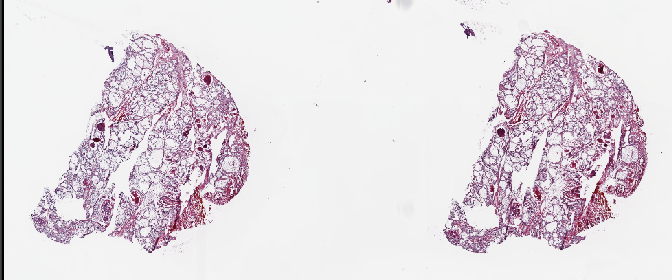

Egy patch korlát bevezetése csökkentheti a duplikált minták okozta hibák mértékét -> Pl. egy mintából maximum 200 patchet menthetünk le

Mivel nem szeretném hogy a letöltött minták hiába legyenek:

  506 tumoros mintám van és 97 normal.
  
  Amelyik betegnek van normal képe annak van tumoros képe is. Tehát 409 tumoros mintám marad amelyet szabályozottan kell feldolgoznom hogy ne nyomja el a normal-tumor címkék arányát egyik irányba se.

### **1. lépés**: Legyártom a 77 beteg normal patch-eit (20 beteget leválasztok a teszt adathalmazba)

Tegyük fel ez 30000 patchet eredményez. (***N***)


### **2. lépés**: Ehhez az ***N***-hez kiszámolom a tumoros kvótát. Ez azt jelenti hogy megmondom: 486 (409+77) mintából pontosan ***N*** darab patch jöjjön ki
30000patch / 486kép = kb 61patch / kép

### **3.lépés**: Legyártom a tumoros oldalt a kvóta alapján

Végeredmény:

train/normal mappában is ***N*** darab patch

train/malignant mappában is ***N*** darab patch







## Azonban ez a Colab ingyenes verziója miatt nem fut le végig. Ezért később darabolom a fázisokat

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import openslide
import random
from tqdm import tqdm

# 1. Útvonalak beállítása
BASE_DIR = '/content/drive/MyDrive/Diplomamunka'
METADATA_PATH = os.path.join(BASE_DIR, 'Sample Datas/Both/common_metadata.tsv')
FULL_TUMOR_PATH = os.path.join(BASE_DIR, 'Sample Datas/Tumor/gdc_sample_sheet.2026-05-22.tsv')
TUMOR_RAW_DIR = os.path.join(BASE_DIR, 'Slides/raw_tumor')
NORMAL_RAW_DIR = os.path.join(BASE_DIR, 'Slides/raw_normal')
DATASET_DIR = os.path.join(BASE_DIR, 'Dataset')

PATCH_SIZE = 224
WHITE_THRESHOLD = 220
MAX_WHITE_RATIO = 0.75  #engedékenyebb a pajzsmirigy tüszők miatt (normal képek esetén fontosabb)

#2. adattáblák betöltése és a Teszt halmaz leválasztása
df_common = pd.read_csv(METADATA_PATH, sep='\t')
df_full_tumor = pd.read_csv(FULL_TUMOR_PATH, sep='\t')

all_common_patients = list(df_common['Case ID'].unique())

#fix seed (hogy az a 20 tesztbeteg ugyanaz maradjon)
random.seed(42)
test_patients = random.sample(all_common_patients, k=20)
train_common_patients = [p for p in all_common_patients if p not in test_patients]

print(f"Tesztelésre elzárt betegek száma: {len(test_patients)}")

def is_good_tissue(patch_rgb):
    """Ellenőrzi, hogy a patch valódi szövet-e"""
    gray = cv2.cvtColor(patch_rgb, cv2.COLOR_RGB2GRAY)
    white_pixels = np.sum(gray > WHITE_THRESHOLD)
    white_ratio = white_pixels / gray.size
    if white_ratio > MAX_WHITE_RATIO or np.std(gray) < 12:
        return False
    return True

def extract_valid_patchesFrom_slide(slide_path):
    """Megnyit egy képet és összegyűjti az összes minőségileg jó koordinátát és patchet"""
    if not os.path.exists(slide_path):
        return []

    slide = openslide.OpenSlide(slide_path)
    width, height = slide.level_dimensions[0]
    valid_list = []

    for y in range(0, height - PATCH_SIZE, PATCH_SIZE):
        for x in range(0, width - PATCH_SIZE, PATCH_SIZE):
            patch = slide.read_region((x, y), 0, (PATCH_SIZE, PATCH_SIZE))
            patch_rgb = np.array(patch.convert('RGB'))

            if is_good_tissue(patch_rgb):
                valid_list.append((x, y, patch_rgb))
    return valid_list

# ==============================================================================
# I. FÁZIS: A TESZT HALMAZ LEGYÁRTÁSA (20-20 pár)
# ==============================================================================
print("\n--- I. FÁZIS: TESZT HALMAZ GENERÁLÁSA ---")
df_test = df_common[df_common['Case ID'].isin(test_patients)]

for idx, row in tqdm(df_test.iterrows(), total=len(df_test), desc="Test képek vágása"):
    file_id = row['File ID']
    file_name = row['File Name']
    sample_id = str(row['Sample ID'])
    patient_id = row['Case ID']

    if '-01' in sample_id:
        slide_path = os.path.join(TUMOR_RAW_DIR, file_id, file_name)
        save_dir = os.path.join(DATASET_DIR, 'test', 'malignant')
        prefix = "tumor"
    else:
        slide_path = os.path.join(NORMAL_RAW_DIR, file_id, file_name)
        save_dir = os.path.join(DATASET_DIR, 'test', 'normal')
        prefix = "normal"

    os.makedirs(save_dir, exist_ok=True)
    patches = extract_valid_patchesFrom_slide(slide_path)

    #teszt halmaz se legyen túlméretezve: képenként max 300-at mentünk
    if len(patches) > 300:
        patches = random.sample(patches, 300)

    for x, y, patch_rgb in patches:
        cv2.imwrite(os.path.join(save_dir, f"{prefix}_{patient_id}_{x}_{y}.jpg"), cv2.cvtColor(patch_rgb, cv2.COLOR_RGB2BGR))

# ==============================================================================
# II. FÁZIS: A TRAIN NORMAL HALMAZ LEGYÁRTÁSA (a bázis/kvóta meghatározása)
# ==============================================================================
print("\n--- II. FÁZIS: TRAIN EGÉSZSÉGES (NORMAL) HALMAZ GENERÁLÁSA ---")
df_train_normal = df_common[(df_common['Case ID'].isin(train_common_patients)) & (df_common['Sample ID'].str.contains('-11'))]
save_dir_normal = os.path.join(DATASET_DIR, 'train', 'normal')
os.makedirs(save_dir_normal, exist_ok=True)

total_normal_patches = 0

for idx, row in tqdm(df_train_normal.iterrows(), total=len(df_train_normal), desc="Normal képek vágása"):
    slide_path = os.path.join(NORMAL_RAW_DIR, row['File ID'], row['File Name'])
    patches = extract_valid_patchesFrom_slide(slide_path)

    for x, y, patch_rgb in patches:
        cv2.imwrite(os.path.join(save_dir_normal, f"normal_{row['Case ID']}_{x}_{y}.jpg"), cv2.cvtColor(patch_rgb, cv2.COLOR_RGB2BGR))
        total_normal_patches += 1

print(f"\nSikeresen legyártva a BÁZIS: {total_normal_patches} darab egészséges patch.")

# ==============================================================================
# III. FÁZIS: A TRAIN TUMOR HALMAZ LEGYÁRTÁSA (patikamérleges kiegyensúlyozás)
# ==============================================================================
print("\n--- III. FÁZIS: TRAIN DAGANATOS (MALIGNANT) HALMAZ GENERÁLÁSA (KVÓTA ALAPJÁN) ---")

#összegyűjtjük az összes tumoros képet ami NEM került a test halmazba
# (A 77 megmaradt közös tumor + a 409 egyedülálló tumor)
test_file_ids = set(df_test['File ID'])
df_train_tumor = df_full_tumor[~df_full_tumor['File ID'].isin(test_file_ids)]

total_tumor_slides = len(df_train_tumor)
# Kiszámoljuk a pontos képenkénti kvótát
quota_per_slide = int(np.ceil(total_normal_patches / total_tumor_slides))

print(f"Összes feldolgozandó tumoros kép a trainben: {total_tumor_slides}")
print(f"Szükséges darabszám képenként a tökéletes egyensúlyhoz: ~{quota_per_slide} patch/kép")

save_dir_tumor = os.path.join(DATASET_DIR, 'train', 'malignant')
os.makedirs(save_dir_tumor, exist_ok=True)

tumor_patch_pool = []

for idx, row in tqdm(df_train_tumor.iterrows(), total=len(df_train_tumor), desc="Tumoros képek mintavételezése"):
    slide_path = os.path.join(TUMOR_RAW_DIR, row['File ID'], row['File Name'])
    patches = extract_valid_patchesFrom_slide(slide_path)

    #ha a képből több patch jött ki mint a kvóta, véletlenszerűen kiválasztunk pontosan annyit
    if len(patches) > quota_per_slide:
        patches = random.sample(patches, quota_per_slide)

    for x, y, patch_rgb in patches:
        tumor_patch_pool.append((row['Case ID'], x, y, patch_rgb))

#végső finomhangolás: mivel a kerekítések miatt a pool lehet picit nagyobb/kisebb,
# pontosan a total_normal_patches méretűre vágjuk a listát
random.shuffle(tumor_patch_pool)
final_tumor_patches = tumor_patch_pool[:total_normal_patches]

for patient_id, x, y, patch_rgb in tqdm(final_tumor_patches, desc="Tumoros patchek kiírása"):
    cv2.imwrite(os.path.join(save_dir_tumor, f"tumor_{patient_id}_{x}_{y}.jpg"), cv2.cvtColor(patch_rgb, cv2.COLOR_RGB2BGR))

print(f"\n--- success ---")
print(f"Végső Tanítóhalmaz egyensúlya:")
print(f"-> train/normal: {total_normal_patches} db kép")
print(f"-> train/malignant: {len(final_tumor_patches)} db kép")

1.rész (1. és 2. fázis)

Ez a kód azért borzasztóan lassú mert a kép teljes felbontású rétegét járom be a patchelés során pixelről pixelre. Ezt a következő blokkban javítom

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import openslide
import random
from tqdm import tqdm

BASE_DIR = '/content/drive/MyDrive/Diplomamunka'
METADATA_PATH = os.path.join(BASE_DIR, 'Sample Datas/Both/common_metadata.tsv')
NORMAL_RAW_DIR = os.path.join(BASE_DIR, 'Slides/raw_normal')
TUMOR_RAW_DIR = os.path.join(BASE_DIR, 'Slides/raw_tumor')
DATASET_DIR = os.path.join(BASE_DIR, 'Dataset')

PATCH_SIZE = 224
WHITE_THRESHOLD = 220
MAX_WHITE_RATIO = 0.75

df_common = pd.read_csv(METADATA_PATH, sep='\t')
all_common_patients = list(df_common['Case ID'].unique())

random.seed(42)
test_patients = random.sample(all_common_patients, k=20)
train_common_patients = [p for p in all_common_patients if p not in test_patients]

def is_good_tissue(patch_rgb):
    gray = cv2.cvtColor(patch_rgb, cv2.COLOR_RGB2GRAY)
    white_pixels = np.sum(gray > WHITE_THRESHOLD)
    if (white_pixels / gray.size) > MAX_WHITE_RATIO or np.std(gray) < 12:
        return False
    return True

# --- I. FÁZIS: TESZT HALMAZ ---
print("--- I. FÁZIS: TESZT HALMAZ GENERÁLÁSA ---")
df_test = df_common[df_common['Case ID'].isin(test_patients)]
for idx, row in tqdm(df_test.iterrows(), total=len(df_test), desc="Test képek"):
    file_id, file_name, sample_id, patient_id = row['File ID'], row['File Name'], str(row['Sample ID']), row['Case ID']
    if '-01' in sample_id:
        slide_path = os.path.join(TUMOR_RAW_DIR, file_id, file_name)
        save_dir = os.path.join(DATASET_DIR, 'test', 'malignant')
        prefix = "tumor"
    else:
        slide_path = os.path.join(NORMAL_RAW_DIR, file_id, file_name)
        save_dir = os.path.join(DATASET_DIR, 'test', 'normal')
        prefix = "normal"

    if not os.path.exists(slide_path): continue
    os.makedirs(save_dir, exist_ok=True)

    slide = openslide.OpenSlide(slide_path)
    w, h = slide.level_dimensions[0]
    count = 0
    for y in range(0, h - PATCH_SIZE, PATCH_SIZE):
        for x in range(0, w - PATCH_SIZE, PATCH_SIZE):
            patch = slide.read_region((x, y), 0, (PATCH_SIZE, PATCH_SIZE))
            img = np.array(patch.convert('RGB'))
            if is_good_tissue(img) and count < 300:
                cv2.imwrite(os.path.join(save_dir, f"{prefix}_{patient_id}_{x}_{y}.jpg"), cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
                count += 1

# --- II. FÁZIS: TRAIN NORMAL ---
print("\n--- II. FÁZIS: TRAIN NORMAL GENERÁLÁSA ---")
df_train_normal = df_common[(df_common['Case ID'].isin(train_common_patients)) & (df_common['Sample ID'].str.contains('-11'))]
save_dir_normal = os.path.join(DATASET_DIR, 'train', 'normal')
os.makedirs(save_dir_normal, exist_ok=True)

total_normal_patches = 0
for idx, row in tqdm(df_train_normal.iterrows(), total=len(df_train_normal), desc="Normal képek"):
    slide_path = os.path.join(NORMAL_RAW_DIR, row['File ID'], row['File Name'])
    if not os.path.exists(slide_path): continue

    slide = openslide.OpenSlide(slide_path)
    w, h = slide.level_dimensions[0]
    for y in range(0, h - PATCH_SIZE, PATCH_SIZE):
        for x in range(0, w - PATCH_SIZE, PATCH_SIZE):
            patch = slide.read_region((x, y), 0, (PATCH_SIZE, PATCH_SIZE))
            img = np.array(patch.convert('RGB'))
            if is_good_tissue(img):
                cv2.imwrite(os.path.join(save_dir_normal, f"normal_{row['Case ID']}_{x}_{y}.jpg"), cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
                total_normal_patches += 1

print(f"\nKÉSZ! A bázis darabszám megvan: {total_normal_patches} db normal patch lett.")

--- I. FÁZIS: TESZT HALMAZ GENERÁLÁSA ---


Test képek:   0%|          | 0/40 [08:47<?, ?it/s]


KeyboardInterrupt: 

## Egy magasabb szintű felbontást vizsgálva nézem meg hogy hol van szövet és hol nincs, ez talán gyorsít a folyamaton.

+onnan folytatja ahol egyszer abbahagyta (ha megszakadna futás közben)

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import openslide
import random
from tqdm import tqdm

BASE_DIR = '/content/drive/MyDrive/Diplomamunka'
METADATA_PATH = os.path.join(BASE_DIR, 'Sample Datas/Both/common_metadata.tsv')
NORMAL_RAW_DIR = os.path.join(BASE_DIR, 'Slides/raw_normal')
TUMOR_RAW_DIR = os.path.join(BASE_DIR, 'Slides/raw_tumor')
DATASET_DIR = os.path.join(BASE_DIR, 'Dataset')

PATCH_SIZE = 224
WHITE_THRESHOLD = 220
MAX_WHITE_RATIO = 0.75

# Naplófájlok útvonalai a megszakítás ellen
os.makedirs(DATASET_DIR, exist_ok=True)
CHECKPOINT_TEST = os.path.join(DATASET_DIR, 'checkpoint_test.txt')
CHECKPOINT_NORMAL = os.path.join(DATASET_DIR, 'checkpoint_normal.txt')

df_common = pd.read_csv(METADATA_PATH, sep='\t')
all_common_patients = list(df_common['Case ID'].unique())

random.seed(42)
test_patients = random.sample(all_common_patients, k=20)
train_common_patients = [p for p in all_common_patients if p not in test_patients]

def get_tissue_coordinates(slide, patch_size):
    level = min(2, len(slide.level_dimensions) - 1)
    scale = int(slide.level_downsamples[level])
    low_res_img = slide.read_region((0, 0), level, slide.level_dimensions[level])
    low_res_rgb = np.array(low_res_img.convert('RGB'))
    gray = cv2.cvtColor(low_res_rgb, cv2.COLOR_RGB2GRAY)

    valid_coords = []
    w_high, h_high = slide.level_dimensions[0]

    for y in range(0, h_high - patch_size, patch_size):
        for x in range(0, w_high - patch_size, patch_size):
            x_low, y_low = int(x / scale), int(y / scale)
            w_low, h_low = int(patch_size / scale), int(patch_size / scale)
            patch_low = gray[y_low:y_low+h_low, x_low:x_low+w_low]
            if patch_low.size == 0: continue

            if (np.sum(patch_low > WHITE_THRESHOLD) / patch_low.size) <= MAX_WHITE_RATIO and np.std(patch_low) >= 12:
                valid_coords.append((x, y))
    return valid_coords

def load_checkpoint(path):
    if os.path.exists(path):
        with open(path, 'r') as f:
            return set(line.strip() for line in f)
    return set()

# --- I. FÁZIS: TESZT HALMAZ ---
print("--- I. FÁZIS: TESZT HALMAZ GENERÁLÁSA ---")
processed_test = load_checkpoint(CHECKPOINT_TEST)
df_test = df_common[df_common['Case ID'].isin(test_patients)]

for idx, row in tqdm(df_test.iterrows(), total=len(df_test), desc="Test képek"):
    file_id = row['File ID']
    if file_id in processed_test: continue  #átugorja, ha már kész

    file_name, sample_id, patient_id = row['File Name'], str(row['Sample ID']), row['Case ID']
    if '-01' in sample_id:
        slide_path = os.path.join(TUMOR_RAW_DIR, file_id, file_name)
        save_dir = os.path.join(DATASET_DIR, 'test', 'malignant')
        prefix = "tumor"
    else:
        slide_path = os.path.join(NORMAL_RAW_DIR, file_id, file_name)
        save_dir = os.path.join(DATASET_DIR, 'test', 'normal')
        prefix = "normal"

    if not os.path.exists(slide_path): continue
    os.makedirs(save_dir, exist_ok=True)

    slide = openslide.OpenSlide(slide_path)
    coords = get_tissue_coordinates(slide, PATCH_SIZE)
    if len(coords) > 300: coords = random.sample(coords, 300)

    for x, y in coords:
        patch = slide.read_region((x, y), 0, (PATCH_SIZE, PATCH_SIZE))
        img = np.array(patch.convert('RGB'))
        cv2.imwrite(os.path.join(save_dir, f"{prefix}_{patient_id}_{x}_{y}.jpg"), cv2.cvtColor(img, cv2.COLOR_RGB2BGR))

    with open(CHECKPOINT_TEST, 'a') as f: f.write(f"{file_id}\n")

# --- II. FÁZIS: TRAIN NORMAL ---
print("\n--- II. FÁZIS: TRAIN NORMAL GENERÁLÁSA ---")
processed_normal = load_checkpoint(CHECKPOINT_NORMAL)
df_train_normal = df_common[(df_common['Case ID'].isin(train_common_patients)) & (df_common['Sample ID'].str.contains('-11'))]
save_dir_normal = os.path.join(DATASET_DIR, 'train', 'normal')
os.makedirs(save_dir_normal, exist_ok=True)

for idx, row in tqdm(df_train_normal.iterrows(), total=len(df_train_normal), desc="Normal képek"):
    file_id = row['File ID']
    if file_id in processed_normal: continue  #átugorja, ha már kész

    slide_path = os.path.join(NORMAL_RAW_DIR, file_id, row['File Name'])
    if not os.path.exists(slide_path): continue

    slide = openslide.OpenSlide(slide_path)
    coords = get_tissue_coordinates(slide, PATCH_SIZE)

    for x, y in coords:
        patch = slide.read_region((x, y), 0, (PATCH_SIZE, PATCH_SIZE))
        img = np.array(patch.convert('RGB'))
        cv2.imwrite(os.path.join(save_dir_normal, f"normal_{row['Case ID']}_{x}_{y}.jpg"), cv2.cvtColor(img, cv2.COLOR_RGB2BGR))

    with open(CHECKPOINT_NORMAL, 'a') as f: f.write(f"{file_id}\n")

#összeszámoljuk a sikeresen kimentett patcheket a bázishoz
total_normal_patches = len([f for f in os.listdir(save_dir_normal) if f.endswith('.jpg')])
print(f"\nKÉSZ! A bázis darabszám megvan: {total_normal_patches} db normal patch lett a Drive-on.")

--- I. FÁZIS: TESZT HALMAZ GENERÁLÁSA ---


Test képek: 100%|██████████| 40/40 [2:06:55<00:00, 190.40s/it]



--- II. FÁZIS: TRAIN NORMAL GENERÁLÁSA ---


Normal képek: 100%|██████████| 77/77 [2:08:11<00:00, 99.89s/it]



KÉSZ! A bázis darabszám megvan: 185887 db normal patch lett a Drive-on.


Ez a kód pedig a harmadik fázis ahol a tumoros képeken végighaladva patchelek. Egy txtbe kimentem jelenleg hol jár az algoritmus ha esetleg, megszakadna a folyamat.

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import openslide
import random
from tqdm import tqdm

BASE_DIR = '/content/drive/MyDrive/Diplomamunka'
METADATA_PATH = os.path.join(BASE_DIR, 'Sample Datas/Both/common_metadata.tsv')
FULL_TUMOR_PATH = os.path.join(BASE_DIR, 'Sample Datas/Tumor/gdc_sample_sheet.2026-05-22.tsv')
TUMOR_RAW_DIR = os.path.join(BASE_DIR, 'Slides/raw_tumor')
DATASET_DIR = os.path.join(BASE_DIR, 'Dataset')

PATCH_SIZE = 224
WHITE_THRESHOLD = 220
MAX_WHITE_RATIO = 0.75
CHECKPOINT_PATH = os.path.join(DATASET_DIR, 'tumor_checkpoint.txt')

# Az előző blokk eredménye:
TOTAL_NORMAL_PATCHES = 185887

# 2. Adatok előkészítése és a Teszt betegek kiszűrése
df_common = pd.read_csv(METADATA_PATH, sep='\t')
all_common_patients = list(df_common['Case ID'].unique())
random.seed(42)
test_patients = random.sample(all_common_patients, k=20)
df_test = df_common[df_common['Case ID'].isin(test_patients)]
test_file_ids = set(df_test['File ID'])

# Betöltjük a teljes 506-os listát és kidobjuk a teszteket
df_full_tumor = pd.read_csv(FULL_TUMOR_PATH, sep='\t')
df_train_tumor = df_full_tumor[~df_full_tumor['File ID'].isin(test_file_ids)]

total_tumor_slides = len(df_train_tumor)
quota_per_slide = int(np.ceil(TOTAL_NORMAL_PATCHES / total_tumor_slides))

print(f"Feldolgozandó tumoros képek száma: {total_tumor_slides}")
print(f"Kiszámolt pontos kvóta: max {quota_per_slide} patch / kép a tökéletes egyensúlyhoz.")

# Mappa létrehozása
save_dir_tumor = os.path.join(DATASET_DIR, 'train', 'malignant')
os.makedirs(save_dir_tumor, exist_ok=True)

# Checkpoint betöltése
processed_files = set()
if os.path.exists(CHECKPOINT_PATH):
    with open(CHECKPOINT_PATH, 'r') as f:
        processed_files = set(line.strip() for line in f)
    print(f"Folytatás: {len(processed_files)} kép már korábban sikeresen feldolgozva.")

def get_tissue_coordinates(slide, patch_size):
    """Gyors makró-alapú szűrés, hogy ne másodpercenként olvassunk lemezt"""
    level = min(2, len(slide.level_dimensions) - 1)
    scale = int(slide.level_downsamples[level])
    low_res_img = slide.read_region((0, 0), level, slide.level_dimensions[level])
    low_res_rgb = np.array(low_res_img.convert('RGB'))
    gray = cv2.cvtColor(low_res_rgb, cv2.COLOR_RGB2GRAY)

    valid_coords = []
    w_high, h_high = slide.level_dimensions[0]

    for y in range(0, h_high - patch_size, patch_size):
        for x in range(0, w_high - patch_size, patch_size):
            x_low, y_low = int(x / scale), int(y / scale)
            w_low, h_low = int(patch_size / scale), int(patch_size / scale)
            patch_low = gray[y_low:y_low+h_low, x_low:x_low+w_low]
            if patch_low.size == 0: continue

            if (np.sum(patch_low > WHITE_THRESHOLD) / patch_low.size) <= MAX_WHITE_RATIO and np.std(patch_low) >= 12:
                valid_coords.append((x, y))
    return valid_coords

# 3. Tumoros képek feldolgozása egyenként (A Te logikád, de felgyorsítva)
for idx, row in tqdm(df_train_tumor.iterrows(), total=len(df_train_tumor), desc="Tumor képek"):
    file_id = row['File ID']
    file_name = row['File Name']
    patient_id = row['Case ID']

    if file_id in processed_files:
        continue

    slide_path = os.path.join(TUMOR_RAW_DIR, file_id, file_name)
    if not os.path.exists(slide_path):
        continue

    slide = openslide.OpenSlide(slide_path)

    # GYORSÍTÁS: Csak a jó koordinátákat kérjük le a kisképről
    valid_coordinates = get_tissue_coordinates(slide, PATCH_SIZE)

    # Ha több jó rész van, mint a kvóta, mintavételezünk belőle
    if len(valid_coordinates) > quota_per_slide:
        valid_coordinates = random.sample(valid_coordinates, quota_per_slide)

    # Csak azokat nyitjuk meg és mentjük el nagy felbontásban, amik kellenek
    for x, y in valid_coordinates:
        patch = slide.read_region((x, y), 0, (PATCH_SIZE, PATCH_SIZE))
        img = np.array(patch.convert('RGB'))
        cv2.imwrite(os.path.join(save_dir_tumor, f"tumor_{patient_id}_{x}_{y}.jpg"), cv2.cvtColor(img, cv2.COLOR_RGB2BGR))

    # Kép kész, felírjuk a naplóba
    with open(CHECKPOINT_PATH, 'a') as f:
        f.write(f"{file_id}\n")

# Végső finomhangolás: ha a kerekítések miatt pár darabbal több lenne, lefaragjuk a hajszálpontos egyezéshez
generated_tumor_patches = [f for f in os.listdir(save_dir_tumor) if f.endswith('.jpg')]
if len(generated_tumor_patches) > TOTAL_NORMAL_PATCHES:
    print("\nKerekítési többlet eltávolítása a tökéletes egyensúlyért...")
    excess = len(generated_tumor_patches) - TOTAL_NORMAL_PATCHES
    random.shuffle(generated_tumor_patches)
    for i in range(excess):
        os.remove(os.path.join(save_dir_tumor, generated_tumor_patches[i]))

print("\n SIKER! A tumoros oldal is elkészült, az adathalmazod tökéletesen kiegyensúlyozott!")

Feldolgozandó tumoros képek száma: 499
Kiszámolt pontos kvóta: max 373 patch / kép a tökéletes egyensúlyhoz.
Folytatás: 70 kép már korábban sikeresen feldolgozva.


Tumor képek:  14%|█▍        | 70/499 [03:33<21:49,  3.05s/it]


OpenSlideError: Cannot read raw tile

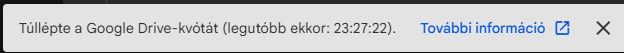

Ezt a korlát nem volt előre ismert számomra, a következőkben úgy módosítom a kódot hogy egy minta olvasása esetén max 383 darab API hívás történjen a drive felé ne pedig több tízezer, mert ez volt az oka ennek a hibának. Ezzel remélhetőleg csökken egy kicsit a feldolgozás ideje is, mert jelenleg 70/499-nél megállt, de ezt is 12 óra alatt érte el.

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import openslide
import random
import shutil
from tqdm import tqdm
import gc

BASE_DIR = '/content/drive/MyDrive/Diplomamunka'
METADATA_PATH = os.path.join(BASE_DIR, 'Sample Datas/Both/common_metadata.tsv')
FULL_TUMOR_PATH = os.path.join(BASE_DIR, 'Sample Datas/Tumor/gdc_sample_sheet.2026-05-22.tsv')
TUMOR_RAW_DIR = os.path.join(BASE_DIR, 'Slides/raw_tumor')
DATASET_DIR = os.path.join(BASE_DIR, 'Dataset')

PATCH_SIZE = 224
WHITE_THRESHOLD = 220
MAX_WHITE_RATIO = 0.75
CHECKPOINT_PATH = os.path.join(DATASET_DIR, 'tumor_checkpoint.txt')
TOTAL_NORMAL_PATCHES = 185887

#MÓDOSÍTÁS: A Colab gyors belső memóriáját használom átmenetileg
LOCAL_TEMP_DIR = '/content/tumor_temp'
os.makedirs(LOCAL_TEMP_DIR, exist_ok=True)
DRIVE_SAVE_DIR = os.path.join(DATASET_DIR, 'train', 'malignant')
os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)

#adatok előkészítése
df_common = pd.read_csv(METADATA_PATH, sep='\t')
all_common_patients = list(df_common['Case ID'].unique())
random.seed(42)
test_patients = random.sample(all_common_patients, k=20)
df_test = df_common[df_common['Case ID'].isin(test_patients)]
test_file_ids = set(df_test['File ID'])

df_full_tumor = pd.read_csv(FULL_TUMOR_PATH, sep='\t')
df_train_tumor = df_full_tumor[~df_full_tumor['File ID'].isin(test_file_ids)]

total_tumor_slides = len(df_train_tumor)
quota_per_slide = int(np.ceil(TOTAL_NORMAL_PATCHES / total_tumor_slides))

#checkpoint betöltése
processed_files = set()
if os.path.exists(CHECKPOINT_PATH):
    with open(CHECKPOINT_PATH, 'r') as f:
        processed_files = set(line.strip() for line in f)
    print(f"--> BIZTONSÁGI FOLYTATÁS: {len(processed_files)} kép már kész. Ugrás a következőre.")

def get_tissue_coordinates(slide, patch_size):
    level = min(2, len(slide.level_dimensions) - 1)
    scale = int(slide.level_downsamples[level])
    low_res_img = slide.read_region((0, 0), level, slide.level_dimensions[level])
    low_res_rgb = np.array(low_res_img.convert('RGB'))
    gray = cv2.cvtColor(low_res_rgb, cv2.COLOR_RGB2GRAY)

    valid_coords = []
    w_high, h_high = slide.level_dimensions[0]

    for y in range(0, h_high - patch_size, patch_size):
        for x in range(0, w_high - patch_size, patch_size):
            x_low, y_low = int(x / scale), int(y / scale)
            w_low, h_low = int(patch_size / scale), int(patch_size / scale)
            patch_low = gray[y_low:y_low+h_low, x_low:x_low+w_low]
            if patch_low.size == 0: continue

            if (np.sum(patch_low > WHITE_THRESHOLD) / patch_low.size) <= MAX_WHITE_RATIO and np.std(patch_low) >= 12:
                valid_coords.append((x, y))
    return valid_coords

#Feldolgozás
for idx, row in tqdm(df_train_tumor.iterrows(), total=len(df_train_tumor), desc="Tumor képek"):
    file_id = row['File ID']
    file_name = row['File Name']
    patient_id = row['Case ID']

    if file_id in processed_files:
        continue

    slide_path = os.path.join(TUMOR_RAW_DIR, file_id, file_name)
    if not os.path.exists(slide_path):
        continue

    try:
        slide = openslide.OpenSlide(slide_path)
        valid_coordinates = get_tissue_coordinates(slide, PATCH_SIZE)

        if len(valid_coordinates) > quota_per_slide:
            valid_coordinates = random.sample(valid_coordinates, quota_per_slide)

        #mentés a HELYI mappába (elrekülve a drive-ba írást egyesével)
        local_saved_files = []
        for x, y in valid_coordinates:
            patch = slide.read_region((x, y), 0, (PATCH_SIZE, PATCH_SIZE))
            img = np.array(patch.convert('RGB'))
            filename = f"tumor_{patient_id}_{x}_{y}.jpg"
            local_path = os.path.join(LOCAL_TEMP_DIR, filename)
            cv2.imwrite(local_path, cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
            local_saved_files.append((local_path, os.path.join(DRIVE_SAVE_DIR, filename)))

        # HA A MINTA KÉSZ egyben átmásoljuk a Drive-ra a patcheket
        for local_p, drive_p in local_saved_files:
            shutil.move(local_p, drive_p)

        #checkpointb
        with open(CHECKPOINT_PATH, 'a') as f:
            f.write(f"{file_id}\n")

    except Exception as e:
        print(f"\n Hiba történt a {file_name} képnél, átugorjuk. Hiba: {e}")
        continue

#végső nyesés
generated_tumor_patches = [f for f in os.listdir(DRIVE_SAVE_DIR) if f.endswith('.jpg')]
if len(generated_tumor_patches) > TOTAL_NORMAL_PATCHES:
    excess = len(generated_tumor_patches) - TOTAL_NORMAL_PATCHES
    random.shuffle(generated_tumor_patches)
    for i in range(excess):
        os.remove(os.path.join(DRIVE_SAVE_DIR, generated_tumor_patches[i]))

print("\n--- KÉSZ! ---")

--> BIZTONSÁGI FOLYTATÁS: 350 kép már kész. Ugrás a következőre.


Tumor képek:   0%|          | 0/499 [00:00<?, ?it/s]

Sajnos ismét javításokat kell alkalmaznom kb. a 350. minta után mert váratlan és egyelőre ismeretlen okból a Colab RAM mérete már nem elég 1-1 minta koordinátáinak kigyűjtésére.

A javított kód ezeket a plusz részeket tartalmazza:


*   Debug üzenetek
*   Level 2 helyett level 3 (ha elérhető) szinten dolgozom fel a mintákat
*   100 Patchenként törlöm a ram-ból a minta maradványait és üres gyorsítótárral kezdem meg a következő 100 patch kivágását

Később a debug üzenetekből kiderült, hogy nem a patchek feldolgozása okozta az összeomlásokat hanem maguk a koordináták kigyűjtése (get_tissue_coordinates) közben sem volt már elég a RAM. Ez azért történik mert korábban azt feltételeztem hogy a slide-oknak vannak különböző level-jei és magas level esetén kevesebb RAM igény alakul ki. A most fellépő hiba és a debug üzenet viszont rávilágított hogy a hibát okozó slide-nak (kb 155MB nagyságú svs slide) a level 0 változatát kezdi feldolgozni az algoritmus.

**Megoldás**: Csempékre bontva vizsgálom aslide-ot a koordináták kinyerése során. Ez lassítja az algoritmust de megoldást kínál az összeomlás ellen.



In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import openslide
import random
import shutil
import gc
from tqdm import tqdm

BASE_DIR = '/content/drive/MyDrive/Diplomamunka'
METADATA_PATH = os.path.join(BASE_DIR, 'Sample Datas/Both/common_metadata.tsv')
FULL_TUMOR_PATH = os.path.join(BASE_DIR, 'Sample Datas/Tumor/gdc_sample_sheet.2026-05-22.tsv')
TUMOR_RAW_DIR = os.path.join(BASE_DIR, 'Slides/raw_tumor')
DATASET_DIR = os.path.join(BASE_DIR, 'Dataset')

PATCH_SIZE = 224
WHITE_THRESHOLD = 220
MAX_WHITE_RATIO = 0.75
CHECKPOINT_PATH = os.path.join(DATASET_DIR, 'tumor_checkpoint.txt')
TOTAL_NORMAL_PATCHES = 185887

LOCAL_TEMP_DIR = '/content/tumor_temp'
os.makedirs(LOCAL_TEMP_DIR, exist_ok=True)
DRIVE_SAVE_DIR = os.path.join(DATASET_DIR, 'train', 'malignant')
os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)

df_common = pd.read_csv(METADATA_PATH, sep='\t')
all_common_patients = list(df_common['Case ID'].unique())
random.seed(42)
test_patients = random.sample(all_common_patients, k=20)
df_test = df_common[df_common['Case ID'].isin(test_patients)]
test_file_ids = set(df_test['File ID'])

df_full_tumor = pd.read_csv(FULL_TUMOR_PATH, sep='\t')
df_train_tumor = df_full_tumor[~df_full_tumor['File ID'].isin(test_file_ids)]

total_tumor_slides = len(df_train_tumor)
quota_per_slide = int(np.ceil(TOTAL_NORMAL_PATCHES / total_tumor_slides))

processed_files = set()
if os.path.exists(CHECKPOINT_PATH):
    with open(CHECKPOINT_PATH, 'r') as f:
        processed_files = set(line.strip() for line in f)
    print(f"--> BIZTONSÁGI FOLYTATÁS: {len(processed_files)} kép már kész.")

def get_tissue_coordinates(slide, patch_size):
    w_high, h_high = slide.level_dimensions[0]

    # Keressük a legjobb level-t (legalább 32× DS)
    best_level = len(slide.level_dimensions) - 1  # fallback: legmagasabb level
    for lvl, ds in enumerate(slide.level_downsamples):
        if ds >= 32:
            best_level = lvl
            break

    scale = int(slide.level_downsamples[best_level])
    thumb_w, thumb_h = slide.level_dimensions[best_level]

    # Ha a legjobb level is Level 0 (nincs pyramid), csempézéses módba váltunk
    if best_level == 0:
        print(
            f"  !! Nincs alacsony-res level — csempézéses mód (Level 0, "
            f"{w_high}×{h_high}px, patch soronként)",
            flush=True
        )
        return _get_coords_tiled(slide, patch_size, w_high, h_high)

    print(
        f"  --> Level {best_level} (DS={scale}×, "
        f"thumb: {thumb_w}×{thumb_h}px)",
        flush=True
    )

    low_res_img = slide.read_region((0, 0), best_level, (thumb_w, thumb_h))
    low_res_rgb = np.array(low_res_img.convert('RGB'))
    gray = cv2.cvtColor(low_res_rgb, cv2.COLOR_RGB2GRAY)
    del low_res_img, low_res_rgb

    valid_coords = []
    for y in range(0, h_high - patch_size, patch_size):
        for x in range(0, w_high - patch_size, patch_size):
            x_low = int(x / scale)
            y_low = int(y / scale)
            w_low = max(1, int(patch_size / scale))
            h_low = max(1, int(patch_size / scale))
            patch_low = gray[y_low:y_low + h_low, x_low:x_low + w_low]
            if patch_low.size == 0:
                continue
            if (np.sum(patch_low > WHITE_THRESHOLD) / patch_low.size) <= MAX_WHITE_RATIO \
                    and np.std(patch_low) >= 12:
                valid_coords.append((x, y))

    del gray
    gc.collect()
    return valid_coords


def _get_coords_tiled(slide, patch_size, w_high, h_high):
    """
    Level 0-ból soronként olvas be egy patch-sávot.
    RAM-csúcs: egyetlen sor × teljes szélesség × 4 csatorna.
    Egy 155MB SVS esetén ez kb. 224px * teljes_szélesség * 4 byte.
    """
    valid_coords = []
    row_count = (h_high - patch_size) // patch_size

    for row_idx, y in enumerate(range(0, h_high - patch_size, patch_size)):
        # patch-size magasságú (224) sávot olvasok be teljes szélességében a slide-ból
        strip = slide.read_region((0, y), 0, (w_high, patch_size))
        strip_gray = cv2.cvtColor(np.array(strip.convert('RGB')), cv2.COLOR_RGB2GRAY)
        del strip

        for x in range(0, w_high - patch_size, patch_size):
            patch_low = strip_gray[:, x:x + patch_size]
            if patch_low.size == 0:
                continue
            if (np.sum(patch_low > WHITE_THRESHOLD) / patch_low.size) <= MAX_WHITE_RATIO \
                    and np.std(patch_low) >= 12:
                valid_coords.append((x, y))

        del strip_gray
        gc.collect()

        if (row_idx + 1) % 10 == 0:
            print(f"    .. sor {row_idx + 1}/{row_count}", flush=True)

    return valid_coords

# Feldolgozás
for idx, row in tqdm(df_train_tumor.iterrows(), total=len(df_train_tumor), desc="Tumor képek"):
    file_id = row['File ID']
    file_name = row['File Name']
    patient_id = row['Case ID']
    if file_id in processed_files:
        continue

    slide_path = os.path.join(TUMOR_RAW_DIR, file_id, file_name)
    if not os.path.exists(slide_path):
        continue

    try:
        print(f"\n[START] {file_name} megnyitása...", flush=True)
        slide = openslide.OpenSlide(slide_path)

        print(f"--> Koordináták kigyűjtése (Level 3)...", flush=True)
        valid_coordinates = get_tissue_coordinates(slide, PATCH_SIZE)

        if len(valid_coordinates) > quota_per_slide:
            valid_coordinates = random.sample(valid_coordinates, quota_per_slide)
        print(f"--> Kiválasztva: {len(valid_coordinates)} patch. Mentés indul...", flush=True)

        local_saved_files = []
        for patch_idx, (x, y) in enumerate(valid_coordinates):
            patch = slide.read_region((x, y), 0, (PATCH_SIZE, PATCH_SIZE))
            img = np.array(patch.convert('RGB'))
            filename = f"tumor_{patient_id}_{x}_{y}.jpg"
            local_path = os.path.join(LOCAL_TEMP_DIR, filename)
            cv2.imwrite(local_path, cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
            local_saved_files.append((local_path, os.path.join(DRIVE_SAVE_DIR, filename)))

            if (patch_idx + 1) % 100 == 0:
                print(f"    .. {patch_idx + 1} patch kész, RAM cache ürítése..", flush=True)
                slide.close()
                gc.collect()
                slide = openslide.OpenSlide(slide_path)

        print(f"--> Patchek átmásolása a Drive-ra...", flush=True)
        for local_p, drive_p in local_saved_files:
            shutil.move(local_p, drive_p)

        with open(CHECKPOINT_PATH, 'a') as f:
            f.write(f"{file_id}\n")

        slide.close()
        del slide, valid_coordinates, local_saved_files
        gc.collect()
        print(f"[SIKER] {file_name} teljesen feldolgozva.\n", flush=True)

    except Exception as e:
        print(f"\n HIBA a {file_name} képnél: {e}\n", flush=True)
        if 'slide' in locals():
            try: slide.close()
            except: pass
        gc.collect()
        continue

# Végső nyesés
generated_tumor_patches = [f for f in os.listdir(DRIVE_SAVE_DIR) if f.endswith('.jpg')]
if len(generated_tumor_patches) > TOTAL_NORMAL_PATCHES:
    excess = len(generated_tumor_patches) - TOTAL_NORMAL_PATCHES
    random.shuffle(generated_tumor_patches)
    for i in range(excess):
        os.remove(os.path.join(DRIVE_SAVE_DIR, generated_tumor_patches[i]))

print("\n--- KÉSZ! ---")

--> BIZTONSÁGI FOLYTATÁS: 456 kép már kész.


Tumor képek:  95%|█████████▌| 476/499 [00:09<00:00, 118.41it/s]


[START] TCGA-DJ-A1QQ-01Z-00-DX1.767572EE-6D88-4D45-B421-B02B5EDCBCCA.svs megnyitása...
--> Koordináták kigyűjtése (Level 3)...
  --> Level 3 (DS=32×, thumb: 3900×2530px)


Tumor képek:  95%|█████████▌| 476/499 [00:19<00:00, 118.41it/s]

--> Kiválasztva: 373 patch. Mentés indul...
    .. 100 patch kész, RAM cache ürítése..
    .. 200 patch kész, RAM cache ürítése..
    .. 300 patch kész, RAM cache ürítése..
--> Patchek átmásolása a Drive-ra...
[SIKER] TCGA-DJ-A1QQ-01Z-00-DX1.767572EE-6D88-4D45-B421-B02B5EDCBCCA.svs teljesen feldolgozva.



Tumor képek:  99%|█████████▉| 494/499 [10:07<00:37,  7.47s/it] 

... (5 outputs left out)

Tumor képek: 100%|█████████▉| 498/499 [41:05<00:53, 53.47s/it]


[START] TCGA-EM-A2OW-01Z-00-DX1.8495B3A9-2FD1-4ADF-868C-816C897FAD14.svs megnyitása...
--> Koordináták kigyűjtése (Level 3)...
  --> Level 2 (DS=16×, thumb: 1321×1679px)
--> Kiválasztva: 373 patch. Mentés indul...
    .. 100 patch kész, RAM cache ürítése..
    .. 200 patch kész, RAM cache ürítése..
    .. 300 patch kész, RAM cache ürítése..
--> Patchek átmásolása a Drive-ra...
[SIKER] TCGA-EM-A2OW-01Z-00-DX1.8495B3A9-2FD1-4ADF-868C-816C897FAD14.svs teljesen feldolgozva.



Tumor képek: 100%|██████████| 499/499 [43:26<00:00,  5.22s/it]



--- KÉSZ! ---


In [ ]:
import os
checkpoint_path = '/content/drive/MyDrive/Diplomamunka/Dataset/tumor_checkpoint.txt'
if os.path.exists(checkpoint_path):
    with open(checkpoint_path, 'r') as f:
        lines = [line.strip() for line in f if line.strip()]
    print(f"A checkpoint fájlban lévő képek valós száma: {len(set(lines))} db")

A checkpoint fájlban lévő képek valós száma: 461 db


In [ ]:
import os

malignant_dir = '/content/drive/MyDrive/Diplomamunka/Dataset/train/malignant'
checkpoint_path = '/content/drive/MyDrive/Diplomamunka/Dataset/tumor_checkpoint.txt'

print("--- AKTUÁLIS ÁLLAPOT ELLENŐRZÉSE ---")

# 1. Patchek számának ellenőrzése
if os.path.exists(malignant_dir):
    patch_count = len([f for f in os.listdir(malignant_dir) if f.endswith('.jpg')])
    print(f"-> A train/malignant mappában eddig legenerált patchek száma: {patch_count} db")
else:
    print("-> A train/malignant mappa még nem létezik a megadott útvonalon.")

# 2. Feldolgozott WSI képek számának ellenőrzése a checkpoint alapján
if os.path.exists(checkpoint_path):
    with open(checkpoint_path, 'r') as f:
        slide_count = len(set(line.strip() for line in f if line.strip()))
    print(f"-> A checkpoint szerint sikeresen feldolgozott tumoros WSI képek száma: {slide_count} db")
else:
    print("-> Checkpoint fájl még nem található (ez az első futás előtt normális).")

--- AKTUÁLIS ÁLLAPOT ELLENŐRZÉSE ---
-> A train/malignant mappában eddig legenerált patchek száma: 172512 db
-> A checkpoint szerint sikeresen feldolgozott tumoros WSI képek száma: 461 db


Sajnos az eredmény azt mutatja hogy kihagytam egy fontos előzetes ellenőrzést. A tumoros képek feldarabolása előtt feltételeztem hogy minden letöltött mappa tartalmazza a szükséges .svs slideot és ezzel a feltételezéssel számoltam ki a szükséges patchek számát amely 185887 db lett volna, ám a végeredményen látszik hogy 499 minta helyett csak 461 minta neve szerepel a checkpoint txt-ben tehát 38 esetben hiányzott az .svs slide.

Ezt ellenőrzöm itt le:

In [ ]:
import os
import pandas as pd
import random

BASE_DIR = '/content/drive/MyDrive/Diplomamunka'
FULL_TUMOR_PATH = os.path.join(BASE_DIR, 'Sample Datas/Tumor/gdc_sample_sheet.2026-05-22.tsv')
TUMOR_RAW_DIR = os.path.join(BASE_DIR, 'Slides/raw_tumor')

print("nyers fájl ellenőrzés\n", flush=True)

if not os.path.exists(FULL_TUMOR_PATH):
    print(f"HIBA: A TSV fájl nem található: {FULL_TUMOR_PATH}")
else:
    df_full_tumor = pd.read_csv(FULL_TUMOR_PATH, sep='\t')
    total_in_tsv = len(df_full_tumor)

    df_common = pd.read_csv(os.path.join(BASE_DIR, 'Sample Datas/Both/common_metadata.tsv'), sep='\t')
    all_common_patients = list(df_common['Case ID'].unique())
    random.seed(42)
    test_patients = random.sample(all_common_patients, k=20)
    df_test = df_common[df_common['Case ID'].isin(test_patients)]
    test_file_ids = set(df_test['File ID'])

    df_train_tumor = df_full_tumor[~df_full_tumor['File ID'].isin(test_file_ids)]
    expected_train_slides = len(df_train_tumor)

    print(f"A teljes TSV sorainak száma: {total_in_tsv} db")
    print(f"Ebből a Train (tanító) halmazba szánt képek elméleti száma: {expected_train_slides} db")
    print("Fájlok fizikai ellenőrzése a Drive-on...", flush=True)

    found_on_drive = 0
    missing_from_drive = 0

    # lekérdezés
    for idx, row in df_train_tumor.iterrows():
        f_id = row['File ID']
        f_name = row['File Name']
        expected_path = os.path.join(TUMOR_RAW_DIR, f_id, f_name)

        if os.path.exists(expected_path):
            found_on_drive += 1
        else:
            missing_from_drive += 1

    print(f"-> A Drive-on FIZIKAILAG MEGLÉVŐ train tumor képek: {found_on_drive} db")
    print(f"-> A Drive-ról FIZIKAILAG HIÁNYZÓ train tumor képek: {missing_from_drive} db")

--- VILLÁMGYORS NYERS FÁJL ELLENŐRZÉS ---

A teljes TSV sorainak száma: 519 db
Ebből a Train (tanító) halmazba szánt képek elméleti száma: 499 db
Fájlok fizikai ellenőrzése a Drive-on...

--- VÉGEREDMÉNY ---
-> A Drive-on FIZIKAILAG MEGLÉVŐ train tumor képek: 461 db
-> A Drive-ról FIZIKAILAG HIÁNYZÓ train tumor képek: 38 db


Tehát a tumor patchek darabszáma: 172512

A normal patchek-é pedig: 185887

Mivel törölni semmit nem szeretnék ezért azt at opciót találtam megfelelőnek hogy később a tanítás során egy soft undersamplinget alkalmazva kényszerítem az algoritmust hogy a normal slideok közül korlátolt mennyiséget vegyem figyelembe

# 2. A második fázis első szakasza a már meglévő modellek finomhangolása. Mielőtt a teljes adathalmazt használnám erre, készítek egy 10%-os subsetet (zip) a drive-ra és azzal építem fel a pipeline-t.

Soft undersampling használata:

*   Kisebb patch szám: tumoros (172512)
*   Ennek a 10 százaléka: ~17251 db
*   A normal patchek közül is csak ennyi db-ot veszünk ki a subsetbe





In [ ]:
import os
import random
import shutil
import subprocess
from tqdm import tqdm

In [ ]:


DRIVE_BASE = '/content/drive/MyDrive/Diplomamunka/Dataset/train'
NORMAL_DIR = os.path.join(DRIVE_BASE, 'normal')
MALIGNANT_DIR = os.path.join(DRIVE_BASE, 'malignant')
DRIVE_ZIP_PATH = '/content/drive/MyDrive/Diplomamunka/Dataset/mini_dataset_10_percent.zip'

LOCAL_DIR = '/content/mini_dataset/train'
LOCAL_NORMAL = os.path.join(LOCAL_DIR, 'normal')
LOCAL_MALIGNANT = os.path.join(LOCAL_DIR, 'malignant')

os.makedirs(LOCAL_NORMAL, exist_ok=True)
os.makedirs(LOCAL_MALIGNANT, exist_ok=True)

def fast_scandir(folder_path):
    print(f"[{os.path.basename(folder_path)}] olvasása Linux paranccsal...", flush=True)
    # Az 'ls -U' gyors, rendezés nélküli listázást hajt végre a timeout elkerülésére
    cmd = f"ls -U '{folder_path}'"
    result = subprocess.run(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)

    if result.returncode != 0:
        print(f"Hiba a mappa olvasásakor: {result.stderr}", flush=True)
        return []

    return [f for f in result.stdout.split('\n') if f.endswith('.jpg')]

normal_patches = fast_scandir(NORMAL_DIR)
malignant_patches = fast_scandir(MALIGNANT_DIR)

print(f"\nSikeres beolvasás! Normal: {len(normal_patches)} db, Malignant: {len(malignant_patches)} db")

subset_size = int(len(malignant_patches) * 0.1)

print(f"Cél: {subset_size} db fájl másolása osztályonként.")

random.seed(42)
selected_normal = random.sample(normal_patches, subset_size)
selected_malignant = random.sample(malignant_patches, subset_size)

#MÁSOLÁS A COLAB BELSŐ TÁRHELYÉRE
print("\nNormal patchek másolása a belső tárhelyre...")
for f in tqdm(selected_normal):
    shutil.copy2(os.path.join(NORMAL_DIR, f), os.path.join(LOCAL_NORMAL, f))

print("\nMalignant patchek másolása a belső tárhelyre...")
for f in tqdm(selected_malignant):
    shutil.copy2(os.path.join(MALIGNANT_DIR, f), os.path.join(LOCAL_MALIGNANT, f))

#ZIPPELÉS ÉS MENTÉS A DRIVE-RA
print("\nFájlok tömörítése (zip)...")
shutil.make_archive('/content/mini_dataset_10_percent', 'zip', '/content/mini_dataset')

print("A Zip fájl áthelyezése a Google Drive-ra...")
shutil.move('/content/mini_dataset_10_percent.zip', DRIVE_ZIP_PATH)

print(f"\n--- KÉSZ! ---")
print(f"A subset sikeresen létrejött: {DRIVE_ZIP_PATH}")

[normal] olvasása Linux paranccsal...
[malignant] olvasása Linux paranccsal...

Sikeres beolvasás! Normal: 185887 db, Malignant: 172512 db
Cél: 17251 db fájl másolása osztályonként.

Normal patchek másolása a belső tárhelyre...


100%|██████████| 17251/17251 [2:33:30<00:00,  1.87it/s]



Malignant patchek másolása a belső tárhelyre...


100%|██████████| 17251/17251 [1:12:42<00:00,  3.95it/s]



Fájlok tömörítése (zip)...
A Zip fájl áthelyezése a Google Drive-ra...

--- KÉSZ! ---
A mini adathalmaz sikeresen létrejött: /content/drive/MyDrive/Diplomamunka/Dataset/mini_dataset_10_percent.zip


1. a subset zip behúzása drive-ról
2. dataloader rész: pytorch, augmentáció, normalizálás
3. modell init: resnet-50 letöltése, alaprétegek lefagyasztása és a kimenet 2 osztáylre cserélése (normal, malignant)

In [ ]:
import zipfile
import torch
import torch.nn as nn
from torchvision import transforms, models
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

In [ ]:
DRIVE_ZIP = '/content/drive/MyDrive/Diplomamunka/Dataset/mini_dataset_10_percent.zip'
LOCAL_EXTRACT_DIR = '/content/dataset'

if not os.path.exists(LOCAL_EXTRACT_DIR):
    print("-> Zip másolása a belső tárhelyre...")
    shutil.copy2(DRIVE_ZIP, '/content/temp.zip')

    print("-> Kicsomagolás...")
    with zipfile.ZipFile('/content/temp.zip', 'r') as zip_ref:
        zip_ref.extractall(LOCAL_EXTRACT_DIR)
    os.remove('/content/temp.zip')
    print("-> Kicsomagolás sikeres!\n")

# Itt feltételezzük hogy a kicsomagolás után a struktúra: /content/dataset/normal és /content/dataset/malignant
DATA_DIR = os.path.join(LOCAL_EXTRACT_DIR, 'train')


-> Zip másolása a belső tárhelyre...
-> Kicsomagolás...
-> Kicsomagolás sikeres!



In [ ]:
#Augmentáció
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # ImageNet standard
])

dataset = ImageFolder(root=DATA_DIR, transform=transform) #automatikus címkék létrehozása mappanevek alapján
dataloader = DataLoader(dataset, batch_size=64, shuffle=True, num_workers=2)

print(f"-> DataLoader elkészült. Összes kép: {len(dataset)} db")
print(f"-> Osztályok: {dataset.classes}\n")

-> DataLoader elkészült. Összes kép: 34502 db
-> Osztályok: ['malignant', 'normal']



In [ ]:
#Transfer learning model (resnet-50)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"-> Használt eszköz: {device}")

model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)

#alaprétegek befagyasztása (feature extraction mod)
for param in model.parameters():
    param.requires_grad = False

#végső fully connected réteg módosítása 2 osztályra (csak ez a réteg tanul)
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 2)

model = model.to(device)
print("-> ResNet-50 Baseline modell sikeresen betöltve és a GPU-ra küldve!")

-> Használt eszköz: cuda
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 52.8MB/s]


-> ResNet-50 Baseline modell sikeresen betöltve és a GPU-ra küldve!


1. loss function és optimalizáció
    1.   csak az utolsó réteg (fc) tanítása
    2.   Adam optimalizáció (0.001 lr)
    3. 5 epochos gyorsteszt


2. Tanítási ciklus




In [ ]:
import torch.optim as optim
import time

# CrossEntropyLoss (2 osztályos eset miatt)
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

num_epochs = 5

print("--- TANÍTÁS INDÍTÁSA ---")

#TRAINING LOOP
for epoch in range(num_epochs):
    model.train() #tanító mód
    running_loss = 0.0
    correct = 0
    total = 0

    start_time = time.time()

    #64es batcheken (dataloader) iterálunk végig
    for i, (inputs, labels) in enumerate(dataloader):
        inputs, labels = inputs.to(device), labels.to(device)

        #korábbi grad=0
        optimizer.zero_grad()

        #forward pass
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        #backward pass
        loss.backward()

        #sulyok frissitese
        optimizer.step()

        #statok
        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        #100 batchenként kiíratunk egy státuszt
        if (i + 1) % 100 == 0:
            print(f"  .. Batch {i + 1}/{len(dataloader)} feldolgozva")

    epoch_loss = running_loss / total
    epoch_acc = correct / total * 100
    epoch_time = time.time() - start_time

    print(f"Epoch {epoch+1}/{num_epochs} - Idő: {epoch_time:.0f}mp - Loss: {epoch_loss:.4f} - Accuracy: {epoch_acc:.2f}%")

print("\n--- TANÍTÁS BEFEJEZŐDÖTT! ---")

--- TANÍTÁS INDÍTÁSA ---
  .. Batch 100/540 feldolgozva
  .. Batch 200/540 feldolgozva
  .. Batch 300/540 feldolgozva
  .. Batch 400/540 feldolgozva
  .. Batch 500/540 feldolgozva
Epoch 1/5 - Idő: 122mp - Loss: 0.0989 - Accuracy: 96.70%
  .. Batch 100/540 feldolgozva
  .. Batch 200/540 feldolgozva
  .. Batch 300/540 feldolgozva
  .. Batch 400/540 feldolgozva
  .. Batch 500/540 feldolgozva
Epoch 2/5 - Idő: 121mp - Loss: 0.0596 - Accuracy: 97.89%
  .. Batch 100/540 feldolgozva
  .. Batch 200/540 feldolgozva
  .. Batch 300/540 feldolgozva
  .. Batch 400/540 feldolgozva
  .. Batch 500/540 feldolgozva
Epoch 3/5 - Idő: 121mp - Loss: 0.0542 - Accuracy: 98.00%
  .. Batch 100/540 feldolgozva
  .. Batch 200/540 feldolgozva
  .. Batch 300/540 feldolgozva
  .. Batch 400/540 feldolgozva
  .. Batch 500/540 feldolgozva
Epoch 4/5 - Idő: 121mp - Loss: 0.0508 - Accuracy: 98.08%
  .. Batch 100/540 feldolgozva
  .. Batch 200/540 feldolgozva
  .. Batch 300/540 feldolgozva
  .. Batch 400/540 feldolgozva
  .

A validációs folyamathoz szükség lesz az elkülönített teszt adathalmazra. Ezeket a teszt (normal/malignant) képeket is zipbe csoagolva kezelem


In [ ]:
DRIVE_TEST_BASE = '/content/drive/MyDrive/Diplomamunka/Dataset/test'
TEST_NORMAL_DIR = os.path.join(DRIVE_TEST_BASE, 'normal')
TEST_MALIGNANT_DIR = os.path.join(DRIVE_TEST_BASE, 'malignant')

LOCAL_TEST_DIR = '/content/dataset/test'
LOCAL_TEST_NORMAL = os.path.join(LOCAL_TEST_DIR, 'normal')
LOCAL_TEST_MALIGNANT = os.path.join(LOCAL_TEST_DIR, 'malignant')

os.makedirs(LOCAL_TEST_NORMAL, exist_ok=True)
os.makedirs(LOCAL_TEST_MALIGNANT, exist_ok=True)

def fast_scandir(folder_path):
    print(f"[{os.path.basename(folder_path)}] olvasása Linux paranccsal...", flush=True)
    cmd = f"ls -U '{folder_path}'"
    result = subprocess.run(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)
    if result.returncode != 0:
        print(f"Hiba a mappa olvasásakor: {result.stderr}", flush=True)
        return []
    return [f for f in result.stdout.split('\n') if f.endswith('.jpg')]

test_normal_patches = fast_scandir(TEST_NORMAL_DIR)
test_malignant_patches = fast_scandir(TEST_MALIGNANT_DIR)

print(f"\nSikeres beolvasás! Teszt Normal: {len(test_normal_patches)} db, Teszt Malignant: {len(test_malignant_patches)} db")

print("\nTeszt Normal patchek másolása a belső tárhelyre...")
for f in tqdm(test_normal_patches):
    shutil.copy2(os.path.join(TEST_NORMAL_DIR, f), os.path.join(LOCAL_TEST_NORMAL, f))

print("\nTeszt Malignant patchek másolása a belső tárhelyre...")
for f in tqdm(test_malignant_patches):
    shutil.copy2(os.path.join(TEST_MALIGNANT_DIR, f), os.path.join(LOCAL_TEST_MALIGNANT, f))

print("\nTeszt adatok tömörítése (zip) a jövőbeli gyors betöltéshez...")
shutil.make_archive('/content/test_dataset', 'zip', LOCAL_TEST_DIR)
shutil.move('/content/test_dataset.zip', '/content/drive/MyDrive/Diplomamunka/Dataset/test_dataset.zip')

print(f"\n--- KÉSZ! ---")
print(f"A teszthalmaz a helyi memóriában van: {LOCAL_TEST_DIR}")
print("A biztonsági zip másolat sikeresen felkerült a Drive-ra.")

[normal] olvasása Linux paranccsal...
[malignant] olvasása Linux paranccsal...

Sikeres beolvasás! Teszt Normal: 6000 db, Teszt Malignant: 5398 db

Teszt Normal patchek másolása a belső tárhelyre...


100%|██████████| 6000/6000 [02:23<00:00, 41.81it/s] 



Teszt Malignant patchek másolása a belső tárhelyre...


100%|██████████| 5398/5398 [1:23:32<00:00,  1.08it/s]



Teszt adatok tömörítése (zip) a jövőbeli gyors betöltéshez...

--- KÉSZ! ---
A teszthalmaz a helyi memóriában van: /content/dataset/test
A biztonsági zip másolat sikeresen felkerült a Drive-ra.


In [ ]:
print("Helyi Normal képek:", len(os.listdir('/content/dataset/test/normal')))
print("Helyi Malignant képek:", len(os.listdir('/content/dataset/test/malignant')))

Helyi Normal képek: 6000
Helyi Malignant képek: 5398


In [ ]:
#TESZT/VALIDÁCIÓS ADATBETÖLTŐ
VAL_DATA_DIR = '/content/dataset/test'

#csak átméretezés/normalizálás, nincs random forgatás
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_dataset = ImageFolder(root=VAL_DATA_DIR, transform=val_transform)
#shuffle=False, későbbi Confusion Matrix miatt
val_dataloader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=2)

print(f"-> Teszt halmaz mérete: {len(val_dataset)} db kép")

#KIÉRTÉKELÉS
print("\n--- KIÉRTÉKELÉS INDÍTÁSA ---")

#hálózat belső rétegeinek fixálása
model.eval()

val_loss = 0.0
val_correct = 0
val_total = 0

#gradiensek számolásának kikapcsolása
with torch.no_grad():
    for inputs, labels in val_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        #forward
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        #statok
        val_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.data, 1)
        val_total += labels.size(0)
        val_correct += (predicted == labels).sum().item()

final_val_loss = val_loss / val_total
final_val_acc = val_correct / val_total * 100

print(f"Eredmény a 20 elzárt betegen -> Loss: {final_val_loss:.4f} | Accuracy: {final_val_acc:.2f}%")
print("--- KIÉRTÉKELÉS BEFEJEZŐDÖTT ---")

-> Teszt halmaz mérete: 11398 db kép

--- KIÉRTÉKELÉS INDÍTÁSA ---
Eredmény a 20 elzárt betegen -> Loss: 0.0331 | Accuracy: 98.77%
--- KIÉRTÉKELÉS BEFEJEZŐDÖTT ---


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

Predikciók kigyűjtése a Tévesztési Mátrixhoz...


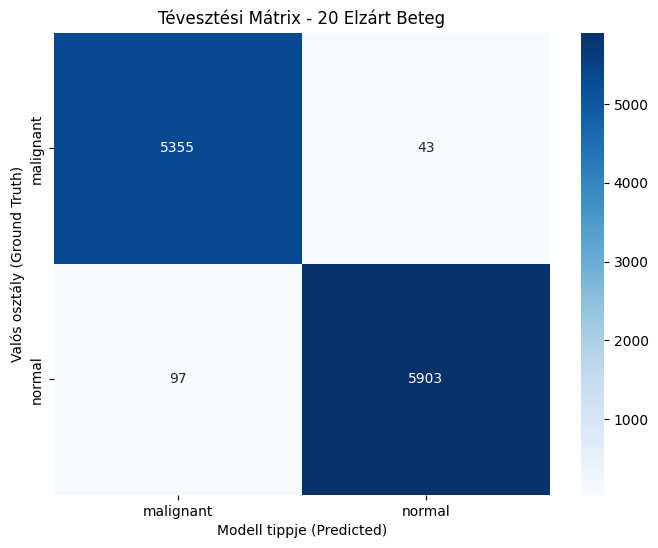


--- Részletes Osztályozási Jelentés ---
              precision    recall  f1-score   support

   malignant       0.98      0.99      0.99      5398
      normal       0.99      0.98      0.99      6000

    accuracy                           0.99     11398
   macro avg       0.99      0.99      0.99     11398
weighted avg       0.99      0.99      0.99     11398



In [ ]:
# Listák a predikciók és a valós címkék gyűjtéséhez
all_preds = []
all_labels = []

print("Predikciók kigyűjtése a Tévesztési Mátrixhoz...")
model.eval()
with torch.no_grad():
    for inputs, labels in val_dataloader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)

        # A GPU-ról áthúzzuk a CPU-ra, majd numpy tömbbé alakítjuk a sklearn számára
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Mátrix kiszámítása
cm = confusion_matrix(all_labels, all_preds)

# Grafikus kirajzolás
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=val_dataset.classes,
            yticklabels=val_dataset.classes)
plt.ylabel('Valós osztály (Ground Truth)')
plt.xlabel('Modell tippje (Predicted)')
plt.title('Tévesztési Mátrix - 20 Elzárt Beteg')
plt.show()

# Részletes statisztika (Precision, Recall, F1)
print("\n--- Részletes Osztályozási Jelentés ---")
print(classification_report(all_labels, all_preds, target_names=val_dataset.classes))

In [ ]:
torch.save(model.state_dict(), '/content/drive/MyDrive/Diplomamunka/resnet50_baseline_98_77.pth')
print("Modell súlyok sikeresen mentve a Drive-ra!")

Modell súlyok sikeresen mentve a Drive-ra!


### Migrálunk AWS S3-ra mindent

In [1]:
!curl "https://awscli.amazonaws.com/awscli-exe-linux-x86_64.zip" -o "awscliv2.zip" > /dev/null
!unzip -q awscliv2.zip
!sudo ./aws/install --update > /dev/null
!rm -rf aws awscliv2.zip

!aws --version

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 71.2M  100 71.2M    0     0   161M      0 --:--:-- --:--:-- --:--:--  161M
aws-cli/2.39.3 Python/3.14.8 Linux/6.6.159+ exe/x86_64.ubuntu.24


In [ ]:
!aws configure set aws_access_key_id "-"
!aws configure set aws_secret_access_key "-"
!aws configure set default.region "eu-north-1"

# Teszteljük a listázást és egyetlen tesztfájl feltöltését
!aws s3 ls s3://diplomamunka-patches-2026/
#!echo "teszt" > /content/test.txt
#!aws s3 cp /content/test.txt s3://diplomamunka-patches-2026/test.txt

                           PRE Dataset/
2026-10-12 08:27:20 1422407680 Dataset_sub_90k.tar
2026-10-07 03:46:16     603245 baseline_sgd_model.joblib
2026-10-13 17:37:34    1706325 custom_cnn_best_checkpoint.pth
2026-10-17 10:24:13    1706439 custom_cnn_sub180k_checkpoint.pth
2026-10-17 10:40:48    1706401 custom_cnn_sub90k_checkpoint.pth
2026-10-06 18:19:37 6865827840 dataset.tar
2026-10-12 08:01:44 2861260800 dataset_sub_180k.tar
2026-10-07 14:11:03       4205 mil_sliding_sgd_block16.joblib
2026-10-07 16:34:10   94372453 resnet50_best_checkpoint.pth
2026-10-12 08:16:31   94373431 resnet50_sub180k_checkpoint.pth
2026-10-12 08:34:55   94373105 resnet50_sub90k_checkpoint.pth
2026-10-07 15:22:24    1205357 sgd_model_w_laplace.joblib
2026-10-21 15:28:06          6 test.txt


In [ ]:
from google.colab import drive
drive.flush_and_unmount()
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


In [ ]:
import os
import time

os.environ["AWS_ACCESS_KEY_ID"] = "-"
os.environ["AWS_SECRET_ACCESS_KEY"] = "-"
os.environ["AWS_DEFAULT_REGION"] = "eu-north-1"

BUCKET = "diplomamunka-patches-2026"

print("1/3: Adatok letöltése S3-ról a Colab lemezére...")
!aws configure set default.s3.max_concurrent_requests 30
!aws s3 sync s3://{BUCKET}/Dataset /content/Dataset --only-show-errors

print("2/3: Archívum (dataset.tar) létrehozása helyben...")
!tar -cf /content/dataset.tar -C /content Dataset

print("3/3: dataset.tar feltöltése az S3 bucketbe a jövőbeli futtatásokhoz...")
!aws s3 cp /content/dataset.tar s3://{BUCKET}/dataset.tar

print("KÉSZ! A dataset.tar mostantól S3-ban.")
print("A lokális fájlok készen állnak: /content/Dataset mappában.")

1/3: Adatok letöltése S3-ról a Colab lemezére...
2/3: Archívum (dataset.tar) létrehozása helyben...
3/3: dataset.tar feltöltése az S3 bucketbe a jövőbeli futtatásokhoz...
upload: ./dataset.tar to s3://diplomamunka-patches-2026/dataset.tar
✅ KÉSZ! A dataset.tar mostantól S3-ban.
A lokális fájlok készen állnak: /content/Dataset mappában.


In [ ]:
import os
import time

os.environ["AWS_ACCESS_KEY_ID"] = "-"
os.environ["AWS_SECRET_ACCESS_KEY"] = "-"
os.environ["AWS_DEFAULT_REGION"] = "eu-north-1"

BUCKET_NAME = "diplomamunka-patches-2026"
TAR_FILE = "dataset.tar"

print("1/2: Archívum letöltése S3-ról...")
start_time = time.time()
!aws s3 cp s3://{BUCKET_NAME}/{TAR_FILE} /content/{TAR_FILE}
print(f"Letöltés kész: {time.time() - start_time:.1f} mp alatt.")

print("\n2/2: Kicsomagolás a lokális lemezre...")
extract_start = time.time()
!tar -xf /content/{TAR_FILE} -C /content/
print(f"Kicsomagolás kész: {time.time() - extract_start:.1f} mp alatt.")

!rm -f /content/{TAR_FILE}

!ls -lh /content/Dataset

1/2: Archívum letöltése S3-ról...
download: s3://diplomamunka-patches-2026/dataset.tar to ./dataset.tar
Letöltés kész: 90.9 mp alatt.

2/2: Kicsomagolás a lokális lemezre...
Kicsomagolás kész: 96.8 mp alatt.
total 683M
-rw-r--r-- 1 root root 2.8K Sep 23 12:22 checkpoint_normal.txt
-rw-r--r-- 1 root root 1.4K Sep 23 12:22 checkpoint_test.txt
-rw-r--r-- 1 root root 511M Sep 23 12:22 mini_dataset_10_percent.zip
drwxr-xr-x 4 root root 4.0K Oct  6 17:21 test
-rw-r--r-- 1 root root 172M Sep 23 12:22 test_dataset.zip
drwxr-xr-x 4 root root 4.0K Oct  6 17:46 train
-rw-r--r-- 1 root root  17K Sep 23 12:22 tumor_checkpoint.txt


In [9]:
import numpy as np

labels = [label for _, label in test_files]

unique_classes, counts = np.unique(labels, return_counts=True)

class_names = train_dataset.classes if 'train_dataset' in globals() else ['Malignant', 'Normal']

print("=== TESZTHALMAZ OSZTÁLY-MEGOSZLÁSA ===")
for class_idx, count in zip(unique_classes, counts):
    name = class_names[class_idx]
    pct = (count / len(test_files)) * 100
    print(f"Teszt halmaz - {name} (címke: {class_idx}): {count:,} db patch ({pct:.2f}%)")

=== TESZTHALMAZ OSZTÁLY-MEGOSZLÁSA ===
Teszt halmaz - Malignant (címke: 0): 6,000 db patch (52.64%)
Teszt halmaz - Normal (címke: 1): 5,398 db patch (47.36%)


mentett modellek/súlyok betöltése colab memóriába:

In [ ]:
import joblib
import os

MODEL_FILENAME = "baseline_sgd_model.joblib"
BUCKET_NAME = "diplomamunka-patches-2026"

# 1. Betanított modell letöltése S3-ról
!aws s3 cp s3://{BUCKET_NAME}/{MODEL_FILENAME} /content/{MODEL_FILENAME}

# 2. Betöltés közvetlenül a memóriába
clf = joblib.load(f"/content/{MODEL_FILENAME}")
print("Kész.")

download: s3://diplomamunka-patches-2026/baseline_sgd_model.joblib to ./baseline_sgd_model.joblib
Kész.


In [ ]:
import joblib
import os

MODEL_FILENAME = "sgd_model_w_laplace.joblib"
BUCKET_NAME = "diplomamunka-patches-2026"

# 1. Betanított modell letöltése S3-ról
!aws s3 cp s3://{BUCKET_NAME}/{MODEL_FILENAME} /content/{MODEL_FILENAME}

# 2. Betöltés közvetlenül a memóriába
clf = joblib.load(f"/content/{MODEL_FILENAME}")
print("Kész.")

download: s3://diplomamunka-patches-2026/sgd_model_w_laplace.joblib to ./sgd_model_w_laplace.joblib
Kész.


In [ ]:
import joblib
import os

MODEL_FILENAME = "mil_sliding_sgd_block16.joblib"
BUCKET_NAME = "diplomamunka-patches-2026"

# 1. Betanított modell letöltése S3-ról
!aws s3 cp s3://{BUCKET_NAME}/{MODEL_FILENAME} /content/{MODEL_FILENAME}

# 2. Betöltés közvetlenül a memóriába
clf = joblib.load(f"/content/{MODEL_FILENAME}")
print("Kész.")

download: s3://diplomamunka-patches-2026/mil_sliding_sgd_block16.joblib to ./mil_sliding_sgd_block16.joblib
Kész.


fájl listák stb:

In [7]:
import random
import os
import glob
# 1. Fájllisták és címkék összegyűjtése
def get_file_list(base_dir):
    file_list = []
    classes = {'normal': 0, 'malignant': 1}
    for cls_name, cls_label in classes.items():
        pattern = os.path.join(base_dir, cls_name, "*.jpg")
        files = glob.glob(pattern)
        for f in files:
            file_list.append((f, cls_label))
    random.seed(42)
    random.shuffle(file_list)  # Fontos a keverés, hogy vegyesen kapja az osztályokat!
    return file_list

train_files = get_file_list("/content/Dataset/train")
test_files = get_file_list("/content/Dataset/test")

print(f"Tanító képek száma: {len(train_files):,} db")
print(f"Teszt képek száma:   {len(test_files):,} db")

Tanító képek száma: 358,399 db
Teszt képek száma:   11,398 db


Alap regressziós vizsgálat:

In [ ]:
import os
import glob
import random
import numpy as np
from PIL import Image
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import time



def batch_generator(file_list, batch_size=1000):
    for i in range(0, len(file_list), batch_size):
        batch = file_list[i : i + batch_size]
        X_batch, y_batch = [], []

        for fpath, label in batch:
            try:
                with Image.open(fpath) as img:
                    img = img.convert("RGB")
                    arr = np.asarray(img, dtype=np.float32) / 255.0
                    X_batch.append(arr.flatten())
                    y_batch.append(label)
            except Exception as e:

                continue

        yield np.array(X_batch, dtype=np.float32), np.array(y_batch, dtype=np.int64)

# loss='log_loss' -> logisztikus regresszió sztochasztikus gradienssel
clf = SGDClassifier(loss='log_loss', penalty='l2', alpha=1e-4, random_state=42)
all_classes = np.array([0, 1])

BATCH_SIZE = 1000
total_batches = (len(train_files) + BATCH_SIZE - 1) // BATCH_SIZE

print(f"\nTanítás indítása {total_batches} kötegben (Batch size: {BATCH_SIZE})...")
start_time = time.time()

for batch_idx, (X_batch, y_batch) in enumerate(batch_generator(train_files, BATCH_SIZE)):
    # partial_fit frissíti a súlyokat anélkül, hogy elfelejtené az eddig tanultakat
    clf.partial_fit(X_batch, y_batch, classes=all_classes)

    if (batch_idx + 1) % 10 == 0 or (batch_idx + 1) == total_batches:
        processed_images = min((batch_idx + 1) * BATCH_SIZE, len(train_files))
        elapsed = time.time() - start_time
        print(f"[{batch_idx + 1}/{total_batches}] {processed_images:,} kép feldolgozva ({elapsed:.1f} mp)...")

print(f"\nModell tanítása befejeződött: {time.time() - start_time:.1f} másodperc alatt.")

print("\nTesztelés folyamatban...")
all_preds = []
all_probs = []
all_y_test = []

for X_test_batch, y_test_batch in batch_generator(test_files, BATCH_SIZE):
    preds = clf.predict(X_test_batch)
    probs = clf.predict_proba(X_test_batch)[:, 1]

    all_preds.extend(preds)
    all_probs.extend(probs)
    all_y_test.extend(y_test_batch)

all_preds = np.array(all_preds)
all_probs = np.array(all_probs)
all_y_test = np.array(all_y_test)

print("\n=== EREDMÉNYEK A TELJES TESZTHALMAZON ===")
print(classification_report(all_y_test, all_preds, target_names=['Normal', 'Malignant'], digits=4))
print(f"ROC-AUC pontszám: {roc_auc_score(all_y_test, all_probs):.4f}")
print("Tévesztési mátrix:")
print(confusion_matrix(all_y_test, all_preds))

Tanító képek száma: 358,399 db
Teszt képek száma:   11,398 db

🚀 Tanítás indítása 359 kötegben (Batch size: 1000)...
[10/359] 10,000 kép feldolgozva (39.4 mp)...
[20/359] 20,000 kép feldolgozva (71.1 mp)...
[30/359] 30,000 kép feldolgozva (103.6 mp)...
[40/359] 40,000 kép feldolgozva (132.8 mp)...
[50/359] 50,000 kép feldolgozva (161.2 mp)...
[60/359] 60,000 kép feldolgozva (195.2 mp)...
[70/359] 70,000 kép feldolgozva (225.6 mp)...
[80/359] 80,000 kép feldolgozva (253.7 mp)...
[90/359] 90,000 kép feldolgozva (280.9 mp)...
[100/359] 100,000 kép feldolgozva (306.9 mp)...
[110/359] 110,000 kép feldolgozva (333.0 mp)...
[120/359] 120,000 kép feldolgozva (359.6 mp)...
[130/359] 130,000 kép feldolgozva (386.4 mp)...
[140/359] 140,000 kép feldolgozva (414.1 mp)...
[150/359] 150,000 kép feldolgozva (440.9 mp)...
[160/359] 160,000 kép feldolgozva (467.3 mp)...
[170/359] 170,000 kép feldolgozva (493.4 mp)...
[180/359] 180,000 kép feldolgozva (519.8 mp)...
[190/359] 190,000 kép feldolgozva (546.

1. Modell sikeresen betöltve: baseline_sgd_model.joblib (Dimenzió: 150528)


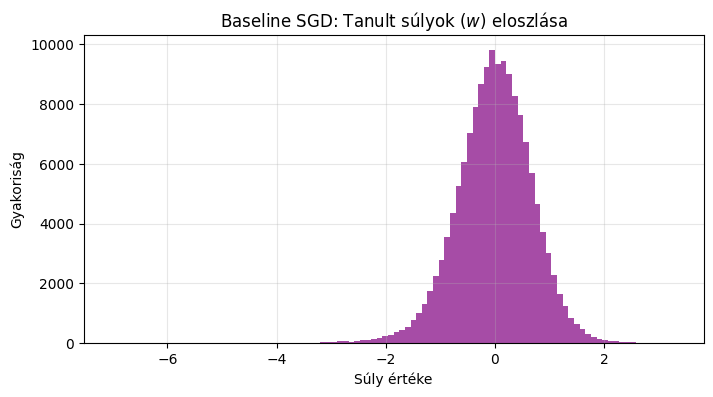

In [ ]:
MODEL_FILE_1 = "baseline_sgd_model.joblib"
BUCKET_NAME = "diplomamunka-patches-2026"

clf_1 = joblib.load(f"/content/{MODEL_FILE_1}")
print(f"1. Modell sikeresen betöltve: {MODEL_FILE_1} (Dimenzió: {clf_1.coef_.shape[1]})")
plt.figure(figsize=(8, 4))
plt.hist(clf_1.coef_[0], bins=100, color='purple', alpha=0.7)
plt.title("Baseline SGD: Tanult súlyok ($w$) eloszlása")
plt.xlabel("Súly értéke")
plt.ylabel("Gyakoriság")
plt.grid(True, alpha=0.3)
plt.savefig("baseline_weights_hist.png", dpi=300)
plt.show()

1. Modell sikeresen betöltve: baseline_sgd_model.joblib (Dimenzió: 150528)


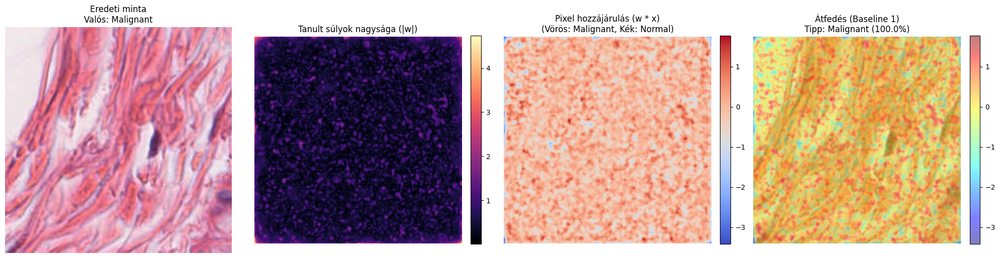

In [ ]:
import os
import joblib
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

MODEL_FILE_1 = "baseline_sgd_model.joblib"
BUCKET_NAME = "diplomamunka-patches-2026"

clf_1 = joblib.load(f"/content/{MODEL_FILE_1}")
print(f"1. Modell sikeresen betöltve: {MODEL_FILE_1} (Dimenzió: {clf_1.coef_.shape[1]})")

sample_path, true_label = test_files[0]
with Image.open(sample_path) as img:
    raw_img = img.convert("RGB")
    img_arr = np.asarray(raw_img, dtype=np.float32) / 255.0

x_flat = img_arr.flatten()

pred_class = clf_1.predict([x_flat])[0]
pred_prob = clf_1.predict_proba([x_flat])[0][1]

weights_1 = clf_1.coef_[0]
spatial_weight = np.mean(np.abs(weights_1.reshape(img_arr.shape)), axis=2)
contribution_map = np.mean((weights_1 * x_flat).reshape(img_arr.shape), axis=2)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(raw_img)
axes[0].set_title(f"Eredeti minta\nValós: {'Malignant' if true_label==1 else 'Normal'}")
axes[0].axis("off")

im1 = axes[1].imshow(spatial_weight, cmap="magma")
axes[1].set_title("Tanult súlyok nagysága (|w|)")
axes[1].axis("off")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(contribution_map, cmap="coolwarm")
axes[2].set_title("Pixel hozzájárulás (w * x)\n(Vörös: Malignant, Kék: Normal)")
axes[2].axis("off")
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

axes[3].imshow(raw_img)
im3 = axes[3].imshow(contribution_map, cmap="jet", alpha=0.5)
axes[3].set_title(f"Átfedés (Baseline 1)\nTipp: {'Malignant' if pred_class==1 else 'Normal'} ({pred_prob*100:.1f}%)")
axes[3].axis("off")
fig.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig("viz_1_flatten.png", dpi=300)
plt.show()

In [ ]:
import joblib

MODEL_FILENAME = "baseline_sgd_model.joblib"

joblib.dump(clf, MODEL_FILENAME)
print(f"Modell elmentve helyben: {MODEL_FILENAME}")

!aws s3 cp {MODEL_FILENAME} s3://{BUCKET_NAME}/{MODEL_FILENAME}
print(f"Kész! s3://{BUCKET_NAME}/{MODEL_FILENAME}")

Modell elmentve helyben: baseline_sgd_model.joblib
upload: ./baseline_sgd_model.joblib to s3://diplomamunka-patches-2026/baseline_sgd_model.joblib
✅ Kész! A modell felkerült az S3-ba: s3://diplomamunka-patches-2026/baseline_sgd_model.joblib


Regressziós vizsgálat, plusz feature-ök segítségével:

In [ ]:
def extract_context_features(img_arr):
    """
    Bemenet: (H, W, 3) normalizált float32 kép
    Környezeti műveletek:
      - Szürkeárnyalatos luminancia
      - Vízszintes és függőleges élek (Sobel) -> lokális környezeti kontraszt
      - Laplace-operátor -> pontszerű sejtmag-gócok detektálása
    Kimenet: Lapított összefűzött 1D vektor
    """
    # Szürkeárnyalatos konverzió a sejtstruktúra elemzéséhez
    gray = 0.299 * img_arr[:, :, 0] + 0.587 * img_arr[:, :, 1] + 0.114 * img_arr[:, :, 2]

    # Lokális élek és környezeti gradiensek számítása
    edge_x = sobel(gray, axis=0)
    edge_y = sobel(gray, axis=1)
    lap = laplace(gray)

    # 224x224x3 (RGB) + 224x224 (SobelX) + 224x224 (SobelY) + 224x224 (Laplace)
    features = np.concatenate([
        img_arr.flatten(),   # Nyers színértékek (150 528 elem)
        edge_x.flatten(),    # Vízszintes környezeti élek (50 176 elem)
        edge_y.flatten(),    # Függőleges környezeti élek (50 176 elem)
        lap.flatten()        # Lokális sejtmag-kiemelés (50 176 elem)
    ])
    return features


In [ ]:
import os
import glob
import random
import time
import numpy as np
from PIL import Image
from scipy.ndimage import sobel, laplace
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

def get_file_list(base_dir):
    file_list = []
    classes = {'normal': 0, 'malignant': 1}
    for cls_name, cls_label in classes.items():
        pattern = os.path.join(base_dir, cls_name, "*.jpg")
        files = glob.glob(pattern)
        for f in files:
            file_list.append((f, cls_label))
    random.seed(42)
    random.shuffle(file_list)
    return file_list

train_files = get_file_list("/content/Dataset/train")
test_files = get_file_list("/content/Dataset/test")

print(f"Tanító képek száma: {len(train_files):,} db")
print(f"Teszt képek száma:   {len(test_files):,} db")

def extract_context_features(img_arr):
    """
    Bemenet: (H, W, 3) normalizált float32 kép
    Környezeti műveletek:
      - Szürkeárnyalatos luminancia
      - Vízszintes és függőleges élek (Sobel) -> lokális környezeti kontraszt
      - Laplace-operátor -> pontszerű sejtmag-gócok detektálása
    Kimenet: Lapított összefűzött 1D vektor
    """
    # Szürkeárnyalatos konverzió a sejtstruktúra elemzéséhez
    gray = 0.299 * img_arr[:, :, 0] + 0.587 * img_arr[:, :, 1] + 0.114 * img_arr[:, :, 2]

    # Lokális élek és környezeti gradiensek számítása
    edge_x = sobel(gray, axis=0)
    edge_y = sobel(gray, axis=1)
    lap = laplace(gray)

    # 224x224x3 (RGB) + 224x224 (SobelX) + 224x224 (SobelY) + 224x224 (Laplace)
    features = np.concatenate([
        img_arr.flatten(),   # Nyers színértékek (150 528 elem)
        edge_x.flatten(),    # Vízszintes környezeti élek (50 176 elem)
        edge_y.flatten(),    # Függőleges környezeti élek (50 176 elem)
        lap.flatten()        # Lokális sejtmag-kiemelés (50 176 elem)
    ])
    return features

def batch_generator(file_list, batch_size=500):
    for i in range(0, len(file_list), batch_size):
        batch = file_list[i : i + batch_size]
        X_batch, y_batch = [], []

        for fpath, label in batch:
            try:
                with Image.open(fpath) as img:
                    img = img.convert("RGB")
                    arr = np.asarray(img, dtype=np.float32) / 255.0
                    feat_vector = extract_context_features(arr)
                    X_batch.append(feat_vector)
                    y_batch.append(label)
            except Exception:
                continue

        yield np.array(X_batch, dtype=np.float32), np.array(y_batch, dtype=np.int64)

clf = SGDClassifier(loss='log_loss', penalty='l2', alpha=1e-4, random_state=42)
all_classes = np.array([0, 1])

BATCH_SIZE = 500  # 301 056 dimenzió/kép miatt az 500-as batch méret kényelmesen elfér a RAM-ban
total_batches = (len(train_files) + BATCH_SIZE - 1) // BATCH_SIZE

print(f"\nTanítás indítása lokális környezeti jellemzőkkel ({total_batches} köteg)...")
start_time = time.time()

for batch_idx, (X_batch, y_batch) in enumerate(batch_generator(train_files, BATCH_SIZE)):
    clf.partial_fit(X_batch, y_batch, classes=all_classes)

    if (batch_idx + 1) % 10 == 0 or (batch_idx + 1) == total_batches:
        processed_images = min((batch_idx + 1) * BATCH_SIZE, len(train_files))
        elapsed = time.time() - start_time
        print(f"[{batch_idx + 1}/{total_batches}] {processed_images:,} kép kész ({elapsed:.1f} mp)...")

print(f"\nModell tanítása befejeződött: {time.time() - start_time:.1f} másodperc alatt.")

print("\nTesztelés folyamatban...")
all_preds, all_probs, all_y_test = [], [], []

for X_test_batch, y_test_batch in batch_generator(test_files, BATCH_SIZE):
    preds = clf.predict(X_test_batch)
    probs = clf.predict_proba(X_test_batch)[:, 1]

    all_preds.extend(preds)
    all_probs.extend(probs)
    all_y_test.extend(y_test_batch)

all_preds = np.array(all_preds)
all_probs = np.array(all_probs)
all_y_test = np.array(all_y_test)

print("\n=== EREDMÉNYEK A TELJES TESZTHALMAZON (KÖRNYEZETI JELLEMZŐKKEL BŐVÍTVE) ===")
print(classification_report(all_y_test, all_preds, target_names=['Normal', 'Malignant'], digits=4))
print(f"ROC-AUC pontszám: {roc_auc_score(all_y_test, all_probs):.4f}")
print("Tévesztési mátrix:")
print(confusion_matrix(all_y_test, all_preds))

Tanító képek száma: 358,399 db
Teszt képek száma:   11,398 db

Tanítás indítása lokális környezeti jellemzőkkel (717 köteg)...
[10/717] 5,000 kép kész (42.8 mp)...
[20/717] 10,000 kép kész (80.4 mp)...
[30/717] 15,000 kép kész (118.1 mp)...
[40/717] 20,000 kép kész (155.6 mp)...
[50/717] 25,000 kép kész (191.9 mp)...
[60/717] 30,000 kép kész (227.1 mp)...
[70/717] 35,000 kép kész (261.5 mp)...
[80/717] 40,000 kép kész (296.2 mp)...
[90/717] 45,000 kép kész (330.6 mp)...
[100/717] 50,000 kép kész (365.2 mp)...
[110/717] 55,000 kép kész (398.3 mp)...
[120/717] 60,000 kép kész (446.1 mp)...
[130/717] 65,000 kép kész (481.1 mp)...
[140/717] 70,000 kép kész (516.9 mp)...
[150/717] 75,000 kép kész (551.5 mp)...
[160/717] 80,000 kép kész (586.0 mp)...
[170/717] 85,000 kép kész (621.5 mp)...
[180/717] 90,000 kép kész (658.1 mp)...
[190/717] 95,000 kép kész (692.7 mp)...
[200/717] 100,000 kép kész (727.7 mp)...
[210/717] 105,000 kép kész (761.2 mp)...
[220/717] 110,000 kép kész (795.6 mp)...
[2

2. Modell sikeresen betöltve: sgd_model_w_laplace.joblib (Dimenzió: 301056)


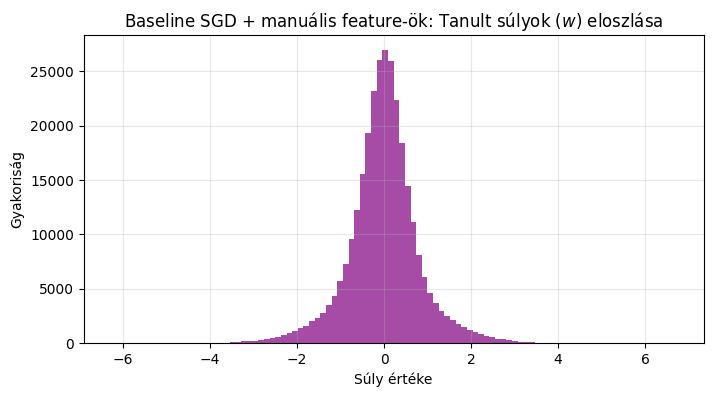

In [ ]:
import matplotlib.pyplot as plt

MODEL_FILE_1 = "sgd_model_w_laplace.joblib"

clf_2 = joblib.load(f"/content/{MODEL_FILE_1}")
print(f"2. Modell sikeresen betöltve: {MODEL_FILE_1} (Dimenzió: {clf_2.coef_.shape[1]})")
plt.figure(figsize=(8, 4))
plt.hist(clf_2.coef_[0], bins=100, color='purple', alpha=0.7)
plt.title("Baseline SGD + manuális feature-ök: Tanult súlyok ($w$) eloszlása")
plt.xlabel("Súly értéke")
plt.ylabel("Gyakoriság")
plt.grid(True, alpha=0.3)
plt.savefig("baseline_weights_hist.png", dpi=300)
plt.show()

2. Modell sikeresen betöltve: sgd_model_w_laplace.joblib (Dimenzió: 301056)


/tmp/ipykernel_708/453788927.py:61: UserWarning: Adding colorbar to a different Figure <Figure size 2000x500 with 7 Axes> than <Figure size 2000x500 with 7 Axes> which fig.colorbar is called on.
  fig.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)


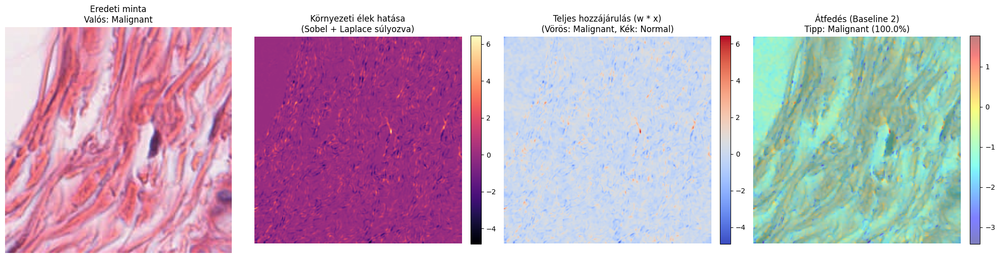

In [ ]:
import os
import joblib
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import sobel, laplace

MODEL_FILE_2 = "sgd_model_w_laplace.joblib"
BUCKET_NAME = "diplomamunka-patches-2026"

clf_2 = joblib.load(f"/content/{MODEL_FILE_2}")
print(f"2. Modell sikeresen betöltve: {MODEL_FILE_2} (Dimenzió: {clf_2.coef_.shape[1]})")

sample_path, true_label = test_files[0]
with Image.open(sample_path) as img:
    raw_img = img.convert("RGB")
    img_arr = np.asarray(raw_img, dtype=np.float32) / 255.0

feat_vector = extract_context_features(img_arr)

# Predikció a clf_2 modellel
pred_class = clf_2.predict([feat_vector])[0]
pred_prob = clf_2.predict_proba([feat_vector])[0][1]

weights_2 = clf_2.coef_[0]
w_rgb = weights_2[:150528].reshape((224, 224, 3))
w_sobel_x = weights_2[150528:200704].reshape((224, 224))
w_sobel_y = weights_2[200704:250880].reshape((224, 224))
w_laplace = weights_2[250880:].reshape((224, 224))

gray = 0.299 * img_arr[:, :, 0] + 0.587 * img_arr[:, :, 1] + 0.114 * img_arr[:, :, 2]
contrib_rgb = np.mean(w_rgb * img_arr, axis=2)
contrib_edges = (w_sobel_x * sobel(gray, axis=0) +
                 w_sobel_y * sobel(gray, axis=1) +
                 w_laplace * laplace(gray))
total_contribution = contrib_rgb + contrib_edges

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(raw_img)
axes[0].set_title(f"Eredeti minta\nValós: {'Malignant' if true_label==1 else 'Normal'}")
axes[0].axis("off")

im1 = axes[1].imshow(contrib_edges, cmap="magma")
axes[1].set_title("Környezeti élek hatása\n(Sobel + Laplace súlyozva)")
axes[1].axis("off")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(total_contribution, cmap="coolwarm")
axes[2].set_title("Teljes hozzájárulás (w * x)\n(Vörös: Malignant, Kék: Normal)")
axes[2].axis("off")
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

axes[3].imshow(raw_img)
imr3 = axes[3].imshow(total_contribution, cmap="jet", alpha=0.5)
axes[3].set_title(f"Átfedés (Baseline 2)\nTipp: {'Malignant' if pred_class==1 else 'Normal'} ({pred_prob*100:.1f}%)")
axes[3].axis("off")
fig.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig("viz_2_context.png", dpi=300)
plt.show()

In [ ]:
import joblib

MODEL_FILENAME = "sgd_model_w_laplace.joblib"

joblib.dump(clf, MODEL_FILENAME)
print(f"Modell elmentve helyben: {MODEL_FILENAME}")

# 2. Feltöltés az S3 bucketbe
!aws s3 cp {MODEL_FILENAME} s3://{BUCKET_NAME}/{MODEL_FILENAME}
print(f"Kész! s3://{BUCKET_NAME}/{MODEL_FILENAME}")

Modell elmentve helyben: sgd_model_w_laplace.joblib
upload: ./sgd_model_w_laplace.joblib to s3://diplomamunka-patches-2026/sgd_model_w_laplace.joblib
Kész! s3://diplomamunka-patches-2026/sgd_model_w_laplace.joblib


Blokkonkénti regressziós vizsgálat:

In [ ]:
import os
import glob
import random
import time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

BLOCK_SIZE = 16  # 16x16-os csempék (16*16*3 = 768 jellemző blokkonként)
GRID_COUNT = 224 // BLOCK_SIZE  # 14x14 = 196 blokk képenként

def extract_blocks_from_image(img_arr, block_size=16):
    """
    (224, 224, 3) méretű képből (N, 768) méretű tömböt készít.
    """
    blocks = []
    for y in range(0, 224 - block_size + 1, block_size):
        for x in range(0, 224 - block_size + 1, block_size):
            block = img_arr[y:y + block_size, x:x + block_size, :]
            blocks.append(block.flatten())
    return np.array(blocks, dtype=np.float32)

def block_batch_generator(file_list, batch_size=200):
    for i in range(0, len(file_list), batch_size):
        batch = file_list[i : i + batch_size]
        X_blocks, y_blocks = [], []

        for fpath, label in batch:
            try:
                with Image.open(fpath) as img:
                    arr = np.asarray(img.convert("RGB"), dtype=np.float32) / 255.0
                    blocks = extract_blocks_from_image(arr, BLOCK_SIZE)
                    X_blocks.append(blocks)
                    # A patch címkéjét rendeljük a benne lévő blokkokhoz (Weak Supervision)
                    y_blocks.append(np.full(len(blocks), label, dtype=np.int64))
            except Exception:
                continue

        if X_blocks:
            yield np.vstack(X_blocks), np.concatenate(y_blocks)

block_clf = SGDClassifier(loss='log_loss', penalty='l2', alpha=1e-4, random_state=42)
all_classes = np.array([0, 1])

print(f"Blokk-alapú tanítás indítása (Blokkméret: {BLOCK_SIZE}x{BLOCK_SIZE}, 768 dimenzió)...")
start_time = time.time()

for b_idx, (X_b, y_b) in enumerate(block_batch_generator(train_files, batch_size=200)):
    block_clf.partial_fit(X_b, y_b, classes=all_classes)
    if (b_idx + 1) % 15 == 0:
        print(f"Tanítás: {(b_idx + 1) * 200:,} kép blokkjai feldolgozva...")

print(f"Tanítás kész: {time.time() - start_time:.1f} mp alatt!")

print("\nTesztelés folyamatban...")
all_preds, all_probs, all_y_test = [], [], []

for fpath, label in test_files:
    try:
        with Image.open(fpath) as img:
            arr = np.asarray(img.convert("RGB"), dtype=np.float32) / 255.0
            blocks = extract_blocks_from_image(arr, BLOCK_SIZE)

            # Minden blokkra számolunk egy valószínűséget
            block_probs = block_clf.predict_proba(blocks)[:, 1]

            # ÖSSZESÍTÉS: a leggyanúsabb felső 15% blokk átlaga
            # Ez adja a teljes kép végső daganatos valószínűségét
            top_k_count = max(1, int(len(block_probs) * 0.15))
            patch_prob = np.mean(np.sort(block_probs)[-top_k_count:])

            all_probs.append(patch_prob)
            all_preds.append(1 if patch_prob > 0.5 else 0)
            all_y_test.append(label)
    except Exception:
        continue

print("\n=== EREDMÉNYEK (BLOKK-ALAPÚ SLIDING REGRESSZIÓ) ===")
print(classification_report(all_y_test, all_preds, target_names=['Normal', 'Malignant'], digits=4))
print(f"ROC-AUC pontszám: {roc_auc_score(all_y_test, all_probs):.4f}")
print("Tévesztési mátrix:")
print(confusion_matrix(all_y_test, all_preds))

Blokk-alapú tanítás indítása (Blokkméret: 16x16, 768 dimenzió)...
Tanítás: 3,000 kép blokkjai feldolgozva...
Tanítás: 6,000 kép blokkjai feldolgozva...
Tanítás: 9,000 kép blokkjai feldolgozva...
Tanítás: 12,000 kép blokkjai feldolgozva...
Tanítás: 15,000 kép blokkjai feldolgozva...
Tanítás: 18,000 kép blokkjai feldolgozva...
Tanítás: 21,000 kép blokkjai feldolgozva...
Tanítás: 24,000 kép blokkjai feldolgozva...
Tanítás: 27,000 kép blokkjai feldolgozva...
Tanítás: 30,000 kép blokkjai feldolgozva...
Tanítás: 33,000 kép blokkjai feldolgozva...
Tanítás: 36,000 kép blokkjai feldolgozva...
Tanítás: 39,000 kép blokkjai feldolgozva...
Tanítás: 42,000 kép blokkjai feldolgozva...
Tanítás: 45,000 kép blokkjai feldolgozva...
Tanítás: 48,000 kép blokkjai feldolgozva...
Tanítás: 51,000 kép blokkjai feldolgozva...
Tanítás: 54,000 kép blokkjai feldolgozva...
Tanítás: 57,000 kép blokkjai feldolgozva...
Tanítás: 60,000 kép blokkjai feldolgozva...
Tanítás: 63,000 kép blokkjai feldolgozva...
Tanítás: 66,0

3. Modell sikeresen betöltve: mil_sliding_sgd_block16.joblib (Dimenzió: 768)


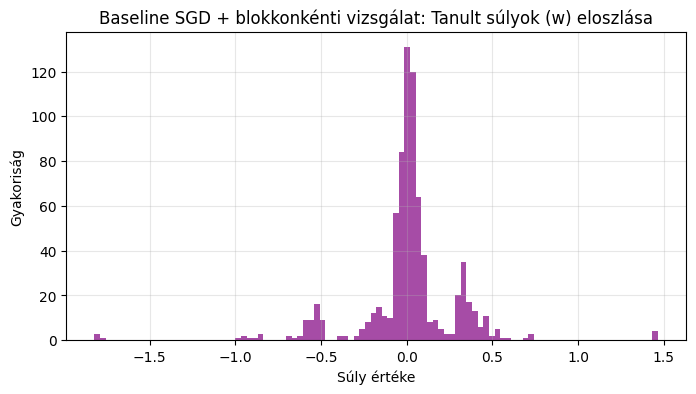

In [ ]:
MODEL_FILE_1 = "mil_sliding_sgd_block16.joblib"

clf_3 = joblib.load(f"/content/{MODEL_FILE_1}")
print(f"3. Modell sikeresen betöltve: {MODEL_FILE_1} (Dimenzió: {clf_3.coef_.shape[1]})")
plt.figure(figsize=(8, 4))
plt.hist(clf_3.coef_[0], bins=100, color='purple', alpha=0.7)
plt.title("Baseline SGD + blokkonkénti vizsgálat: Tanult súlyok (w) eloszlása")
plt.xlabel("Súly értéke")
plt.ylabel("Gyakoriság")
plt.grid(True, alpha=0.3)
plt.savefig("baseline_weights_hist.png", dpi=300)
plt.show()

3. Modell sikeresen betöltve: mil_sliding_sgd_block16.joblib (Dimenzió: 768)


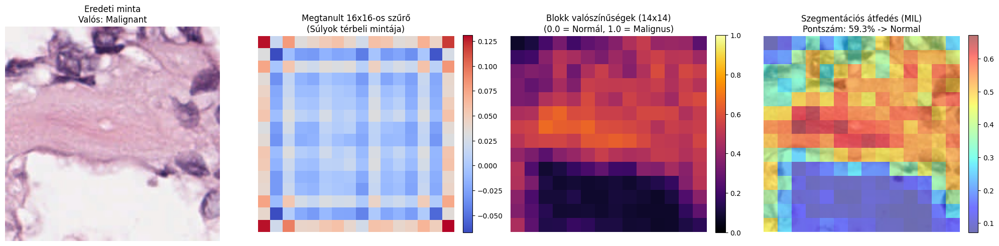

In [ ]:
import os
import joblib
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

MODEL_FILE_3 = "mil_sliding_sgd_block16.joblib"
BUCKET_NAME = "diplomamunka-patches-2026"

clf_3 = joblib.load(f"/content/{MODEL_FILE_3}")
print(f"3. Modell sikeresen betöltve: {MODEL_FILE_3} (Dimenzió: {clf_3.coef_.shape[1]})")

sample_path, true_label = test_files[0]
with Image.open(sample_path) as img:
    raw_img = img.convert("RGB")
    img_arr = np.asarray(raw_img, dtype=np.float32) / 255.0

blocks = extract_blocks_from_image(img_arr, BLOCK_SIZE)
block_probs = clf_3.predict_proba(blocks)[:, 1]

# 14x14-es valószínűségi térkép
heatmap = block_probs.reshape((GRID_COUNT, GRID_COUNT))

# A tanult 16x16-os szűrő
filter_weights = clf_3.coef_[0].reshape((BLOCK_SIZE, BLOCK_SIZE, 3))
spatial_filter = np.mean(filter_weights, axis=2)

# Top-15% átlagolás és a hangolt 0.7180-as küszöb
top_k_count = max(1, int(len(block_probs) * 0.15))
patch_prob = np.mean(np.sort(block_probs)[-top_k_count:])
pred_is_mal = patch_prob >= 0.7180

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(raw_img)
axes[0].set_title(f"Eredeti minta\nValós: {'Malignant' if true_label==1 else 'Normal'}")
axes[0].axis("off")

im1 = axes[1].imshow(spatial_filter, cmap="coolwarm")
axes[1].set_title("Megtanult 16x16-os szűrő\n(Súlyok térbeli mintája)")
axes[1].axis("off")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(heatmap, cmap="inferno", vmin=0, vmax=1)
axes[2].set_title(f"Blokk valószínűségek ({GRID_COUNT}x{GRID_COUNT})\n(0.0 = Normál, 1.0 = Malignus)")
axes[2].axis("off")
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

axes[3].imshow(raw_img)
im3 = axes[3].imshow(heatmap, cmap="jet", alpha=0.55, extent=[0, 224, 224, 0])
axes[3].set_title(f"Szegmentációs átfedés (MIL)\nPontszám: {patch_prob*100:.1f}% -> {'Malignant' if pred_is_mal else 'Normal'}")
axes[3].axis("off")
fig.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig("viz_3_sliding_blocks.png", dpi=300)
plt.show()

a ROC-on látszik hogy jó irányban vagyunk, azonban a kódba égetett threshold = 0.5 miatt az accuracy nagyon gyenge lett
Meg akarom találni az optimális thresholdot:

In [ ]:
import joblib

BUCKET_NAME = "diplomamunka-patches-2026"
MODEL_FILENAME = "mil_sliding_sgd_block16.joblib"

print(f"\nModell mentése: {MODEL_FILENAME}...")
joblib.dump(block_clf, MODEL_FILENAME)
!aws s3 cp {MODEL_FILENAME} s3://{BUCKET_NAME}/{MODEL_FILENAME}
print(f"Modell biztonságban elmentve az S3-ba: s3://{BUCKET_NAME}/{MODEL_FILENAME}")


Modell mentése: mil_sliding_sgd_block16.joblib...
upload: ./mil_sliding_sgd_block16.joblib to s3://diplomamunka-patches-2026/mil_sliding_sgd_block16.joblib
Modell biztonságban elmentve az S3-ba: s3://diplomamunka-patches-2026/mil_sliding_sgd_block16.joblib


In [ ]:
from sklearn.metrics import roc_curve

# 1. Optimális küszöb megkeresése (Youden's J statistic)
fpr, tpr, thresholds = roc_curve(all_y_test, all_probs)
optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]

print(f"Az optimális döntési küszöb: {optimal_threshold:.4f} (a fix 0.5 helyett)")

optimal_preds = (np.array(all_probs) >= optimal_threshold).astype(int)

print("\n=== EREDMÉNYEK AZ OPTIMÁLIS KÜSZÖBBEL ===")
print(classification_report(all_y_test, optimal_preds, target_names=['Normal', 'Malignant'], digits=4))
print("Javított tévesztési mátrix:")
print(confusion_matrix(all_y_test, optimal_preds))

Az optimális döntési küszöb: 0.7180 (a fix 0.5 helyett)

=== EREDMÉNYEK AZ OPTIMÁLIS KÜSZÖBBEL ===
              precision    recall  f1-score   support

      Normal     0.8992    0.7965    0.8447      6000
   Malignant     0.7993    0.9007    0.8470      5398

    accuracy                         0.8459     11398
   macro avg     0.8492    0.8486    0.8458     11398
weighted avg     0.8519    0.8459    0.8458     11398

Javított tévesztési mátrix:
[[4779 1221]
 [ 536 4862]]


## RESNET-50, Transfer Learning:

In [ ]:
import os
import time
import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from torchvision.models import ResNet50_Weights
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# 1. Beállítások és GPU ellenőrzése
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Számítási eszköz: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU Típus: {torch.cuda.get_device_name(0)}")

BUCKET_NAME = "diplomamunka-patches-2026"
CHECKPOINT_NAME = "resnet50_best_checkpoint.pth"

BATCH_SIZE = 64
NUM_WORKERS = 4
NUM_EPOCHS = 3
TRAIN_DIR = "/content/Dataset/train"
TEST_DIR = "/content/Dataset/test"

# 2. Transzformációk
train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=(0, 180)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 3. Teljes adathalmaz betöltése
print("\nAdathalmaz indexelése...")
train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transforms)
test_dataset = datasets.ImageFolder(TEST_DIR, transform=test_transforms)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)

print(f"Tanító képek: {len(train_dataset):,} db | Osztályok: {train_dataset.class_to_idx}")
print(f"Teszt képek:   {len(test_dataset):,} db")
################################################################################

model = models.resnet50(weights=ResNet50_Weights.DEFAULT)

num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 2)
model = model.to(DEVICE)

################################################################################
# 5. Különböző learning rate az FC fejnek és a gerincnek
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW([
    {'params': [p for n, p in model.named_parameters() if 'fc' not in n], 'lr': 1e-5},
    {'params': model.fc.parameters(), 'lr': 1e-3}
], weight_decay=1e-2)

scaler = torch.cuda.amp.GradScaler()  # Vegyes pontosság

# 6. Tanítási és validációs ciklus
best_auc = 0.0
print(f"\nResNet-50 finomhangolás indítása ({NUM_EPOCHS} epoch)...")
start_all = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.time()

    # --- TANÍTÁSI FÁZIS ---
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for batch_idx, (inputs, labels) in enumerate(train_loader):
        inputs, labels = inputs.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        # FP16 Forward pass
        with torch.cuda.amp.autocast():
            outputs = model(inputs)
            loss = criterion(outputs, labels)

        # Backward pass skálázással
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data).item()
        total += labels.size(0)

        if (batch_idx + 1) % 500 == 0:
            print(f"Epoch [{epoch}/{NUM_EPOCHS}] | Batch [{batch_idx+1}/{len(train_loader)}] "
                  f"| Loss: {running_loss/total:.4f} | Acc: {correct/total*100:.2f}%")

    train_epoch_loss = running_loss / total
    train_epoch_acc = correct / total

    # --- KIÉRTÉKELÉSI FÁZIS ---
    model.eval()
    val_labels = []
    val_probs = []
    val_preds = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)
            with torch.cuda.amp.autocast():
                outputs = model(inputs)
                probs = torch.softmax(outputs, dim=1)

            val_labels.extend(labels.cpu().numpy())
            val_probs.extend(probs[:, 1].cpu().numpy())
            val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())

    val_auc = roc_auc_score(val_labels, val_probs)
    val_acc = np.mean(np.array(val_labels) == np.array(val_preds))

    elapsed = time.time() - epoch_start
    print(f"\n Epoch {epoch} Kész ({elapsed:.1f} mp):")
    print(f"  Train Loss: {train_epoch_loss:.4f} | Train Acc: {train_epoch_acc*100:.2f}%")
    print(f"  Val Acc:    {val_acc*100:.2f}% | Val AUC:   {val_auc:.4f}")

    # Mentés, ha ez az eddigi legjobb AUC
    if val_auc > best_auc:
        best_auc = val_auc
        print(f"Új legjobb AUC ({val_auc:.4f})! Modell mentése...")
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'val_auc': val_auc,
            'val_acc': val_acc
        }, CHECKPOINT_NAME)
        #szinkronizálás S3-ra
        !aws s3 cp {CHECKPOINT_NAME} s3://{BUCKET_NAME}/{CHECKPOINT_NAME}
        print(f"S3 szinkron kész: s3://{BUCKET_NAME}/{CHECKPOINT_NAME}\n")

print(f" Teljes futásidő: {time.time() - start_all:.1f} másodperc.")

Számítási eszköz: cuda
GPU Típus: Tesla T4

Adathalmaz indexelése...
Tanító képek: 358,399 db | Osztályok: {'malignant': 0, 'normal': 1}
Teszt képek:   11,398 db

ResNet-50 finomhangolás indítása (3 epoch)...


/tmp/ipykernel_1362/3587611290.py:69: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()  # Vegyes pontosság
/tmp/ipykernel_1362/3587611290.py:90: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch [1/3] | Batch [500/5600] | Loss: 0.0866 | Acc: 97.05%
Epoch [1/3] | Batch [1000/5600] | Loss: 0.0565 | Acc: 98.04%
Epoch [1/3] | Batch [1500/5600] | Loss: 0.0438 | Acc: 98.48%
Epoch [1/3] | Batch [2000/5600] | Loss: 0.0366 | Acc: 98.72%
Epoch [1/3] | Batch [2500/5600] | Loss: 0.0317 | Acc: 98.90%
Epoch [1/3] | Batch [3000/5600] | Loss: 0.0283 | Acc: 99.02%
Epoch [1/3] | Batch [3500/5600] | Loss: 0.0256 | Acc: 99.11%
Epoch [1/3] | Batch [4000/5600] | Loss: 0.0233 | Acc: 99.19%
Epoch [1/3] | Batch [4500/5600] | Loss: 0.0215 | Acc: 99.24%
Epoch [1/3] | Batch [5000/5600] | Loss: 0.0201 | Acc: 99.30%
Epoch [1/3] | Batch [5500/5600] | Loss: 0.0188 | Acc: 99.34%


/tmp/ipykernel_1362/3587611290.py:120: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



 Epoch 1 Kész (1669.3 mp):
  Train Loss: 0.0186 | Train Acc: 99.35%
  Val Acc:    99.50% | Val AUC:   1.0000
Új legjobb AUC (1.0000)! Modell mentése...
upload: ./resnet50_best_checkpoint.pth to s3://diplomamunka-patches-2026/resnet50_best_checkpoint.pth
S3 szinkron kész: s3://diplomamunka-patches-2026/resnet50_best_checkpoint.pth



/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/tmp/ipykernel_1362/3587611290.py:90: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch [2/3] | Batch [500/5600] | Loss: 0.0053 | Acc: 99.82%


KeyboardInterrupt: 

Kiértékelés:

In [ ]:
import os
import torch
import numpy as np
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BUCKET_NAME = "diplomamunka-patches-2026"
CHECKPOINT_NAME = "resnet50_best_checkpoint.pth"

# 1. Checkpoint letöltése, ha nincs a helyi lemezen
if not os.path.exists(CHECKPOINT_NAME):
    !aws s3 cp s3://{BUCKET_NAME}/{CHECKPOINT_NAME} /content/{CHECKPOINT_NAME}

# 2. Modell felépítése és súlyok betöltése
model = models.resnet50(weights=None)
model.fc = torch.nn.Linear(model.fc.in_features, 2)

# JAVÍTÁS: weights_only=False hozzáadása az UnpicklingError elkerülésére
checkpoint = torch.load(CHECKPOINT_NAME, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model = model.to(DEVICE)
model.eval()
print(f"Betöltve: {CHECKPOINT_NAME} (Mentett AUC: {checkpoint['val_auc']:.4f})")

# 3. Teljes teszthalmaz kiértékelése
test_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
test_dataset = datasets.ImageFolder("/content/Dataset/test", transform=test_transforms)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=4)

all_preds, all_probs, all_targets = [], [], []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(DEVICE)
        outputs = model(inputs)
        probs = torch.softmax(outputs, dim=1)

        all_targets.extend(labels.numpy())
        all_probs.extend(probs[:, 1].cpu().numpy())
        all_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())

# 4. Statisztikák kiírása
print("\n=== RESNET-50 EREDMÉNYEK A TELJES TESZTHALMAZON ===")
print(classification_report(all_targets, all_preds, target_names=['Normal', 'Malignant'], digits=4))
print(f"ROC-AUC pontszám: {roc_auc_score(all_targets, all_probs):.4f}")
print("Tévesztési mátrix:")
print(confusion_matrix(all_targets, all_preds))

Betöltve: resnet50_best_checkpoint.pth (Mentett AUC: 1.0000)


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()



=== RESNET-50 EREDMÉNYEK A TELJES TESZTHALMAZON ===
              precision    recall  f1-score   support

      Normal     0.9899    0.9998    0.9948      5398
   Malignant     0.9998    0.9908    0.9953      6000

    accuracy                         0.9951     11398
   macro avg     0.9949    0.9953    0.9951     11398
weighted avg     0.9951    0.9951    0.9951     11398

ROC-AUC pontszám: 1.0000
Tévesztési mátrix:
[[5397    1]
 [  55 5945]]


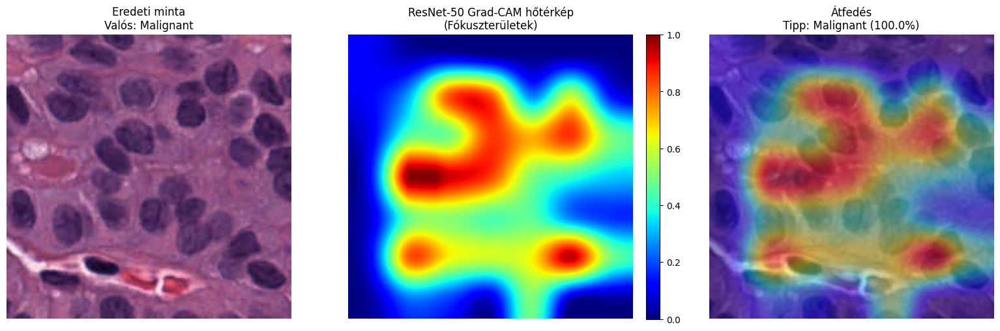

Vizsgált fájl: /content/Dataset/test/malignant/tumor_TCGA-BJ-A4O9_85344_75488.jpg
Valódi predikció: Malignant (100.00%)
Részletes valószínűségek -> Malignant (0): 100.00%, Normal (1): 0.00%


In [ ]:
import os
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import models, transforms

# 1. Beállítások és modell betöltése
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_NAME = "resnet50_best_checkpoint.pth"
BUCKET_NAME = "diplomamunka-patches-2026"

if not os.path.exists(CHECKPOINT_NAME):
    !aws s3 cp s3://{BUCKET_NAME}/{CHECKPOINT_NAME} /content/{CHECKPOINT_NAME}

model = models.resnet50(weights=None)
model.fc = torch.nn.Linear(model.fc.in_features, 2)

checkpoint = torch.load(CHECKPOINT_NAME, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model = model.to(DEVICE)
model.eval()
class_names = {0: "Malignant", 1: "Normal"}

target_layer = model.layer4[-1]

activations = []
gradients = []

def forward_hook(module, input, output):
    activations.append(output)

def backward_hook(module, grad_in, grad_out):
    gradients.append(grad_out[0])

target_layer.register_forward_hook(forward_hook)
target_layer.register_full_backward_hook(backward_hook)

# 3. Referencia tesztkép előkészítése
sample_path, true_label = test_files[0]
raw_img = Image.open(sample_path).convert("RGB")

preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

input_tensor = preprocess(raw_img).unsqueeze(0).to(DEVICE)

# 4. Forward és Backward pass
activations.clear()
gradients.clear()

output = model(input_tensor)
probs = F.softmax(output, dim=1).squeeze().detach().cpu().numpy()
pred_class = torch.argmax(output, dim=1).item()

# Csak egyszer futtatjuk le a backward-ot, és előtte nullázzuk a gradienseket
model.zero_grad()
score = output[0, pred_class]
score.backward()

# Gradiens átlagolása csatornánként (Global Average Pooling a gradienseken)
pooled_gradients = torch.mean(gradients[0], dim=[0, 2, 3])
act = activations[0].squeeze(0)

# Súlyozott összegzés a feature map-eken
cam = torch.zeros(act.shape[1:], dtype=torch.float32, device=DEVICE)
for i in range(len(pooled_gradients)):
    cam += pooled_gradients[i] * act[i]

# Csak a pozitív hozzájárulások megtartása (ReLU) és normalizálás
cam = F.relu(cam)
cam = cam.detach().cpu().numpy()
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

# Visszaskálázás az eredeti kép méretére (224x224)
cam_resized = Image.fromarray(np.uint8(255 * cam)).resize((raw_img.width, raw_img.height), Image.BICUBIC)
cam_resized = np.asarray(cam_resized) / 255.0

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# (A) Eredeti kép
axes[0].imshow(raw_img)
axes[0].set_title(f"Eredeti minta\nValós: {'Malignant' if true_label==1 else 'Normal'}")
axes[0].axis("off")

# (B) Nyers Grad-CAM hőtérkép
im1 = axes[1].imshow(cam_resized, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("ResNet-50 Grad-CAM hőtérkép\n(Fókuszterületek)")
axes[1].axis("off")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

# (C) Ráfektetés az eredeti képre
axes[2].imshow(raw_img)
axes[2].imshow(cam_resized, cmap="jet", alpha=0.45)
axes[2].set_title(f"Átfedés\nTipp: {class_names[pred_class]} ({probs[pred_class]*100:.1f}%)")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("viz_resnet50_gradcam.png", dpi=300)
plt.show()

print(f"Vizsgált fájl: {sample_path}")
print(f"Valódi predikció: {class_names[pred_class]} ({probs[pred_class]*100:.2f}%)")
print(f"Részletes valószínűségek -> Malignant (0): {probs[0]*100:.2f}%, Normal (1): {probs[1]*100:.2f}%")

In [ ]:
from torchvision import datasets, transforms, models

TRAIN_DIR = "/content/Dataset/train"
TEST_DIR = "/content/Dataset/test"
train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=(0, 180)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transforms)
test_dataset = datasets.ImageFolder(TEST_DIR, transform=test_transforms)

In [ ]:
print(test_dataset.class_to_idx)

{'malignant': 0, 'normal': 1}


In [ ]:
import glob

patient_id = "TCGA-BJ-A45E"

# Keresés úgy, hogy a fájlnév bármely pontján szerepelhet az azonosító
train_matches = glob.glob(f"/content/Dataset/train/**/*{patient_id}*.jpg", recursive=True)
test_matches = glob.glob(f"/content/Dataset/test/**/*{patient_id}*.jpg", recursive=True)

print(f"Páciens azonosító: {patient_id}")
print(f"Képek száma a train mappában ebből a páciensből: {len(train_matches)} db")
print(f"Képek száma a test mappában ebből a páciensből:  {len(test_matches)} db")

Páciens azonosító: TCGA-BJ-A45E
Képek száma a train mappában ebből a páciensből: 0 db
Képek száma a test mappában ebből a páciensből:  600 db


In [ ]:
import os
import glob
from collections import defaultdict

def extract_patient_id(file_path):
    filename = os.path.basename(file_path)
    for part in filename.split("_"):
        if part.startswith("TCGA-"):
            return part
    return None

train_counts = defaultdict(int)
test_counts = defaultdict(int)

print("Train képek vizsgálata...")
for f in glob.glob("/content/Dataset/train/**/*.jpg", recursive=True):
    pid = extract_patient_id(f)
    if pid:
        train_counts[pid] += 1

print("Test képek vizsgálata...")
for f in glob.glob("/content/Dataset/test/**/*.jpg", recursive=True):
    pid = extract_patient_id(f)
    if pid:
        test_counts[pid] += 1

train_patients = set(train_counts.keys())
test_patients = set(test_counts.keys())
overlap_patients = train_patients.intersection(test_patients)

print("\n" + "="*50)
print("PATIENT LEAKAGE ELLENŐRZÉS")
print("="*50)
print(f"Egyedi páciensek a train mappában: {len(train_patients):>4} db")
print(f"Egyedi páciensek a test mappában:  {len(test_patients):>4} db")
print(f"Átfedő páciensek száma:            {len(overlap_patients):>4} db")

if len(overlap_patients) == 0:
    print("\nTÖKÉLETES: Nincs átfedés!")
else:
    print(f"\n{len(overlap_patients)} páciens mindkét mappában szerepel!")

#Részletes minta több páciensre (pl. 5 teszt és 5 train beteg)
print("\nVéletlenszerű minta a teszthalmaz betegeiből")
sample_test_pids = sorted(list(test_patients))[:5]
for pid in sample_test_pids:
    print(f"Páciens: {pid:<15} | Train: {train_counts[pid]:>4} db | Test: {test_counts[pid]:>4} db")

print("\nVéletlenszerű minta a tanítóhalmaz betegeiből")
sample_train_pids = sorted(list(train_patients))[:5]
for pid in sample_train_pids:
    print(f"Páciens: {pid:<15} | Train: {train_counts[pid]:>4} db | Test: {test_counts[pid]:>4} db")

Train képek vizsgálata...
Test képek vizsgálata...

PATIENT LEAKAGE ELLENŐRZÉS
Egyedi páciensek a train mappában:  454 db
Egyedi páciensek a test mappában:    20 db
Átfedő páciensek száma:               0 db

TÖKÉLETES: Nincs átfedés!

Véletlenszerű minta a teszthalmaz betegeiből
Páciens: TCGA-BJ-A28R    | Train:    0 db | Test:  600 db
Páciens: TCGA-BJ-A45E    | Train:    0 db | Test:  600 db
Páciens: TCGA-BJ-A4O9    | Train:    0 db | Test:  898 db
Páciens: TCGA-E8-A2JQ    | Train:    0 db | Test:  600 db
Páciens: TCGA-EL-A3H7    | Train:    0 db | Test:  600 db

Véletlenszerű minta a tanítóhalmaz betegeiből
Páciens: TCGA-4C-A93U    | Train: 1117 db | Test:    0 db
Páciens: TCGA-BJ-A0YZ    | Train:  373 db | Test:    0 db
Páciens: TCGA-BJ-A0Z0    | Train:  373 db | Test:    0 db
Páciens: TCGA-BJ-A0Z2    | Train:  373 db | Test:    0 db
Páciens: TCGA-BJ-A0Z3    | Train:  746 db | Test:    0 db


### Resnet: tanító adatok megfelezése 360k-> kevesebb mint 180k.

Páciensszintű 50%-os felezés:


In [ ]:
import os
import glob
import random
from collections import defaultdict

SRC_TRAIN_DIR = "/content/Dataset/train"
DST_TRAIN_DIR = "/content/Dataset_sub_180k/train"
DST_TEST_DIR = "/content/Dataset_sub_180k/test"

os.makedirs(os.path.join(DST_TRAIN_DIR, "normal"), exist_ok=True)
os.makedirs(os.path.join(DST_TRAIN_DIR, "malignant"), exist_ok=True)

#Páciensek és fájljaik összegyűjtése osztályonként
def get_patient_to_files(train_dir):
    data = {"normal": defaultdict(list), "malignant": defaultdict(list)}
    for cls in ["normal", "malignant"]:
        for fpath in glob.glob(os.path.join(train_dir, cls, "*.jpg")):
            fname = os.path.basename(fpath)
            # TCGA azonosító kinyerése (pl. TCGA-BJ-A45E)
            patient_id = None
            for part in fname.split("_"):
                if part.startswith("TCGA-"):
                    patient_id = part
                    break
            if patient_id:
                data[cls][patient_id].append(fpath)
    return data

patient_dict = get_patient_to_files(SRC_TRAIN_DIR)

#Páciensek felének kiválasztása osztályonként (50% split)
random.seed(42)
selected_files = []

for cls in ["normal", "malignant"]:
    patients = sorted(list(patient_dict[cls].keys()))
    random.shuffle(patients)
    half_count = len(patients) // 2
    chosen_patients = set(patients[:half_count])

    cls_files = 0
    for pid in chosen_patients:
        selected_files.extend([(f, cls) for f in patient_dict[cls][pid]])
        cls_files += len(patient_dict[cls][pid])

    print(f"[{cls.upper()}] Összes beteg: {len(patients)} -> Kiválasztva: {half_count} beteg ({cls_files:,} kép)")

print(f"\nÖsszes kiválasztott tanító kép: {len(selected_files):,} db")

#Fájlok linkelése az új könyvtárba
for src_path, cls in selected_files:
    fname = os.path.basename(src_path)
    dst_path = os.path.join(DST_TRAIN_DIR, cls, fname)
    if not os.path.exists(dst_path):
        os.link(src_path, dst_path)

# A teszthalmaz változatlanul marad, szimbolikus linkkel becsatoljuk
if not os.path.exists(DST_TEST_DIR):
    os.symlink("/content/Dataset/test", DST_TEST_DIR)

print("Új könyvtárstruktúra elkészült: /content/Dataset_sub_180k")

[NORMAL] Összes beteg: 77 -> Kiválasztva: 38 beteg (85,930 kép)
[MALIGNANT] Összes beteg: 450 -> Kiválasztva: 225 beteg (86,028 kép)

Összes kiválasztott tanító kép: 171,958 db
Új könyvtárstruktúra elkészült: /content/Dataset_sub_180k


A teszthalmaz változatlan kell maradjon: Ha a tanítóhalmaz viselkedését vizsgálom, a teszthalmaznak változatlannak kell maradnia

Subset feltöltése S3-ra:


In [ ]:
BUCKET_NAME = "diplomamunka-patches-2026"
ARCHIVE_NAME = "dataset_sub_180k.tar"

print("Archiválás folyamatban...")
!tar -cf /content/{ARCHIVE_NAME} -C /content/Dataset_sub_180k train

print("Feltöltés AWS S3-ra...")
!aws s3 cp /content/{ARCHIVE_NAME} s3://{BUCKET_NAME}/{ARCHIVE_NAME}
print(f"Sikeres mentés: s3://{BUCKET_NAME}/{ARCHIVE_NAME}")

Archiválás folyamatban...
Feltöltés AWS S3-ra...
upload: ./dataset_sub_180k.tar to s3://diplomamunka-patches-2026/dataset_sub_180k.tar
Sikeres mentés: s3://diplomamunka-patches-2026/dataset_sub_180k.tar


később a letöltéshez:

In [ ]:
import os
import time

os.environ["AWS_ACCESS_KEY_ID"] = "-"
os.environ["AWS_SECRET_ACCESS_KEY"] = "-"
os.environ["AWS_DEFAULT_REGION"] = "eu-north-1"

BUCKET_NAME = "diplomamunka-patches-2026"
TAR_FILE = "dataset_sub_180k.tar"

EXTRACT_DIR = os.path.join("/content", os.path.splitext(TAR_FILE)[0])
os.makedirs(EXTRACT_DIR, exist_ok=True)

print("1/2: Archívum letöltése S3-ról...")
start_time = time.time()
!aws s3 cp s3://{BUCKET_NAME}/{TAR_FILE} /content/{TAR_FILE}
print(f"Letöltés kész: {time.time() - start_time:.1f} mp alatt.")

print(f"\n2/2: Kicsomagolás a célkönyvtárba ({EXTRACT_DIR})...")
extract_start = time.time()
!tar -xf /content/{TAR_FILE} -C {EXTRACT_DIR}
print(f"Kicsomagolás kész: {time.time() - extract_start:.1f} mp alatt.")

!rm -f /content/{TAR_FILE}

print(f"\nEredmény: a train mappa mostantól itt található: {EXTRACT_DIR}/train")

1/2: Archívum letöltése S3-ról...
download: s3://diplomamunka-patches-2026/dataset_sub_180k.tar to ./dataset_sub_180k.tar
Letöltés kész: 39.6 mp alatt.

2/2: Kicsomagolás a célkönyvtárba (/content/dataset_sub_180k)...
Kicsomagolás kész: 30.4 mp alatt.

Eredmény: a train mappa mostantól itt található: /content/dataset_sub_180k/train


resnet újra, 50%os adathalmazon:


In [ ]:
import os
import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from torchvision.models import ResNet50_Weights
from sklearn.metrics import roc_auc_score

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Eszköz: {DEVICE} ({torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'})")

BUCKET_NAME = "diplomamunka-patches-2026"
CHECKPOINT_NAME = "resnet50_sub180k_checkpoint.pth"

BATCH_SIZE = 64
NUM_WORKERS = 4
NUM_EPOCHS = 3
TRAIN_DIR_SUB = "/content/Dataset_sub_180k/train"
TEST_DIR_SUB = "/content/Dataset_sub_180k/test"

#Transzformációk
train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=(0, 180)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

#Betöltés
train_dataset = datasets.ImageFolder(TRAIN_DIR_SUB, transform=train_transforms)
test_dataset = datasets.ImageFolder(TEST_DIR_SUB, transform=test_transforms)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)

# Malignant indexének beazonosítása
mal_idx = train_dataset.class_to_idx['malignant']
print(f"Tanító képek (180k subset): {len(train_dataset):,} db")
print(f"Teszt képek száma:           {len(test_dataset):,} db")
print(f"Malignant index: {mal_idx}")

#Modell előkészítése
model = models.resnet50(weights=ResNet50_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 2)
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW([
    {'params': [p for n, p in model.named_parameters() if 'fc' not in n], 'lr': 1e-5},
    {'params': model.fc.parameters(), 'lr': 1e-3}
], weight_decay=1e-2)

scaler = torch.cuda.amp.GradScaler()

#Tanítás
best_auc = 0.0
print(f"\nResNet-50 tanítás indítása felezett halmazon")
start_all = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.time()
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for batch_idx, (inputs, labels) in enumerate(train_loader):
        inputs, labels = inputs.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast():
            outputs = model(inputs)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data).item()
        total += labels.size(0)

        if (batch_idx + 1) % 500 == 0:
            print(f"Epoch [{epoch}/{NUM_EPOCHS}] | Batch [{batch_idx+1}/{len(train_loader)}] "
                  f"| Loss: {running_loss/total:.4f} | Acc: {correct/total*100:.2f}%")

    # Validáció
    model.eval()
    val_labels, val_probs, val_preds = [], [], []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)
            with torch.cuda.amp.autocast():
                outputs = model(inputs)
                probs = torch.softmax(outputs, dim=1)

            val_labels.extend(labels.cpu().numpy())
            # A daganatos osztály pontos valószínűsége
            val_probs.extend(probs[:, mal_idx].cpu().numpy())
            val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())

    # Bináris célcímkék igazítása a ROC-AUC-hoz (1 ha malignant 0 ha normal)
    binary_targets = (np.array(val_labels) == mal_idx).astype(int)
    val_auc = roc_auc_score(binary_targets, val_probs)
    val_acc = np.mean(np.array(val_labels) == np.array(val_preds))

    elapsed = time.time() - epoch_start
    print(f"\nEpoch {epoch} Kész ({elapsed:.1f} mp):")
    print(f"  Train Acc: {correct/total*100:.2f}% | Val Acc: {val_acc*100:.2f}% | Val AUC: {val_auc:.4f}")

    if val_auc > best_auc:
        best_auc = val_auc
        print(f"  Új legjobb AUC ({val_auc:.4f}) mentése...")
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'val_auc': val_auc,
            'val_acc': val_acc
        }, CHECKPOINT_NAME)
        !aws s3 cp {CHECKPOINT_NAME} s3://{BUCKET_NAME}/{CHECKPOINT_NAME}

print(f"Futásidő: {time.time() - start_all:.1f} mp")

Eszköz: cuda (Tesla T4)


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Tanító képek (180k subset): 171,958 db
Teszt képek száma:           11,398 db
Malignant index: 0
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 163MB/s]



ResNet-50 tanítás indítása felezett halmazon


/tmp/ipykernel_913/3745842510.py:63: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/tmp/ipykernel_913/3745842510.py:79: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch [1/3] | Batch [500/2687] | Loss: 0.0871 | Acc: 96.92%
Epoch [1/3] | Batch [1000/2687] | Loss: 0.0581 | Acc: 97.97%
Epoch [1/3] | Batch [1500/2687] | Loss: 0.0447 | Acc: 98.44%
Epoch [1/3] | Batch [2000/2687] | Loss: 0.0369 | Acc: 98.72%
Epoch [1/3] | Batch [2500/2687] | Loss: 0.0318 | Acc: 98.90%


/tmp/ipykernel_913/3745842510.py:103: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



Epoch 1 Kész (749.3 mp):
  Train Acc: 98.96% | Val Acc: 99.56% | Val AUC: 0.9999
  Új legjobb AUC (0.9999) mentése...
upload: ./resnet50_sub180k_checkpoint.pth to s3://diplomamunka-patches-2026/resnet50_sub180k_checkpoint.pth


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/tmp/ipykernel_913/3745842510.py:79: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


KeyboardInterrupt: 

kiértékelés és heatmap

In [ ]:
import os
import torch
import numpy as np
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BUCKET_NAME = "diplomamunka-patches-2026"
CHECKPOINT_NAME = "resnet50_sub180k_checkpoint.pth"

# 1. Checkpoint letöltése, ha nincs a helyi lemezen
if not os.path.exists(CHECKPOINT_NAME):
    !aws s3 cp s3://{BUCKET_NAME}/{CHECKPOINT_NAME} /content/{CHECKPOINT_NAME}

# 2. Modell felépítése és súlyok betöltése
model = models.resnet50(weights=None)
model.fc = torch.nn.Linear(model.fc.in_features, 2)

# JAVÍTÁS: weights_only=False hozzáadása az UnpicklingError elkerülésére
checkpoint = torch.load(CHECKPOINT_NAME, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model = model.to(DEVICE)
model.eval()
print(f"Betöltve: {CHECKPOINT_NAME} (Mentett AUC: {checkpoint['val_auc']:.4f})")

# 3. Teljes teszthalmaz kiértékelése
test_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
test_dataset = datasets.ImageFolder("/content/Dataset/test", transform=test_transforms)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=4)

all_preds, all_probs, all_targets = [], [], []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(DEVICE)
        outputs = model(inputs)
        probs = torch.softmax(outputs, dim=1)

        all_targets.extend(labels.numpy())
        all_probs.extend(probs[:, 1].cpu().numpy())
        all_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())

# 4. Statisztikák kiírása
print("\n=== RESNET-50 EREDMÉNYEK A felezett TESZTHALMAZON ===")
print(classification_report(all_targets, all_preds, target_names=['Normal', 'Malignant'], digits=4))
print(f"ROC-AUC pontszám: {roc_auc_score(all_targets, all_probs):.4f}")
print("Tévesztési mátrix:")
print(confusion_matrix(all_targets, all_preds))

download: s3://diplomamunka-patches-2026/resnet50_sub180k_checkpoint.pth to ./resnet50_sub180k_checkpoint.pth
Betöltve: resnet50_sub180k_checkpoint.pth (Mentett AUC: 0.9999)


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()



=== RESNET-50 EREDMÉNYEK A felezett TESZTHALMAZON ===
              precision    recall  f1-score   support

      Normal     0.9912    0.9996    0.9954      5398
   Malignant     0.9997    0.9920    0.9958      6000

    accuracy                         0.9956     11398
   macro avg     0.9954    0.9958    0.9956     11398
weighted avg     0.9956    0.9956    0.9956     11398

ROC-AUC pontszám: 0.9999
Tévesztési mátrix:
[[5396    2]
 [  48 5952]]


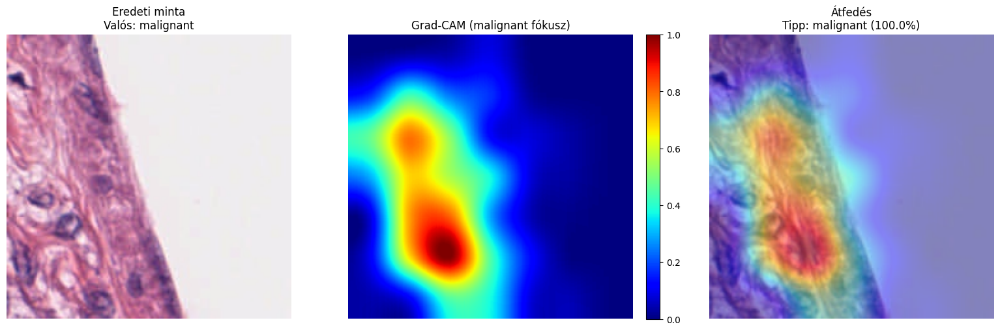

Fájl: /content/Dataset/test/malignant/tumor_TCGA-EL-A3MX_66976_38528.jpg
Predikció: malignant | Malignant valószínűség: 100.00% | Normal: 0.00%


In [ ]:
import os
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import models, transforms

# 1. Beállítások és modell betöltése
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_NAME = "resnet50_sub180k_checkpoint.pth"
BUCKET_NAME = "diplomamunka-patches-2026"

if not os.path.exists(CHECKPOINT_NAME):
    !aws s3 cp s3://{BUCKET_NAME}/{CHECKPOINT_NAME} /content/{CHECKPOINT_NAME}

model = models.resnet50(weights=None)
model.fc = torch.nn.Linear(model.fc.in_features, 2)

checkpoint = torch.load(CHECKPOINT_NAME, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model = model.to(DEVICE)
model.eval()

# 2. Hook-ok regisztrálása
target_layer = model.layer4[-1]
activations = []
gradients = []

def forward_hook(module, input, output):
    activations.append(output)

def backward_hook(module, grad_in, grad_out):
    gradients.append(grad_out[0])

target_layer.register_forward_hook(forward_hook)
target_layer.register_full_backward_hook(backward_hook)

# 3. Minta betöltése
sample_path, true_label = test_files[0]  # Próbálhatod 0-val vagy 1-gyel is
raw_img = Image.open(sample_path).convert("RGB")

preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
input_tensor = preprocess(raw_img).unsqueeze(0).to(DEVICE)

# 4. Forward pass
activations.clear()
gradients.clear()

output = model(input_tensor)
probs = F.softmax(output, dim=1).squeeze().detach().cpu().numpy()
pred_class = torch.argmax(output, dim=1).item()

# Osztálynevek feloldása (0: malignant, 1: normal az ImageFolder sorrendje szerint)
class_labels = {0: "Malignant", 1: "Normal"}

# Mindig a PREDIKÁLT osztály gradiensét vezetjük vissza (amiért a modell úgy döntött, ahogy)
score = output[0, pred_class]
model.zero_grad()
score.backward()

# 5. Grad-CAM kalkuláció (javított operátorokkal)
pooled_gradients = torch.mean(gradients[0], dim=[0, 2, 3])
act = activations[0].squeeze(0)

cam = torch.zeros(act.shape[1:], dtype=torch.float32, device=DEVICE)
for i in range(len(pooled_gradients)):
    cam += pooled_gradients[i] * act[i]

cam = F.relu(cam)
cam = cam.detach().cpu().numpy()
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

cam_resized = Image.fromarray(np.uint8(255 * cam)).resize((raw_img.width, raw_img.height), Image.BICUBIC)
cam_resized = np.asarray(cam_resized) / 255.0

# 6. Megjelenítés
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(raw_img)
axes[0].set_title(f"Eredeti minta\nValós: {test_dataset.classes[pred_class]}")
axes[0].axis("off")

im1 = axes[1].imshow(cam_resized, cmap="jet", vmin=0, vmax=1)
axes[1].set_title(f"Grad-CAM ({test_dataset.classes[pred_class]} fókusz)")
axes[1].axis("off")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

axes[2].imshow(raw_img)
axes[2].imshow(cam_resized, cmap="jet", alpha=0.45)
axes[2].set_title(f"Átfedés\nTipp: {test_dataset.classes[pred_class]} ({probs[pred_class]*100:.1f}%)")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("viz_resnet50_gradcam_sub180k.png", dpi=300)
plt.show()

print(f"Fájl: {sample_path}")
print(f"Predikció: {test_dataset.classes[pred_class]} | Malignant valószínűség: {probs[0]*100:.2f}% | Normal: {probs[1]*100:.2f}%")

resnet újra 25 %-os adathalmazon:

In [ ]:
import os
import glob
import random
from collections import defaultdict

SRC_TRAIN_DIR = "/content/Dataset/train"
DST_TRAIN_DIR = "/content/Dataset_sub_90k/train"
DST_TEST_DIR = "/content/Dataset_sub_90k/test"

os.makedirs(os.path.join(DST_TRAIN_DIR, "normal"), exist_ok=True)
os.makedirs(os.path.join(DST_TRAIN_DIR, "malignant"), exist_ok=True)

#Páciensek és fájljaik összegyűjtése osztályonként
def get_patient_to_files(train_dir):
    data = {"normal": defaultdict(list), "malignant": defaultdict(list)}
    for cls in ["normal", "malignant"]:
        for fpath in glob.glob(os.path.join(train_dir, cls, "*.jpg")):
            fname = os.path.basename(fpath)
            # TCGA azonosító kinyerése (pl. TCGA-BJ-A45E)
            patient_id = None
            for part in fname.split("_"):
                if part.startswith("TCGA-"):
                    patient_id = part
                    break
            if patient_id:
                data[cls][patient_id].append(fpath)
    return data

patient_dict = get_patient_to_files(SRC_TRAIN_DIR)

#Páciensek felének kiválasztása osztályonként (25% split)
random.seed(42)
selected_files = []

for cls in ["normal", "malignant"]:
    patients = sorted(list(patient_dict[cls].keys()))
    random.shuffle(patients)
    half_count = len(patients) // 4
    chosen_patients = set(patients[:half_count])

    cls_files = 0
    for pid in chosen_patients:
        selected_files.extend([(f, cls) for f in patient_dict[cls][pid]])
        cls_files += len(patient_dict[cls][pid])

    print(f"[{cls.upper()}] Összes beteg: {len(patients)} -> Kiválasztva: {half_count} beteg ({cls_files:,} kép)")

print(f"\nÖsszes kiválasztott tanító kép: {len(selected_files):,} db")

#Fájlok linkelése az új könyvtárba
for src_path, cls in selected_files:
    fname = os.path.basename(src_path)
    dst_path = os.path.join(DST_TRAIN_DIR, cls, fname)
    if not os.path.exists(dst_path):
        os.link(src_path, dst_path)

# A teszthalmaz változatlanul marad, szimbolikus linkkel becsatoljuk
if not os.path.exists(DST_TEST_DIR):
    os.symlink("/content/Dataset/test", DST_TEST_DIR)

print("Új könyvtárstruktúra elkészült: /content/Dataset_sub_90k")

[NORMAL] Összes beteg: 77 -> Kiválasztva: 19 beteg (43,314 kép)
[MALIGNANT] Összes beteg: 450 -> Kiválasztva: 112 beteg (43,138 kép)

Összes kiválasztott tanító kép: 86,452 db
Új könyvtárstruktúra elkészült: /content/Dataset_sub_90k


feltöltés s3-ra:

In [ ]:
BUCKET_NAME = "diplomamunka-patches-2026"
ARCHIVE_NAME = "Dataset_sub_90k.tar"

print("Archiválás folyamatban...")
!tar -cf /content/{ARCHIVE_NAME} -C /content/Dataset_sub_90k train

print("Feltöltés AWS S3-ra...")
!aws s3 cp /content/{ARCHIVE_NAME} s3://{BUCKET_NAME}/{ARCHIVE_NAME}
print(f"Sikeres mentés: s3://{BUCKET_NAME}/{ARCHIVE_NAME}")

Archiválás folyamatban...
Feltöltés AWS S3-ra...
upload: ./Dataset_sub_90k.tar to s3://diplomamunka-patches-2026/Dataset_sub_90k.tar
Sikeres mentés: s3://diplomamunka-patches-2026/Dataset_sub_90k.tar


letöltés:

In [ ]:
import os
import time

os.environ["AWS_ACCESS_KEY_ID"] = "-"
os.environ["AWS_SECRET_ACCESS_KEY"] = "-"
os.environ["AWS_DEFAULT_REGION"] = "eu-north-1"

BUCKET_NAME = "diplomamunka-patches-2026"
TAR_FILE = "Dataset_sub_90k.tar"

EXTRACT_DIR = os.path.join("/content", os.path.splitext(TAR_FILE)[0])
os.makedirs(EXTRACT_DIR, exist_ok=True)

print("1/2: Archívum letöltése S3-ról...")
start_time = time.time()
!aws s3 cp s3://{BUCKET_NAME}/{TAR_FILE} /content/{TAR_FILE}
print(f"Letöltés kész: {time.time() - start_time:.1f} mp alatt.")

print(f"\n2/2: Kicsomagolás a célkönyvtárba ({EXTRACT_DIR})...")
extract_start = time.time()
!tar -xf /content/{TAR_FILE} -C {EXTRACT_DIR}
print(f"Kicsomagolás kész: {time.time() - extract_start:.1f} mp alatt.")

!rm -f /content/{TAR_FILE}

print(f"\nEredmény: a train mappa mostantól itt található: {EXTRACT_DIR}/train")

1/2: Archívum letöltése S3-ról...
/bin/bash: line 1: aws: command not found
Letöltés kész: 0.0 mp alatt.

2/2: Kicsomagolás a célkönyvtárba (/content/Dataset_sub_90k)...
tar: /content/Dataset_sub_90k.tar: Cannot open: No such file or directory
tar: Error is not recoverable: exiting now
Kicsomagolás kész: 0.1 mp alatt.

Eredmény: a train mappa mostantól itt található: /content/Dataset_sub_90k/train


tanítás:

In [ ]:
import os
import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from torchvision.models import ResNet50_Weights
from sklearn.metrics import roc_auc_score

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Eszköz: {DEVICE} ({torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'})")

BUCKET_NAME = "diplomamunka-patches-2026"
CHECKPOINT_NAME = "resnet50_sub90k_checkpoint.pth"

BATCH_SIZE = 64
NUM_WORKERS = 4
NUM_EPOCHS = 3
TRAIN_DIR_SUB = "/content/Dataset_sub_90k/train"
TEST_DIR_SUB = "/content/Dataset_sub_90k/test"

#Transzformációk
train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=(0, 180)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

#Betöltés
train_dataset = datasets.ImageFolder(TRAIN_DIR_SUB, transform=train_transforms)
test_dataset = datasets.ImageFolder(TEST_DIR_SUB, transform=test_transforms)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)

# Malignant indexének beazonosítása
mal_idx = train_dataset.class_to_idx['malignant']
print(f"Tanító képek (90k subset): {len(train_dataset):,} db")
print(f"Teszt képek száma:           {len(test_dataset):,} db")
print(f"Malignant index: {mal_idx}")

#Modell előkészítése
model = models.resnet50(weights=ResNet50_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 2)
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW([
    {'params': [p for n, p in model.named_parameters() if 'fc' not in n], 'lr': 1e-5},
    {'params': model.fc.parameters(), 'lr': 1e-3}
], weight_decay=1e-2)

scaler = torch.cuda.amp.GradScaler()

#Tanítás
best_auc = 0.0
print(f"\nResNet-50 tanítás indítása felezett halmazon")
start_all = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.time()
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for batch_idx, (inputs, labels) in enumerate(train_loader):
        inputs, labels = inputs.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast():
            outputs = model(inputs)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data).item()
        total += labels.size(0)

        if (batch_idx + 1) % 500 == 0:
            print(f"Epoch [{epoch}/{NUM_EPOCHS}] | Batch [{batch_idx+1}/{len(train_loader)}] "
                  f"| Loss: {running_loss/total:.4f} | Acc: {correct/total*100:.2f}%")

    # Validáció
    model.eval()
    val_labels, val_probs, val_preds = [], [], []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)
            with torch.cuda.amp.autocast():
                outputs = model(inputs)
                probs = torch.softmax(outputs, dim=1)

            val_labels.extend(labels.cpu().numpy())
            # A daganatos osztály pontos valószínűsége
            val_probs.extend(probs[:, mal_idx].cpu().numpy())
            val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())

    # Bináris célcímkék igazítása a ROC-AUC-hoz (1 ha malignant 0 ha normal)
    binary_targets = (np.array(val_labels) == mal_idx).astype(int)
    val_auc = roc_auc_score(binary_targets, val_probs)
    val_acc = np.mean(np.array(val_labels) == np.array(val_preds))

    elapsed = time.time() - epoch_start
    print(f"\nEpoch {epoch} Kész ({elapsed:.1f} mp):")
    print(f"  Train Acc: {correct/total*100:.2f}% | Val Acc: {val_acc*100:.2f}% | Val AUC: {val_auc:.4f}")

    if val_auc > best_auc:
        best_auc = val_auc
        print(f"  Új legjobb AUC ({val_auc:.4f}) mentése...")
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'val_auc': val_auc,
            'val_acc': val_acc
        }, CHECKPOINT_NAME)
        !aws s3 cp {CHECKPOINT_NAME} s3://{BUCKET_NAME}/{CHECKPOINT_NAME}

print(f"Futásidő: {time.time() - start_all:.1f} mp")

Eszköz: cuda (Tesla T4)


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Tanító képek (90k subset): 86,452 db
Teszt képek száma:           11,398 db
Malignant index: 0

ResNet-50 tanítás indítása felezett halmazon


/tmp/ipykernel_913/638875371.py:63: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/tmp/ipykernel_913/638875371.py:79: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch [1/3] | Batch [500/1351] | Loss: 0.0864 | Acc: 96.81%
Epoch [1/3] | Batch [1000/1351] | Loss: 0.0559 | Acc: 97.98%


/tmp/ipykernel_913/638875371.py:103: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



Epoch 1 Kész (389.6 mp):
  Train Acc: 98.33% | Val Acc: 99.04% | Val AUC: 0.9998
  Új legjobb AUC (0.9998) mentése...
upload: ./resnet50_sub90k_checkpoint.pth to s3://diplomamunka-patches-2026/resnet50_sub90k_checkpoint.pth


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/tmp/ipykernel_913/638875371.py:79: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch [2/3] | Batch [500/1351] | Loss: 0.0132 | Acc: 99.54%
Epoch [2/3] | Batch [1000/1351] | Loss: 0.0114 | Acc: 99.60%


KeyboardInterrupt: 

In [ ]:
import os
import torch
import numpy as np
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BUCKET_NAME = "diplomamunka-patches-2026"
CHECKPOINT_NAME = "resnet50_sub90k_checkpoint.pth"

# 1. Checkpoint letöltése, ha nincs a helyi lemezen
if not os.path.exists(CHECKPOINT_NAME):
    !aws s3 cp s3://{BUCKET_NAME}/{CHECKPOINT_NAME} /content/{CHECKPOINT_NAME}

# 2. Modell felépítése és súlyok betöltése
model = models.resnet50(weights=None)
model.fc = torch.nn.Linear(model.fc.in_features, 2)

# JAVÍTÁS: weights_only=False hozzáadása az UnpicklingError elkerülésére
checkpoint = torch.load(CHECKPOINT_NAME, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model = model.to(DEVICE)
model.eval()
print(f"Betöltve: {CHECKPOINT_NAME} (Mentett AUC: {checkpoint['val_auc']:.4f})")

# 3. Teljes teszthalmaz kiértékelése
test_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
test_dataset = datasets.ImageFolder("/content/Dataset_sub_90k/test", transform=test_transforms)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=4)

all_preds, all_probs, all_targets = [], [], []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(DEVICE)
        outputs = model(inputs)
        probs = torch.softmax(outputs, dim=1)

        all_targets.extend(labels.numpy())
        all_probs.extend(probs[:, 1].cpu().numpy())
        all_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())

# 4. Statisztikák kiírása
print("\n=== RESNET-50 EREDMÉNYEK A TELJES TESZTHALMAZON ===")
print(classification_report(all_targets, all_preds, target_names=['Normal', 'Malignant'], digits=4))
print(f"ROC-AUC pontszám: {roc_auc_score(all_targets, all_probs):.4f}")
print("Tévesztési mátrix:")
print(confusion_matrix(all_targets, all_preds))

Betöltve: resnet50_sub90k_checkpoint.pth (Mentett AUC: 0.9998)


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()



=== RESNET-50 EREDMÉNYEK A TELJES TESZTHALMAZON ===
              precision    recall  f1-score   support

      Normal     0.9816    0.9985    0.9900      5398
   Malignant     0.9986    0.9832    0.9908      6000

    accuracy                         0.9904     11398
   macro avg     0.9901    0.9908    0.9904     11398
weighted avg     0.9906    0.9904    0.9904     11398

ROC-AUC pontszám: 0.9998
Tévesztési mátrix:
[[5390    8]
 [ 101 5899]]


In [ ]:
import random
import glob
# 1. Fájllisták és címkék összegyűjtése
def get_file_list(base_dir):
    file_list = []
    classes = {'normal': 0, 'malignant': 1}
    for cls_name, cls_label in classes.items():
        pattern = os.path.join(base_dir, cls_name, "*.jpg")
        files = glob.glob(pattern)
        for f in files:
            file_list.append((f, cls_label))
    random.seed(42)
    random.shuffle(file_list)  # Fontos a keverés, hogy vegyesen kapja az osztályokat!
    return file_list

train_files = get_file_list("/content/dataset_sub_180k/train")
test_files = get_file_list("/content/Dataset/test")

print(f"Tanító képek száma: {len(train_files):,} db")
print(f"Teszt képek száma:   {len(test_files):,} db")

Tanító képek száma: 171,958 db
Teszt képek száma:   11,398 db


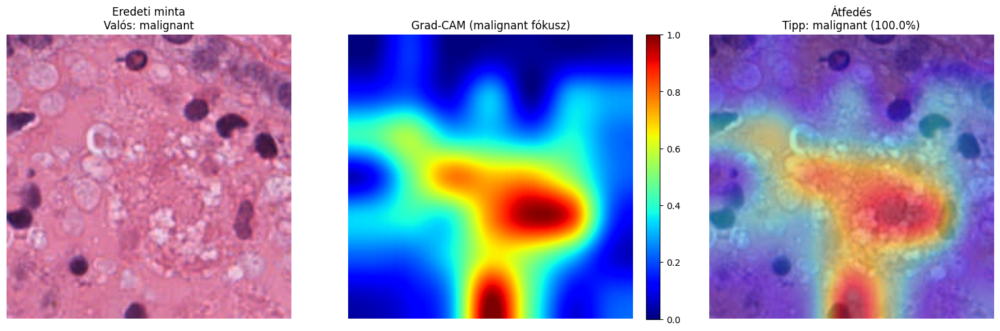

Fájl: /content/Dataset_sub_90k/test/malignant/tumor_TCGA-BJ-A28R_23520_60480.jpg
Predikció: malignant | Malignant valószínűség: 99.99% | Normal: 0.01%


In [ ]:
import os
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import models, transforms

# 1. Beállítások és modell betöltése
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_NAME = "resnet50_sub90k_checkpoint.pth"
BUCKET_NAME = "diplomamunka-patches-2026"

if not os.path.exists(CHECKPOINT_NAME):
    !aws s3 cp s3://{BUCKET_NAME}/{CHECKPOINT_NAME} /content/{CHECKPOINT_NAME}

model = models.resnet50(weights=None)
model.fc = torch.nn.Linear(model.fc.in_features, 2)

checkpoint = torch.load(CHECKPOINT_NAME, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model = model.to(DEVICE)
model.eval()

# 2. Hook-ok regisztrálása
target_layer = model.layer4[-1]
activations = []
gradients = []

def forward_hook(module, input, output):
    activations.append(output)

def backward_hook(module, grad_in, grad_out):
    gradients.append(grad_out[0])

target_layer.register_forward_hook(forward_hook)
target_layer.register_full_backward_hook(backward_hook)

# 3. Minta betöltése
sample_path, true_label = test_files[0]  # Próbálhatod 0-val vagy 1-gyel is
raw_img = Image.open(sample_path).convert("RGB")

preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
input_tensor = preprocess(raw_img).unsqueeze(0).to(DEVICE)

# 4. Forward pass
activations.clear()
gradients.clear()

output = model(input_tensor)
probs = F.softmax(output, dim=1).squeeze().detach().cpu().numpy()
pred_class = torch.argmax(output, dim=1).item()

# Osztálynevek feloldása (0: malignant, 1: normal az ImageFolder sorrendje szerint)
class_labels = {0: "Malignant", 1: "Normal"}

# Mindig a PREDIKÁLT osztály gradiensét vezetjük vissza (amiért a modell úgy döntött, ahogy)
score = output[0, pred_class]
model.zero_grad()
score.backward()

# 5. Grad-CAM kalkuláció (javított operátorokkal)
pooled_gradients = torch.mean(gradients[0], dim=[0, 2, 3])
act = activations[0].squeeze(0)

cam = torch.zeros(act.shape[1:], dtype=torch.float32, device=DEVICE)
for i in range(len(pooled_gradients)):
    cam += pooled_gradients[i] * act[i]

cam = F.relu(cam)
cam = cam.detach().cpu().numpy()
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

cam_resized = Image.fromarray(np.uint8(255 * cam)).resize((raw_img.width, raw_img.height), Image.BICUBIC)
cam_resized = np.asarray(cam_resized) / 255.0

# 6. Megjelenítés
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(raw_img)
axes[0].set_title(f"Eredeti minta\nValós: {test_dataset.classes[pred_class]}")
axes[0].axis("off")

im1 = axes[1].imshow(cam_resized, cmap="jet", vmin=0, vmax=1)
axes[1].set_title(f"Grad-CAM ({test_dataset.classes[pred_class]} fókusz)")
axes[1].axis("off")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

axes[2].imshow(raw_img)
axes[2].imshow(cam_resized, cmap="jet", alpha=0.45)
axes[2].set_title(f"Átfedés\nTipp: {test_dataset.classes[pred_class]} ({probs[pred_class]*100:.1f}%)")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("viz_resnet50_gradcam_sub90k.png", dpi=300)
plt.show()

print(f"Fájl: {sample_path}")
print(f"Predikció: {test_dataset.classes[pred_class]} | Malignant valószínűség: {probs[0]*100:.2f}% | Normal: {probs[1]*100:.2f}%")

In [ ]:
print("ImageFolder indexek:", test_dataset.class_to_idx)
print("Vizsgált kép valódi mappája:", sample_path)
print("Modell nyers kimenete (logits):", output.detach().cpu().numpy())
print("Predikált osztályindex:", pred_class)

ImageFolder indexek: {'malignant': 0, 'normal': 1}
Vizsgált kép valódi mappája: /content/Dataset_sub_90k/test/malignant/tumor_TCGA-BJ-A28R_23520_60480.jpg
Modell nyers kimenete (logits): [[ 4.8335905 -5.052405 ]]
Predikált osztályindex: 0


In [ ]:
import torch
import torch.nn as nn

class CustomCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()

        # (MODULÁRIS) EGY KONVOLÚCIÓS BLOKK
        # Keras megfelelője: Conv2D + BatchNormalization + ReLU + MaxPool2D
        def make_block(in_c, out_c):
            return nn.Sequential(
                nn.Conv2d(in_channels=in_c, out_channels=out_c, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_c),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(kernel_size=2, stride=2)  # Felezi a képméretet (224 -> 112 -> 56 -> 28 -> 14)
            )

        #Feature Extractor rétegek
        # bővítés: blockx, 512 értékkel
        self.block1 = make_block(3, 32)     # Bemenet: 3 csatorna (RGB) -> Kimenet: 32 feature map
        self.block2 = make_block(32, 64)    # 32 -> 64
        self.block3 = make_block(64, 128)   # 64 -> 128
        self.block4 = make_block(128, 256)  # 128 -> 256

        #FIX MÉRETRE HOZÁS
        # A Keras GlobalAveragePooling2D megfelelője
        # Bármekkora is a kép a 4. blokk után, mindig pontosan 1x1-es méretre átlagolja
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        #Classifier / Dense rétegek
        self.classifier = nn.Sequential(
            nn.Dropout(p=0.4),              # Regularizáció a túltanulás ellen
            nn.Linear(256, 128),            # Dense(128)
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.2),
            nn.Linear(128, num_classes)     # Végső kimenet (2 logits: normal, malignant)
        )

    # A "forward" függvény határozza meg, mi történik az adattal, amikor átfolyik a modellen
    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)

        x = self.global_pool(x)       # Alak: [batch_size, 256, 1, 1]
        x = torch.flatten(x, 1)       # Keras Flatten() megfelelője: [batch_size, 256]
        logits = self.classifier(x)   # Alak: [batch_size, 2]
        return logits

# ellenőrzés dummy adaton
test_x = torch.randn(2, 3, 224, 224)
model_demo = CustomCNN(num_classes=2)
out_demo = model_demo(test_x)
print(f"Bemeneti tenzor: {test_x.shape}")
print(f"Kimeneti logits:  {out_demo.shape} (2 minta, 2 osztály)")

Bemeneti tenzor: torch.Size([2, 3, 224, 224])
Kimeneti logits:  torch.Size([2, 2]) (2 minta, 2 osztály)


In [ ]:
import os
import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import roc_auc_score

# 1. Beállítások
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Számítási eszköz: {DEVICE}")

CHECKPOINT_NAME = "custom_cnn_best_checkpoint.pth"
BATCH_SIZE = 64
NUM_WORKERS = 4
NUM_EPOCHS = 3

TRAIN_DIR = "/content/Dataset/train"
TEST_DIR = "/content/Dataset/test"

# 2. Adat-előkészítés
train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=(0, 180)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transforms)
test_dataset = datasets.ImageFolder(TEST_DIR, transform=test_transforms)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)

mal_idx = train_dataset.class_to_idx['malignant']
print(f"Tanító képek: {len(train_dataset):,} db | Teszt képek: {len(test_dataset):,} db")
print(f"Osztályok kiosztása: {train_dataset.class_to_idx} (Malignant index: {mal_idx})")

# 3. Saját CNN példányosítása és optimalizáló
model = CustomCNN(num_classes=2).to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
scaler = torch.cuda.amp.GradScaler()

# 4. Tanítási ciklus
best_auc = 0.0
print(f"\nCNN tanítása ({NUM_EPOCHS} epoch)...")
start_all = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.time()

    # TRAIN FÁZIS
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for batch_idx, (inputs, labels) in enumerate(train_loader):
        inputs, labels = inputs.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast():
            outputs = model(inputs)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data).item()
        total += labels.size(0)

        if (batch_idx + 1) % 500 == 0:
            print(f"Epoch [{epoch}/{NUM_EPOCHS}] | Batch [{batch_idx+1}/{len(train_loader)}] "
                  f"| Loss: {running_loss/total:.4f} | Acc: {correct/total*100:.2f}%")

    #VALIDÁCIÓS FÁZIS
    model.eval()
    val_labels, val_probs, val_preds = [], [], []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)
            with torch.cuda.amp.autocast():
                outputs = model(inputs)
                probs = torch.softmax(outputs, dim=1)

            val_labels.extend(labels.cpu().numpy())
            val_probs.extend(probs[:, mal_idx].cpu().numpy())
            val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())

    binary_targets = (np.array(val_labels) == mal_idx).astype(int)
    val_auc = roc_auc_score(binary_targets, val_probs)
    val_acc = np.mean(np.array(val_labels) == np.array(val_preds))

    elapsed = time.time() - epoch_start
    print(f"\nEpoch {epoch} Kész ({elapsed:.1f} mp):")
    print(f"  Train Acc: {correct/total*100:.2f}% | Val Acc: {val_acc*100:.2f}% | Val AUC: {val_auc:.4f}")

    if val_auc > best_auc:
        best_auc = val_auc
        print(f"  Új legjobb AUC ({val_auc:.4f})! Modell mentése")
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'val_auc': val_auc,
            'val_acc': val_acc
        }, CHECKPOINT_NAME)

print(f"\nTeljes futásidő: {time.time() - start_all:.1f} mp")

Számítási eszköz: cuda
Tanító képek: 358,399 db | Teszt képek: 11,398 db
Osztályok kiosztása: {'malignant': 0, 'normal': 1} (Malignant index: 0)

CNN tanítása (3 epoch)...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/tmp/ipykernel_15601/3863332349.py:53: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation m

Epoch [1/3] | Batch [500/5600] | Loss: 0.1170 | Acc: 95.80%
Epoch [1/3] | Batch [1000/5600] | Loss: 0.0921 | Acc: 96.68%
Epoch [1/3] | Batch [1500/5600] | Loss: 0.0813 | Acc: 97.09%
Epoch [1/3] | Batch [2000/5600] | Loss: 0.0732 | Acc: 97.39%
Epoch [1/3] | Batch [2500/5600] | Loss: 0.0672 | Acc: 97.60%
Epoch [1/3] | Batch [3000/5600] | Loss: 0.0628 | Acc: 97.76%
Epoch [1/3] | Batch [3500/5600] | Loss: 0.0596 | Acc: 97.88%
Epoch [1/3] | Batch [4000/5600] | Loss: 0.0566 | Acc: 97.99%
Epoch [1/3] | Batch [4500/5600] | Loss: 0.0543 | Acc: 98.07%
Epoch [1/3] | Batch [5000/5600] | Loss: 0.0523 | Acc: 98.14%
Epoch [1/3] | Batch [5500/5600] | Loss: 0.0506 | Acc: 98.20%


/tmp/ipykernel_15601/3863332349.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



Epoch 1 Kész (952.2 mp):
  Train Acc: 98.22% | Val Acc: 99.12% | Val AUC: 0.9996
  Új legjobb AUC (0.9996)! Modell mentése


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/tmp/ipykernel_15601/3863332349.py:71: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


... (3 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/tmp/ipykernel_15601/3863332349.py:71: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch [3/3] | Batch [500/5600] | Loss: 0.0239 | Acc: 99.15%
Epoch [3/3] | Batch [1000/5600] | Loss: 0.0221 | Acc: 99.22%
Epoch [3/3] | Batch [1500/5600] | Loss: 0.0216 | Acc: 99.22%
Epoch [3/3] | Batch [2000/5600] | Loss: 0.0217 | Acc: 99.22%
Epoch [3/3] | Batch [2500/5600] | Loss: 0.0217 | Acc: 99.23%
Epoch [3/3] | Batch [3000/5600] | Loss: 0.0212 | Acc: 99.24%
Epoch [3/3] | Batch [3500/5600] | Loss: 0.0210 | Acc: 99.24%
Epoch [3/3] | Batch [4000/5600] | Loss: 0.0205 | Acc: 99.26%
Epoch [3/3] | Batch [4500/5600] | Loss: 0.0205 | Acc: 99.27%
Epoch [3/3] | Batch [5000/5600] | Loss: 0.0202 | Acc: 99.28%
Epoch [3/3] | Batch [5500/5600] | Loss: 0.0201 | Acc: 99.28%


/tmp/ipykernel_15601/3863332349.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



Epoch 3 Kész (944.2 mp):
  Train Acc: 99.29% | Val Acc: 99.39% | Val AUC: 0.9997

Teljes futásidő: 2841.1 mp


In [ ]:
BUCKET_NAME = "diplomamunka-patches-2026"
CHECKPOINT_NAME = "custom_cnn_best_checkpoint.pth"

!aws s3 cp {CHECKPOINT_NAME} s3://{BUCKET_NAME}/{CHECKPOINT_NAME}
print(f"CNN modellcheckpoint elmentve: s3://{BUCKET_NAME}/{CHECKPOINT_NAME}")

upload: ./custom_cnn_best_checkpoint.pth to s3://diplomamunka-patches-2026/custom_cnn_best_checkpoint.pth
CNN modellcheckpoint elmentve: s3://diplomamunka-patches-2026/custom_cnn_best_checkpoint.pth


Sikeresen betöltve a checkpoint! (Menti AUC: 0.9998)

Tanító készlet kiértékelése...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/tmp/ipykernel_420/922119228.py:50: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Teszt készlet kiértékelése...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/tmp/ipykernel_420/922119228.py:50: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



=== EREDMÉNYEK ===
TRAIN -> Loss: 0.0237 | Acc: 99.13% | AUC: 0.9997
TEST  -> Loss: 0.0183 | Acc: 99.36% | AUC: 0.9998


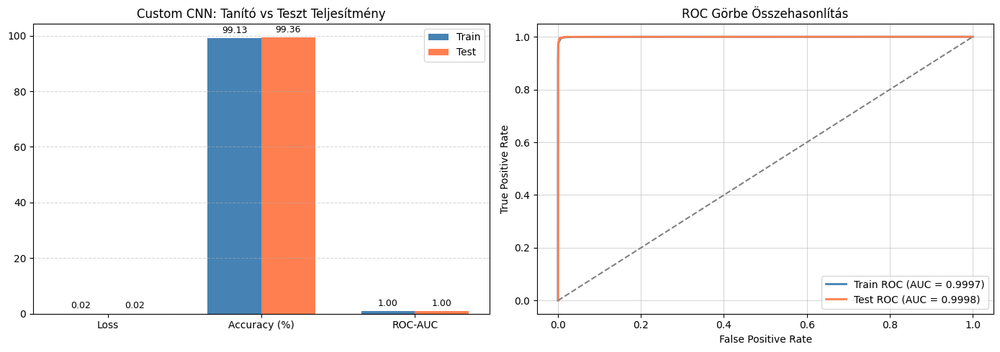

In [ ]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import roc_auc_score, accuracy_score, roc_curve

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_NAME = "custom_cnn_best_checkpoint.pth"
BATCH_SIZE = 64
NUM_WORKERS = 4

TRAIN_DIR = "/content/Dataset/train"
TEST_DIR = "/content/Dataset/test"

eval_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=eval_transforms)
test_dataset = datasets.ImageFolder(TEST_DIR, transform=eval_transforms)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

mal_idx = train_dataset.class_to_idx['malignant']

model = CustomCNN(num_classes=2).to(DEVICE)
checkpoint = torch.load(CHECKPOINT_NAME, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

criterion = nn.CrossEntropyLoss()

print(f"Sikeresen betöltve a checkpoint! (Menti AUC: {checkpoint.get('val_auc', 'N/A'):.4f})")

# 3. Kiértékelő függvény egy tetszőleges DataLoader-re
def evaluate_loader(loader):
    running_loss = 0.0
    all_labels, all_probs, all_preds = [], [], []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)

            with torch.cuda.amp.autocast():
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                probs = F.softmax(outputs, dim=1)

            running_loss += loss.item() * inputs.size(0)
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs[:, mal_idx].cpu().numpy())
            all_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())

    total_samples = len(loader.dataset)
    avg_loss = running_loss / total_samples
    acc = accuracy_score(all_labels, all_preds)

    binary_targets = (np.array(all_labels) == mal_idx).astype(int)
    auc_score = roc_auc_score(binary_targets, all_probs)

    return avg_loss, acc, auc_score, binary_targets, np.array(all_probs)

# 4. Kiértékelés a Tanító és Teszt halmazokon
print("\nTanító készlet kiértékelése...")
train_loss, train_acc, train_auc, train_targets, train_probs = evaluate_loader(train_loader)

print("Teszt készlet kiértékelése...")
test_loss, test_acc, test_auc, test_targets, test_probs = evaluate_loader(test_loader)

print("\n=== EREDMÉNYEK ===")
print(f"TRAIN -> Loss: {train_loss:.4f} | Acc: {train_acc*100:.2f}% | AUC: {train_auc:.4f}")
print(f"TEST  -> Loss: {test_loss:.4f} | Acc: {test_acc*100:.2f}% | AUC: {test_auc:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# A. Train vs Test Metrikák Oszlopdiagramja
metrics = ['Loss', 'Accuracy (%)', 'ROC-AUC']
train_vals = [train_loss, train_acc * 100, train_auc]
test_vals = [test_loss, test_acc * 100, test_auc]

x = np.arange(len(metrics))
width = 0.35

rects1 = axes[0].bar(x - width/2, train_vals, width, label='Train', color='steelblue')
rects2 = axes[0].bar(x + width/2, test_vals, width, label='Test', color='coral')

axes[0].set_title('Custom CNN: Tanító vs Teszt Teljesítmény')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics)
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

for rect in rects1 + rects2:
    height = rect.get_height()
    axes[0].annotate(f'{height:.2f}',
                     xy=(rect.get_x() + rect.get_width() / 2, height),
                     xytext=(0, 3), textcoords="offset points",
                     ha='center', va='bottom', fontsize=9)

# B. ROC Görbék (Train vs Test)
fpr_tr, tpr_tr, _ = roc_curve(train_targets, train_probs)
fpr_te, tpr_te, _ = roc_curve(test_targets, test_probs)

axes[1].plot(fpr_tr, tpr_tr, color='steelblue', lw=2, label=f'Train ROC (AUC = {train_auc:.4f})')
axes[1].plot(fpr_te, tpr_te, color='coral', lw=2, label=f'Test ROC (AUC = {test_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='grey', linestyle='--')
axes[1].set_title('ROC Görbe Összehasonlítás')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.5)

plt.tight_layout()
plt.savefig("checkpoint_evaluation_results.png", dpi=300)
plt.show()

In [ ]:
!aws s3 ls s3://diplomamunka-patches-2026/

                           PRE Dataset/
2026-10-12 08:27:20 1422407680 Dataset_sub_90k.tar
2026-10-07 03:46:16     603245 baseline_sgd_model.joblib
2026-10-13 17:37:34    1706325 custom_cnn_best_checkpoint.pth
2026-10-17 10:24:13    1706439 custom_cnn_sub180k_checkpoint.pth
2026-10-17 10:40:48    1706401 custom_cnn_sub90k_checkpoint.pth
2026-10-06 18:19:37 6865827840 dataset.tar
2026-10-12 08:01:44 2861260800 dataset_sub_180k.tar
2026-10-07 14:11:03       4205 mil_sliding_sgd_block16.joblib
2026-10-07 16:34:10   94372453 resnet50_best_checkpoint.pth
2026-10-12 08:16:31   94373431 resnet50_sub180k_checkpoint.pth
2026-10-12 08:34:55   94373105 resnet50_sub90k_checkpoint.pth
2026-10-07 15:22:24    1205357 sgd_model_w_laplace.joblib
2026-09-22 15:26:44          6 test.txt


Mivel gyanúsan jó eredmények jöttek ki ezért vizsgálom először a tumoros és normal patchek arányát a train adathalmazban:

In [ ]:
import numpy as np

# Megnézzük az osztályok valódi eloszlását a train halmazban:
targets = [s[1] for s in train_dataset.samples]
unique, counts = np.unique(targets, return_counts=True)
for u, c in zip(unique, counts):
    cls_name = list(train_dataset.class_to_idx.keys())[list(train_dataset.class_to_idx.values()).index(u)]
    print(f"{cls_name.upper()}: {c:,} db ({c/len(targets)*100:.2f}%)")

MALIGNANT: 172,512 db (48.13%)
NORMAL: 185,887 db (51.87%)


Laboratóriumi származások betanulása lehet a következő ok, vizsgálat:

In [ ]:
import os
import glob
from collections import Counter

def get_sites(folder):
    sites = Counter()
    for f in glob.glob(f"{folder}/*.jpg"):
        fname = os.path.basename(f)
        for part in fname.split("_"):
            if part.startswith("TCGA-"):
                # A TCGA utáni első tag a laboratórium (TSS kódja)
                # pl. TCGA-BJ-A45E esetén -> BJ
                subparts = part.split("-")
                if len(subparts) >= 2:
                    sites[subparts[1]] += 1
    return sites

train_norm_sites = get_sites("/content/Dataset/train/normal")
train_mal_sites = get_sites("/content/Dataset/train/malignant")
test_norm_sites = get_sites("/content/Dataset/test/normal")
test_mal_sites = get_sites("/content/Dataset/test/malignant")

print("=== TRAIN - Labor kódok eloszlása ===")
print("Normal képek forrásai:   ", train_norm_sites.most_common(5))
print("Malignant képek forrásai:", train_mal_sites.most_common(5))

print("\n=== TEST - Labor kódok eloszlása ===")
print("Normal képek forrásai:   ", test_norm_sites.most_common(5))
print("Malignant képek forrásai:", test_mal_sites.most_common(5))

=== TRAIN - Labor kódok eloszlása ===
Normal képek forrásai:    [('EL', 88409), ('BJ', 43835), ('KS', 16494), ('ET', 15137), ('EM', 12852)]
Malignant képek forrásai: [('DJ', 33089), ('EM', 30187), ('EL', 23499), ('ET', 18272), ('BJ', 17158)]

=== TEST - Labor kódok eloszlása ===
Normal képek forrásai:    [('EL', 2700), ('EM', 900), ('BJ', 900), ('KS', 900), ('H2', 300)]
Malignant képek forrásai: [('EL', 1800), ('BJ', 1198), ('KS', 900), ('EM', 900), ('H2', 300)]


Kiválasztott 1. Labor: TCGA-BJ
Kiválasztott 2. Labor: TCGA-DO


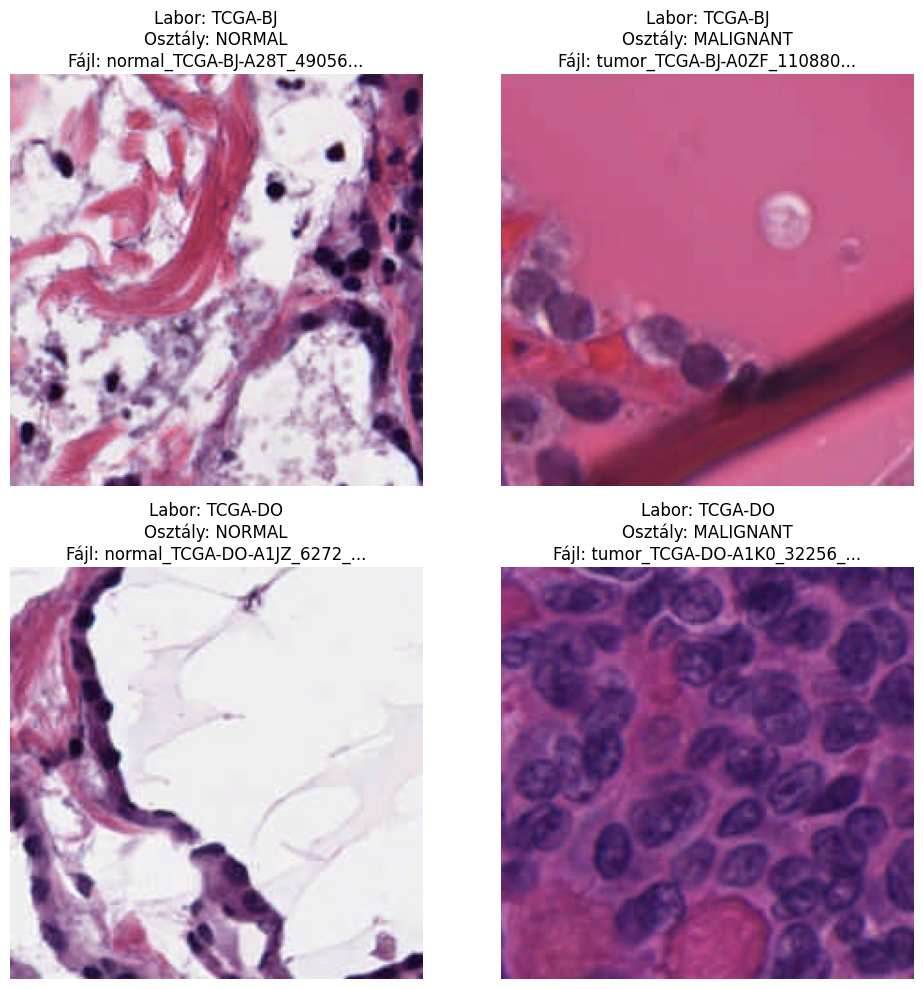

In [5]:
import os
import glob
import matplotlib.pyplot as plt
from PIL import Image

TRAIN_DIR = "/content/Dataset/train"

# 1. Patchek kigyűjtése mindkét osztályból
normal_paths = glob.glob(os.path.join(TRAIN_DIR, "normal", "*.jpg"))
malignant_paths = glob.glob(os.path.join(TRAIN_DIR, "malignant", "*.jpg"))

def extract_tss_lab(filepath):
    """
    Kinyeri a labor kódját a fájlnévből.
    Példa: 'normal_TCGA-EM-A1CV_...' -> 'EM'
    """
    filename = os.path.basename(filepath)
    parts = filename.split('-')
    if len(parts) >= 2:
        return parts[1]  # A TCGA utáni 2 betűs/számos labor kód (TSS)
    return None

# 2. Laborok szerinti csoportosítás
labs_normal = {}
for p in normal_paths:
    lab = extract_tss_lab(p)
    if lab and lab not in labs_normal:
        labs_normal[lab] = p

labs_malignant = {}
for p in malignant_paths:
    lab = extract_tss_lab(p)
    if lab and lab not in labs_malignant:
        labs_malignant[lab] = p

# 3. Két olyan labor keresése, ahol mindkét osztály jelen van
common_labs = sorted(list(set(labs_normal.keys()) & set(labs_malignant.keys())))

if len(common_labs) < 2:
    print(f"Figyelem: Csak {len(common_labs)} közös labor található! A meglévőkből jelenítünk meg.")
    lab1, lab2 = common_labs[0], common_labs[0]
else:
    lab1, lab2 = common_labs[0], common_labs[1]

print(f"Kiválasztott 1. Labor: TCGA-{lab1}")
print(f"Kiválasztott 2. Labor: TCGA-{lab2}")

# 4. Képek betöltése
img_lab1_norm = Image.open(labs_normal[lab1])
img_lab1_mal = Image.open(labs_malignant[lab1])
img_lab2_norm = Image.open(labs_normal[lab2])
img_lab2_mal = Image.open(labs_malignant[lab2])

# 5. Megjelenítés 2x2-es rácsban
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

# 1. Labor
axes[0, 0].imshow(img_lab1_norm)
axes[0, 0].set_title(f"Labor: TCGA-{lab1}\nOsztály: NORMAL\nFájl: {os.path.basename(labs_normal[lab1])[:25]}...")
axes[0, 0].axis("off")

axes[0, 1].imshow(img_lab1_mal)
axes[0, 1].set_title(f"Labor: TCGA-{lab1}\nOsztály: MALIGNANT\nFájl: {os.path.basename(labs_malignant[lab1])[:25]}...")
axes[0, 1].axis("off")

# 2. Labor
axes[1, 0].imshow(img_lab2_norm)
axes[1, 0].set_title(f"Labor: TCGA-{lab2}\nOsztály: NORMAL\nFájl: {os.path.basename(labs_normal[lab2])[:25]}...")
axes[1, 0].axis("off")

axes[1, 1].imshow(img_lab2_mal)
axes[1, 1].set_title(f"Labor: TCGA-{lab2}\nOsztály: MALIGNANT\nFájl: {os.path.basename(labs_malignant[lab2])[:25]}...")
axes[1, 1].axis("off")

plt.tight_layout()
plt.savefig("lab_comparison_patches.png", dpi=300)
plt.show()

Színcsatornák eltérésének vizsgálata:

In [ ]:
import glob
import numpy as np
from PIL import Image

norm_samples = glob.glob("/content/Dataset/test/normal/*.jpg")[:500]
mal_samples = glob.glob("/content/Dataset/test/malignant/*.jpg")[:500]

def calc_mean_rgb(files):
    means = []
    for f in files:
        img = np.array(Image.open(f))
        means.append(img.mean(axis=(0, 1)))
    return np.mean(means, axis=0)

print(f"Vizsgált minták száma: {len(norm_samples)} normál, {len(mal_samples)} tumor")
print("Normal képek átlagos RGB:   ", calc_mean_rgb(norm_samples))
print("Malignant képek átlagos RGB:", calc_mean_rgb(mal_samples))

Vizsgált minták száma: 500 normál, 500 tumor
Normal képek átlagos RGB:    [187.60943347 159.91713194 179.40690513]
Malignant képek átlagos RGB: [177.43301036 117.46957856 153.81836922]


In [ ]:
CHECKPOINT_NAME = "custom_cnn_best_checkpoint.pth"
BUCKET_NAME = "diplomamunka-patches-2026"

!aws s3 cp s3://{BUCKET_NAME}/{CHECKPOINT_NAME} /content/{CHECKPOINT_NAME}

download: s3://diplomamunka-patches-2026/custom_cnn_best_checkpoint.pth to ./custom_cnn_best_checkpoint.pth


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


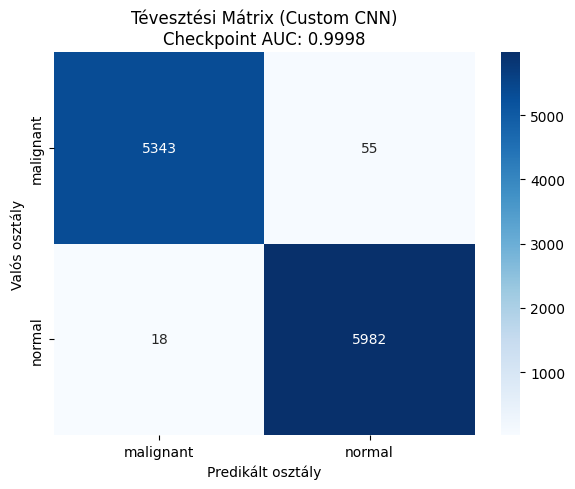


Részletes statisztika:
               precision    recall  f1-score   support

   malignant     0.9966    0.9898    0.9932      5398
      normal     0.9909    0.9970    0.9939      6000

    accuracy                         0.9936     11398
   macro avg     0.9938    0.9934    0.9936     11398
weighted avg     0.9936    0.9936    0.9936     11398



In [ ]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import confusion_matrix, classification_report

# 1. Beállítások és letöltés S3-ról
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_NAME = "custom_cnn_best_checkpoint.pth"
BUCKET_NAME = "diplomamunka-patches-2026"

if not os.path.exists(CHECKPOINT_NAME):
    !aws s3 cp s3://{BUCKET_NAME}/{CHECKPOINT_NAME} /content/{CHECKPOINT_NAME}

# 2. Modell inicializálása és súlyok betöltése
model = CustomCNN(num_classes=2).to(DEVICE)
checkpoint = torch.load(CHECKPOINT_NAME, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

# 3. Teszt adathalmaz betöltése
test_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_dataset = datasets.ImageFolder("/content/Dataset/test", transform=test_transforms)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=4)
classes = test_dataset.classes  # ['malignant', 'normal']

# 4. Predikciók összegyűjtése
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(DEVICE, non_blocking=True)
        outputs = model(inputs)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

# 5. Tévesztési mátrix kirajzolása
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.xlabel("Predikált osztály")
plt.ylabel("Valós osztály")
plt.title(f"Tévesztési Mátrix (Custom CNN)\nCheckpoint AUC: {checkpoint.get('val_auc', 0):.4f}")
plt.tight_layout()
plt.show()

print("\nRészletes statisztika:\n", classification_report(all_labels, all_preds, target_names=classes,digits=4))

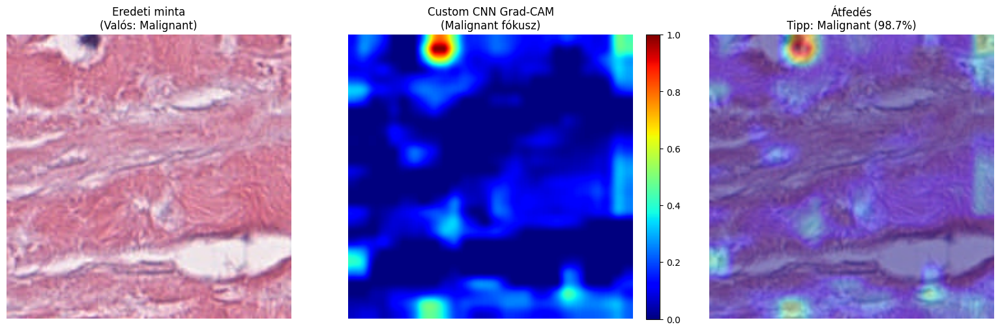

Kép elérési útja: /content/Dataset/test/malignant/tumor_TCGA-KS-A4IB_66304_65856.jpg
Predikció: Malignant (Malignant: 98.68%, Normal: 1.32%)


In [ ]:
import os
import glob
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms

# 1. Beállítások és modell betöltése
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_NAME = "custom_cnn_best_checkpoint.pth"

model = CustomCNN(num_classes=2).to(DEVICE)
checkpoint = torch.load(CHECKPOINT_NAME, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

# 2. Hook-ok regisztrálása a Custom CNN utolsó konvolúciós rétegére (block4)
target_layer = model.block4[0]  # block4 Conv2d rétege

activations = []
gradients = []

def forward_hook(module, input, output):
    activations.append(output)

def backward_hook(module, grad_in, grad_out):
    gradients.append(grad_out[0])

target_layer.register_forward_hook(forward_hook)
target_layer.register_full_backward_hook(backward_hook)

# 3. Minta kép kiválasztása a teszthalmazból
# Tetszés szerint módosíthatod az indexet vagy az osztályt ('malignant' / 'normal')
test_image_paths = glob.glob("/content/Dataset/test/malignant/*.jpg")
sample_path = test_image_paths[0]
raw_img = Image.open(sample_path).convert("RGB")

preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
input_tensor = preprocess(raw_img).unsqueeze(0).to(DEVICE)

# 4. Forward és Backward pass
activations.clear()
gradients.clear()

output = model(input_tensor)
probs = F.softmax(output, dim=1).squeeze().detach().cpu().numpy()
pred_class = torch.argmax(output, dim=1).item()

class_names = {0: "Malignant", 1: "Normal"}

# A predikált osztály gradiensének visszavezetése
score = output[0, pred_class]
model.zero_grad()
score.backward()

# 5. Grad-CAM kalkuláció
pooled_gradients = torch.mean(gradients[0], dim=[0, 2, 3])
act = activations[0].squeeze(0)

cam = torch.zeros(act.shape[1:], dtype=torch.float32, device=DEVICE)
for i in range(len(pooled_gradients)):
    cam += pooled_gradients[i] * act[i]

cam = F.relu(cam)
cam = cam.detach().cpu().numpy()
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

cam_resized = Image.fromarray(np.uint8(255 * cam)).resize((raw_img.width, raw_img.height), Image.BICUBIC)
cam_resized = np.asarray(cam_resized) / 255.0

# 6. Megjelenítés
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(raw_img)
axes[0].set_title("Eredeti minta\n(Valós: Malignant)")
axes[0].axis("off")

im1 = axes[1].imshow(cam_resized, cmap="jet", vmin=0, vmax=1)
axes[1].set_title(f"Custom CNN Grad-CAM\n({class_names[pred_class]} fókusz)")
axes[1].axis("off")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

axes[2].imshow(raw_img)
axes[2].imshow(cam_resized, cmap="jet", alpha=0.45)
axes[2].set_title(f"Átfedés\nTipp: {class_names[pred_class]} ({probs[pred_class]*100:.1f}%)")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("viz_custom_cnn_gradcam.png", dpi=300)
plt.show()

print(f"Kép elérési útja: {sample_path}")
print(f"Predikció: {class_names[pred_class]} (Malignant: {probs[0]*100:.2f}%, Normal: {probs[1]*100:.2f}%)")

saját cnn újrafuttatása csökkentett adatbázissal:

In [ ]:
import os
import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import roc_auc_score

# 1. Beállítások
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Számítási eszköz: {DEVICE}")

CHECKPOINT_NAME = "custom_cnn_sub180k_checkpoint.pth"
BATCH_SIZE = 64
NUM_WORKERS = 4
NUM_EPOCHS = 3

TRAIN_DIR = "/content/dataset_sub_180k/train"
TEST_DIR = "/content/Dataset/test"

# 2. Adat-előkészítés
train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=(0, 180)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transforms)
test_dataset = datasets.ImageFolder(TEST_DIR, transform=test_transforms)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)

mal_idx = train_dataset.class_to_idx['malignant']
print(f"Tanító képek: {len(train_dataset):,} db | Teszt képek: {len(test_dataset):,} db")
print(f"Osztályok kiosztása: {train_dataset.class_to_idx} (Malignant index: {mal_idx})")

# 3. Saját CNN példányosítása és optimalizáló
model = CustomCNN(num_classes=2).to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
scaler = torch.cuda.amp.GradScaler()

# 4. Tanítási ciklus
best_auc = 0.0
print(f"\nCNN tanítása ({NUM_EPOCHS} epoch)...")
start_all = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.time()

    # TRAIN FÁZIS
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for batch_idx, (inputs, labels) in enumerate(train_loader):
        inputs, labels = inputs.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast():
            outputs = model(inputs)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data).item()
        total += labels.size(0)

        if (batch_idx + 1) % 500 == 0:
            print(f"Epoch [{epoch}/{NUM_EPOCHS}] | Batch [{batch_idx+1}/{len(train_loader)}] "
                  f"| Loss: {running_loss/total:.4f} | Acc: {correct/total*100:.2f}%")

    #VALIDÁCIÓS FÁZIS
    model.eval()
    val_labels, val_probs, val_preds = [], [], []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)
            with torch.cuda.amp.autocast():
                outputs = model(inputs)
                probs = torch.softmax(outputs, dim=1)

            val_labels.extend(labels.cpu().numpy())
            val_probs.extend(probs[:, mal_idx].cpu().numpy())
            val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())

    binary_targets = (np.array(val_labels) == mal_idx).astype(int)
    val_auc = roc_auc_score(binary_targets, val_probs)
    val_acc = np.mean(np.array(val_labels) == np.array(val_preds))

    elapsed = time.time() - epoch_start
    print(f"\nEpoch {epoch} Kész ({elapsed:.1f} mp):")
    print(f"  Train Acc: {correct/total*100:.2f}% | Val Acc: {val_acc*100:.2f}% | Val AUC: {val_auc:.4f}")

    if val_auc > best_auc:
        best_auc = val_auc
        print(f"  Új legjobb AUC ({val_auc:.4f})! Modell mentése")
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'val_auc': val_auc,
            'val_acc': val_acc
        }, CHECKPOINT_NAME)

print(f"\nTeljes futásidő: {time.time() - start_all:.1f} mp")

Számítási eszköz: cuda
Tanító képek: 171,958 db | Teszt képek: 11,398 db
Osztályok kiosztása: {'malignant': 0, 'normal': 1} (Malignant index: 0)

CNN tanítása (3 epoch)...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/tmp/ipykernel_761/370539982.py:53: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation migh

Epoch [1/3] | Batch [500/2687] | Loss: 0.1250 | Acc: 95.49%
Epoch [1/3] | Batch [1000/2687] | Loss: 0.0990 | Acc: 96.42%
Epoch [1/3] | Batch [1500/2687] | Loss: 0.0836 | Acc: 96.97%
Epoch [1/3] | Batch [2000/2687] | Loss: 0.0753 | Acc: 97.27%
Epoch [1/3] | Batch [2500/2687] | Loss: 0.0695 | Acc: 97.46%


/tmp/ipykernel_761/370539982.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



Epoch 1 Kész (449.1 mp):
  Train Acc: 97.52% | Val Acc: 98.62% | Val AUC: 0.9995
  Új legjobb AUC (0.9995)! Modell mentése


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/tmp/ipykernel_761/370539982.py:71: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


... (3 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/tmp/ipykernel_761/370539982.py:71: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch [3/3] | Batch [500/2687] | Loss: 0.0318 | Acc: 98.86%
Epoch [3/3] | Batch [1000/2687] | Loss: 0.0310 | Acc: 98.91%
Epoch [3/3] | Batch [1500/2687] | Loss: 0.0297 | Acc: 98.93%
Epoch [3/3] | Batch [2000/2687] | Loss: 0.0290 | Acc: 98.96%
Epoch [3/3] | Batch [2500/2687] | Loss: 0.0285 | Acc: 98.97%


/tmp/ipykernel_761/370539982.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



Epoch 3 Kész (377.5 mp):
  Train Acc: 98.97% | Val Acc: 97.53% | Val AUC: 0.9996
  Új legjobb AUC (0.9996)! Modell mentése

Teljes futásidő: 1203.9 mp


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


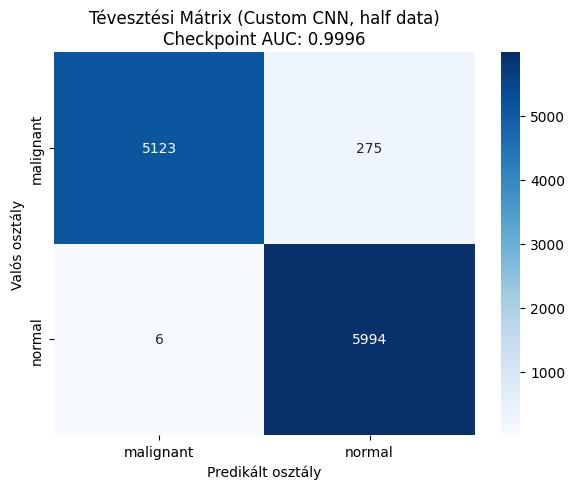


Részletes statisztika:
               precision    recall  f1-score   support

   malignant     0.9988    0.9491    0.9733      5398
      normal     0.9561    0.9990    0.9771      6000

    accuracy                         0.9753     11398
   macro avg     0.9775    0.9740    0.9752     11398
weighted avg     0.9764    0.9753    0.9753     11398



In [ ]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import confusion_matrix, classification_report

# 1. Beállítások és letöltés S3-ról
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_NAME = "custom_cnn_sub180k_checkpoint.pth"
BUCKET_NAME = "diplomamunka-patches-2026"

if not os.path.exists(CHECKPOINT_NAME):
    !aws s3 cp s3://{BUCKET_NAME}/{CHECKPOINT_NAME} /content/{CHECKPOINT_NAME}

# 2. Modell inicializálása és súlyok betöltése
model = CustomCNN(num_classes=2).to(DEVICE)
checkpoint = torch.load(CHECKPOINT_NAME, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

# 3. Teszt adathalmaz betöltése
test_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_dataset = datasets.ImageFolder("/content/Dataset/test", transform=test_transforms)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=4)
classes = test_dataset.classes  # ['malignant', 'normal']

# 4. Predikciók összegyűjtése
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(DEVICE, non_blocking=True)
        outputs = model(inputs)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

# 5. Tévesztési mátrix kirajzolása
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.xlabel("Predikált osztály")
plt.ylabel("Valós osztály")
plt.title(f"Tévesztési Mátrix (Custom CNN, half data)\nCheckpoint AUC: {checkpoint.get('val_auc', 0):.4f}")
plt.tight_layout()
plt.show()

print("\nRészletes statisztika:\n", classification_report(all_labels, all_preds, target_names=classes,digits=4))

Feltöltés:

In [ ]:
BUCKET_NAME = "diplomamunka-patches-2026"
CHECKPOINT_NAME = "custom_cnn_sub180k_checkpoint.pth"

!aws s3 cp {CHECKPOINT_NAME} s3://{BUCKET_NAME}/{CHECKPOINT_NAME}
print(f"CNN modellcheckpoint elmentve: s3://{BUCKET_NAME}/{CHECKPOINT_NAME}")

upload: ./custom_cnn_sub180k_checkpoint.pth to s3://diplomamunka-patches-2026/custom_cnn_sub180k_checkpoint.pth
CNN modellcheckpoint elmentve: s3://diplomamunka-patches-2026/custom_cnn_sub180k_checkpoint.pth


Letöltés:

In [ ]:
BUCKET_NAME = "diplomamunka-patches-2026"
CHECKPOINT_NAME = "custom_cnn_sub180k_checkpoint.pth"

!aws s3 cp s3://{BUCKET_NAME}/{CHECKPOINT_NAME} {CHECKPOINT_NAME}
print(f"CNN modellcheckpoint letöltve: {CHECKPOINT_NAME}")

download: s3://diplomamunka-patches-2026/custom_cnn_sub180k_checkpoint.pth to ./custom_cnn_sub180k_checkpoint.pth
CNN modellcheckpoint letöltve: custom_cnn_sub180k_checkpoint.pth


Sikeresen betöltve a checkpoint! (Menti AUC: 0.9996)

Tanító készlet kiértékelése...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/tmp/ipykernel_420/2243321249.py:50: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Teszt készlet kiértékelése...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/tmp/ipykernel_420/2243321249.py:50: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



=== EREDMÉNYEK ===
TRAIN -> Loss: 0.1074 | Acc: 97.02% | AUC: 0.9991
TEST  -> Loss: 0.0731 | Acc: 97.53% | AUC: 0.9996


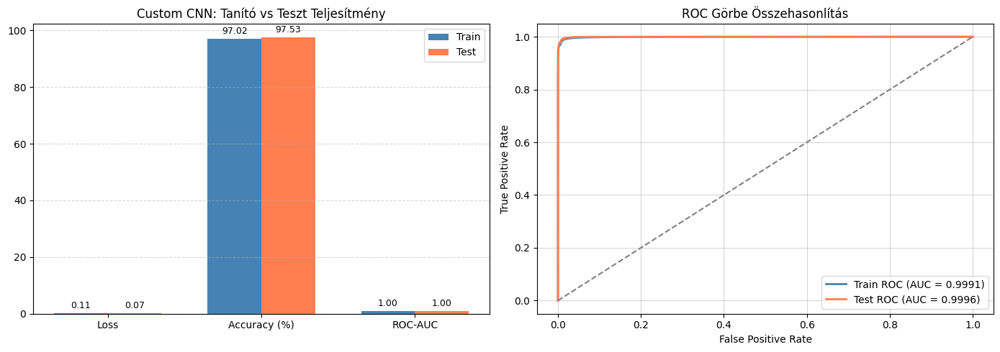

In [ ]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import roc_auc_score, accuracy_score, roc_curve

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_NAME = "custom_cnn_sub180k_checkpoint.pth"
BATCH_SIZE = 64
NUM_WORKERS = 4

TRAIN_DIR = "/content/dataset_sub_180k/train"
TEST_DIR = "/content/Dataset/test"

eval_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=eval_transforms)
test_dataset = datasets.ImageFolder(TEST_DIR, transform=eval_transforms)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

mal_idx = train_dataset.class_to_idx['malignant']

model = CustomCNN(num_classes=2).to(DEVICE)
checkpoint = torch.load(CHECKPOINT_NAME, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

criterion = nn.CrossEntropyLoss()

print(f"Sikeresen betöltve a checkpoint! (Menti AUC: {checkpoint.get('val_auc', 'N/A'):.4f})")

# 3. Kiértékelő függvény egy tetszőleges DataLoader-re
def evaluate_loader(loader):
    running_loss = 0.0
    all_labels, all_probs, all_preds = [], [], []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)

            with torch.cuda.amp.autocast():
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                probs = F.softmax(outputs, dim=1)

            running_loss += loss.item() * inputs.size(0)
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs[:, mal_idx].cpu().numpy())
            all_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())

    total_samples = len(loader.dataset)
    avg_loss = running_loss / total_samples
    acc = accuracy_score(all_labels, all_preds)

    binary_targets = (np.array(all_labels) == mal_idx).astype(int)
    auc_score = roc_auc_score(binary_targets, all_probs)

    return avg_loss, acc, auc_score, binary_targets, np.array(all_probs)

# 4. Kiértékelés a Tanító és Teszt halmazokon
print("\nTanító készlet kiértékelése...")
train_loss, train_acc, train_auc, train_targets, train_probs = evaluate_loader(train_loader)

print("Teszt készlet kiértékelése...")
test_loss, test_acc, test_auc, test_targets, test_probs = evaluate_loader(test_loader)

print("\n=== EREDMÉNYEK ===")
print(f"TRAIN -> Loss: {train_loss:.4f} | Acc: {train_acc*100:.2f}% | AUC: {train_auc:.4f}")
print(f"TEST  -> Loss: {test_loss:.4f} | Acc: {test_acc*100:.2f}% | AUC: {test_auc:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# A. Train vs Test Metrikák Oszlopdiagramja
metrics = ['Loss', 'Accuracy (%)', 'ROC-AUC']
train_vals = [train_loss, train_acc * 100, train_auc]
test_vals = [test_loss, test_acc * 100, test_auc]

x = np.arange(len(metrics))
width = 0.35

rects1 = axes[0].bar(x - width/2, train_vals, width, label='Train', color='steelblue')
rects2 = axes[0].bar(x + width/2, test_vals, width, label='Test', color='coral')

axes[0].set_title('Custom CNN: Tanító vs Teszt Teljesítmény')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics)
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

for rect in rects1 + rects2:
    height = rect.get_height()
    axes[0].annotate(f'{height:.2f}',
                     xy=(rect.get_x() + rect.get_width() / 2, height),
                     xytext=(0, 3), textcoords="offset points",
                     ha='center', va='bottom', fontsize=9)

# B. ROC Görbék (Train vs Test)
fpr_tr, tpr_tr, _ = roc_curve(train_targets, train_probs)
fpr_te, tpr_te, _ = roc_curve(test_targets, test_probs)

axes[1].plot(fpr_tr, tpr_tr, color='steelblue', lw=2, label=f'Train ROC (AUC = {train_auc:.4f})')
axes[1].plot(fpr_te, tpr_te, color='coral', lw=2, label=f'Test ROC (AUC = {test_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='grey', linestyle='--')
axes[1].set_title('ROC Görbe Összehasonlítás')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.5)

plt.tight_layout()
plt.savefig("checkpoint_evaluation_results.png", dpi=300)
plt.show()

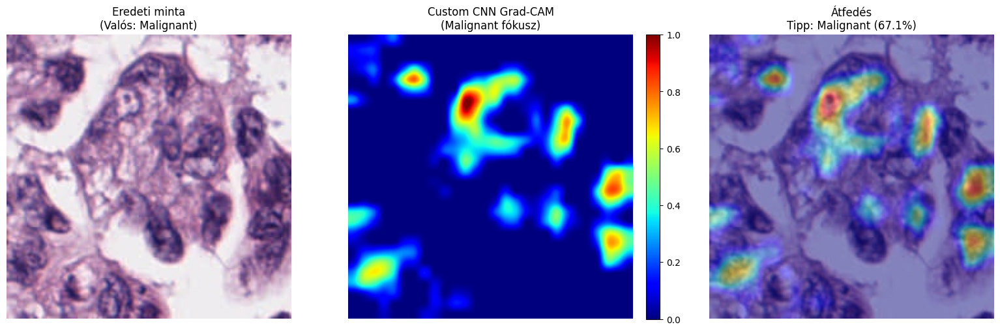

Kép elérési útja: /content/Dataset/test/malignant/tumor_TCGA-EL-A3MX_14112_30240.jpg
Predikció: Malignant (Malignant: 67.06%, Normal: 32.94%)


In [ ]:
import os
import glob
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms

# 1. Beállítások és modell betöltése
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_NAME = "custom_cnn_sub180k_checkpoint.pth"

model = CustomCNN(num_classes=2).to(DEVICE)
checkpoint = torch.load(CHECKPOINT_NAME, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

# 2. Hook-ok regisztrálása a Custom CNN utolsó konvolúciós rétegére (block4)
target_layer = model.block4[0]  # block4 Conv2d rétege

activations = []
gradients = []

def forward_hook(module, input, output):
    activations.append(output)

def backward_hook(module, grad_in, grad_out):
    gradients.append(grad_out[0])

target_layer.register_forward_hook(forward_hook)
target_layer.register_full_backward_hook(backward_hook)

# 3. Minta kép kiválasztása a teszthalmazból
# JAVÍTÁS: A helyes, létező tesztkönyvtár használata a hibás sub_180k helyett
test_image_paths = glob.glob("/content/Dataset/test/malignant/*.jpg")
sample_path = test_image_paths[0]
raw_img = Image.open(sample_path).convert("RGB")

preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
input_tensor = preprocess(raw_img).unsqueeze(0).to(DEVICE)

# 4. Forward és Backward pass
activations.clear()
gradients.clear()

output = model(input_tensor)
probs = F.softmax(output, dim=1).squeeze().detach().cpu().numpy()
pred_class = torch.argmax(output, dim=1).item()

class_names = {0: "Malignant", 1: "Normal"}

# A predikált osztály gradiensének visszavezetése
score = output[0, pred_class]
model.zero_grad()
score.backward()

# 5. Grad-CAM kalkuláció
pooled_gradients = torch.mean(gradients[0], dim=[0, 2, 3])
act = activations[0].squeeze(0)

cam = torch.zeros(act.shape[1:], dtype=torch.float32, device=DEVICE)
for i in range(len(pooled_gradients)):
    cam += pooled_gradients[i] * act[i]

cam = F.relu(cam)
cam = cam.detach().cpu().numpy()
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

cam_resized = Image.fromarray(np.uint8(255 * cam)).resize((raw_img.width, raw_img.height), Image.BICUBIC)
cam_resized = np.asarray(cam_resized) / 255.0

# 6. Megjelenítés
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(raw_img)
axes[0].set_title("Eredeti minta\n(Valós: Malignant)")
axes[0].axis("off")

im1 = axes[1].imshow(cam_resized, cmap="jet", vmin=0, vmax=1)
axes[1].set_title(f"Custom CNN Grad-CAM\n({class_names[pred_class]} fókusz)")
axes[1].axis("off")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

axes[2].imshow(raw_img)
axes[2].imshow(cam_resized, cmap="jet", alpha=0.45)
axes[2].set_title(f"Átfedés\nTipp: {class_names[pred_class]} ({probs[pred_class]*100:.1f}%)")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("viz_custom_cnn_180k_gradcam.png", dpi=300)
plt.show()

print(f"Kép elérési útja: {sample_path}")
print(f"Predikció: {class_names[pred_class]} (Malignant: {probs[0]*100:.2f}%, Normal: {probs[1]*100:.2f}%)")

In [ ]:
import os
import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import roc_auc_score

# 1. Beállítások
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Számítási eszköz: {DEVICE}")

CHECKPOINT_NAME = "custom_cnn_sub90k_checkpoint.pth"
BATCH_SIZE = 64
NUM_WORKERS = 4
NUM_EPOCHS = 3

TRAIN_DIR = "/content/Dataset_sub_90k/train"
TEST_DIR = "/content/Dataset/test"

# 2. Adat-előkészítés
train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=(0, 180)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transforms)
test_dataset = datasets.ImageFolder(TEST_DIR, transform=test_transforms)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)

mal_idx = train_dataset.class_to_idx['malignant']
print(f"Tanító képek: {len(train_dataset):,} db | Teszt képek: {len(test_dataset):,} db")
print(f"Osztályok kiosztása: {train_dataset.class_to_idx} (Malignant index: {mal_idx})")

# 3. Saját CNN példányosítása és optimalizáló
model = CustomCNN(num_classes=2).to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
scaler = torch.cuda.amp.GradScaler()

# 4. Tanítási ciklus
best_auc = 0.0
print(f"\nCNN tanítása ({NUM_EPOCHS} epoch)...")
start_all = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.time()

    # TRAIN FÁZIS
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for batch_idx, (inputs, labels) in enumerate(train_loader):
        inputs, labels = inputs.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast():
            outputs = model(inputs)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data).item()
        total += labels.size(0)

        if (batch_idx + 1) % 500 == 0:
            print(f"Epoch [{epoch}/{NUM_EPOCHS}] | Batch [{batch_idx+1}/{len(train_loader)}] "
                  f"| Loss: {running_loss/total:.4f} | Acc: {correct/total*100:.2f}%")

    #VALIDÁCIÓS FÁZIS
    model.eval()
    val_labels, val_probs, val_preds = [], [], []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)
            with torch.cuda.amp.autocast():
                outputs = model(inputs)
                probs = torch.softmax(outputs, dim=1)

            val_labels.extend(labels.cpu().numpy())
            val_probs.extend(probs[:, mal_idx].cpu().numpy())
            val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())

    binary_targets = (np.array(val_labels) == mal_idx).astype(int)
    val_auc = roc_auc_score(binary_targets, val_probs)
    val_acc = np.mean(np.array(val_labels) == np.array(val_preds))

    elapsed = time.time() - epoch_start
    print(f"\nEpoch {epoch} Kész ({elapsed:.1f} mp):")
    print(f"  Train Acc: {correct/total*100:.2f}% | Val Acc: {val_acc*100:.2f}% | Val AUC: {val_auc:.4f}")

    if val_auc > best_auc:
        best_auc = val_auc
        print(f"  Új legjobb AUC ({val_auc:.4f})! Modell mentése")
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'val_auc': val_auc,
            'val_acc': val_acc
        }, CHECKPOINT_NAME)

print(f"\nTeljes futásidő: {time.time() - start_all:.1f} mp")

Számítási eszköz: cuda
Tanító képek: 86,452 db | Teszt képek: 11,398 db
Osztályok kiosztása: {'malignant': 0, 'normal': 1} (Malignant index: 0)

CNN tanítása (3 epoch)...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/tmp/ipykernel_761/426327861.py:53: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation migh

Epoch [1/3] | Batch [500/1351] | Loss: 0.1242 | Acc: 95.14%
Epoch [1/3] | Batch [1000/1351] | Loss: 0.0962 | Acc: 96.28%


/tmp/ipykernel_761/426327861.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



Epoch 1 Kész (207.7 mp):
  Train Acc: 96.69% | Val Acc: 98.32% | Val AUC: 0.9987
  Új legjobb AUC (0.9987)! Modell mentése


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/tmp/ipykernel_761/426327861.py:71: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


... (3 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/tmp/ipykernel_761/426327861.py:71: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch [3/3] | Batch [500/1351] | Loss: 0.0349 | Acc: 98.74%
Epoch [3/3] | Batch [1000/1351] | Loss: 0.0350 | Acc: 98.75%


/tmp/ipykernel_761/426327861.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



Epoch 3 Kész (188.3 mp):
  Train Acc: 98.79% | Val Acc: 96.63% | Val AUC: 0.9989
  Új legjobb AUC (0.9989)! Modell mentése

Teljes futásidő: 590.7 mp


feltöltés:

In [ ]:
BUCKET_NAME = "diplomamunka-patches-2026"
CHECKPOINT_NAME = "custom_cnn_sub90k_checkpoint.pth"

!aws s3 cp {CHECKPOINT_NAME} s3://{BUCKET_NAME}/{CHECKPOINT_NAME}
print(f"CNN modellcheckpoint elmentve: s3://{BUCKET_NAME}/{CHECKPOINT_NAME}")

upload: ./custom_cnn_sub90k_checkpoint.pth to s3://diplomamunka-patches-2026/custom_cnn_sub90k_checkpoint.pth
CNN modellcheckpoint elmentve: s3://diplomamunka-patches-2026/custom_cnn_sub90k_checkpoint.pth


Letöltés:

In [ ]:
BUCKET_NAME = "diplomamunka-patches-2026"
CHECKPOINT_NAME = "custom_cnn_sub90k_checkpoint.pth"

!aws s3 cp s3://{BUCKET_NAME}/{CHECKPOINT_NAME} {CHECKPOINT_NAME}
print(f"CNN modellcheckpoint letöltve: {CHECKPOINT_NAME}")

download: s3://diplomamunka-patches-2026/custom_cnn_sub90k_checkpoint.pth to ./custom_cnn_sub90k_checkpoint.pth
CNN modellcheckpoint letöltve: custom_cnn_sub90k_checkpoint.pth


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


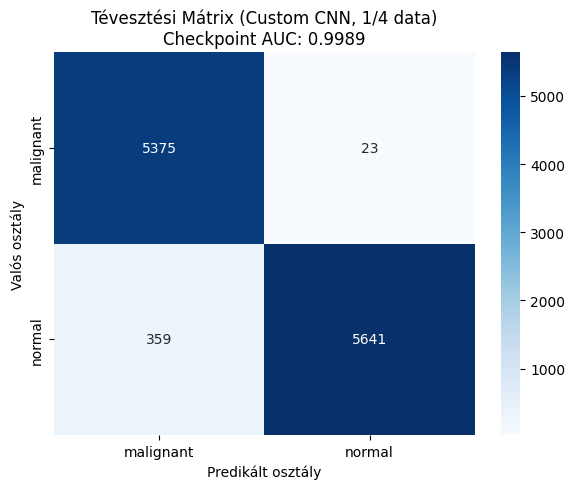


Részletes statisztika:
               precision    recall  f1-score   support

   malignant     0.9374    0.9957    0.9657      5398
      normal     0.9959    0.9402    0.9672      6000

    accuracy                         0.9665     11398
   macro avg     0.9667    0.9680    0.9665     11398
weighted avg     0.9682    0.9665    0.9665     11398



In [ ]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import confusion_matrix, classification_report

# 1. Beállítások és letöltés S3-ról
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_NAME = "custom_cnn_sub90k_checkpoint.pth"
BUCKET_NAME = "diplomamunka-patches-2026"

if not os.path.exists(CHECKPOINT_NAME):
    !aws s3 cp s3://{BUCKET_NAME}/{CHECKPOINT_NAME} /content/{CHECKPOINT_NAME}

# 2. Modell inicializálása és súlyok betöltése
model = CustomCNN(num_classes=2).to(DEVICE)
checkpoint = torch.load(CHECKPOINT_NAME, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

# 3. Teszt adathalmaz betöltése
test_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_dataset = datasets.ImageFolder("/content/Dataset/test", transform=test_transforms)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=4)
classes = test_dataset.classes  # ['malignant', 'normal']

# 4. Predikciók összegyűjtése
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(DEVICE, non_blocking=True)
        outputs = model(inputs)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

# 5. Tévesztési mátrix kirajzolása
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.xlabel("Predikált osztály")
plt.ylabel("Valós osztály")
plt.title(f"Tévesztési Mátrix (Custom CNN, 1/4 data)\nCheckpoint AUC: {checkpoint.get('val_auc', 0):.4f}")
plt.tight_layout()
plt.show()

print("\nRészletes statisztika:\n", classification_report(all_labels, all_preds, target_names=classes,digits=4))

Sikeresen betöltve a checkpoint! (Menti AUC: 0.9989)

Tanító készlet kiértékelése...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/tmp/ipykernel_420/402834095.py:50: Future

Teszt készlet kiértékelése...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/tmp/ipykernel_420/402834095.py:50: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



=== EREDMÉNYEK ===
TRAIN -> Loss: 0.0321 | Acc: 98.82% | AUC: 0.9997
TEST  -> Loss: 0.1013 | Acc: 96.63% | AUC: 0.9989


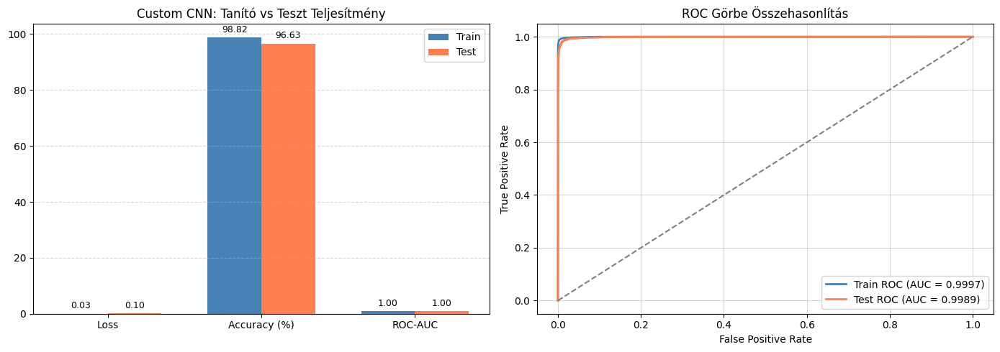

In [ ]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import roc_auc_score, accuracy_score, roc_curve

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_NAME = "custom_cnn_sub90k_checkpoint.pth"
BATCH_SIZE = 64
NUM_WORKERS = 4

TRAIN_DIR = "/content/Dataset_sub_90k/train"
TEST_DIR = "/content/Dataset/test"

eval_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=eval_transforms)
test_dataset = datasets.ImageFolder(TEST_DIR, transform=eval_transforms)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

mal_idx = train_dataset.class_to_idx['malignant']

model = CustomCNN(num_classes=2).to(DEVICE)
checkpoint = torch.load(CHECKPOINT_NAME, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

criterion = nn.CrossEntropyLoss()

print(f"Sikeresen betöltve a checkpoint! (Menti AUC: {checkpoint.get('val_auc', 'N/A'):.4f})")

# 3. Kiértékelő függvény egy tetszőleges DataLoader-re
def evaluate_loader(loader):
    running_loss = 0.0
    all_labels, all_probs, all_preds = [], [], []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)

            with torch.cuda.amp.autocast():
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                probs = F.softmax(outputs, dim=1)

            running_loss += loss.item() * inputs.size(0)
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs[:, mal_idx].cpu().numpy())
            all_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())

    total_samples = len(loader.dataset)
    avg_loss = running_loss / total_samples
    acc = accuracy_score(all_labels, all_preds)

    binary_targets = (np.array(all_labels) == mal_idx).astype(int)
    auc_score = roc_auc_score(binary_targets, all_probs)

    return avg_loss, acc, auc_score, binary_targets, np.array(all_probs)

# 4. Kiértékelés a Tanító és Teszt halmazokon
print("\nTanító készlet kiértékelése...")
train_loss, train_acc, train_auc, train_targets, train_probs = evaluate_loader(train_loader)

print("Teszt készlet kiértékelése...")
test_loss, test_acc, test_auc, test_targets, test_probs = evaluate_loader(test_loader)

print("\n=== EREDMÉNYEK ===")
print(f"TRAIN -> Loss: {train_loss:.4f} | Acc: {train_acc*100:.2f}% | AUC: {train_auc:.4f}")
print(f"TEST  -> Loss: {test_loss:.4f} | Acc: {test_acc*100:.2f}% | AUC: {test_auc:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# A. Train vs Test Metrikák Oszlopdiagramja
metrics = ['Loss', 'Accuracy (%)', 'ROC-AUC']
train_vals = [train_loss, train_acc * 100, train_auc]
test_vals = [test_loss, test_acc * 100, test_auc]

x = np.arange(len(metrics))
width = 0.35

rects1 = axes[0].bar(x - width/2, train_vals, width, label='Train', color='steelblue')
rects2 = axes[0].bar(x + width/2, test_vals, width, label='Test', color='coral')

axes[0].set_title('Custom CNN: Tanító vs Teszt Teljesítmény')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics)
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

for rect in rects1 + rects2:
    height = rect.get_height()
    axes[0].annotate(f'{height:.2f}',
                     xy=(rect.get_x() + rect.get_width() / 2, height),
                     xytext=(0, 3), textcoords="offset points",
                     ha='center', va='bottom', fontsize=9)

# B. ROC Görbék (Train vs Test)
fpr_tr, tpr_tr, _ = roc_curve(train_targets, train_probs)
fpr_te, tpr_te, _ = roc_curve(test_targets, test_probs)

axes[1].plot(fpr_tr, tpr_tr, color='steelblue', lw=2, label=f'Train ROC (AUC = {train_auc:.4f})')
axes[1].plot(fpr_te, tpr_te, color='coral', lw=2, label=f'Test ROC (AUC = {test_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='grey', linestyle='--')
axes[1].set_title('ROC Görbe Összehasonlítás')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.5)

plt.tight_layout()
plt.savefig("checkpoint_evaluation_results.png", dpi=300)
plt.show()

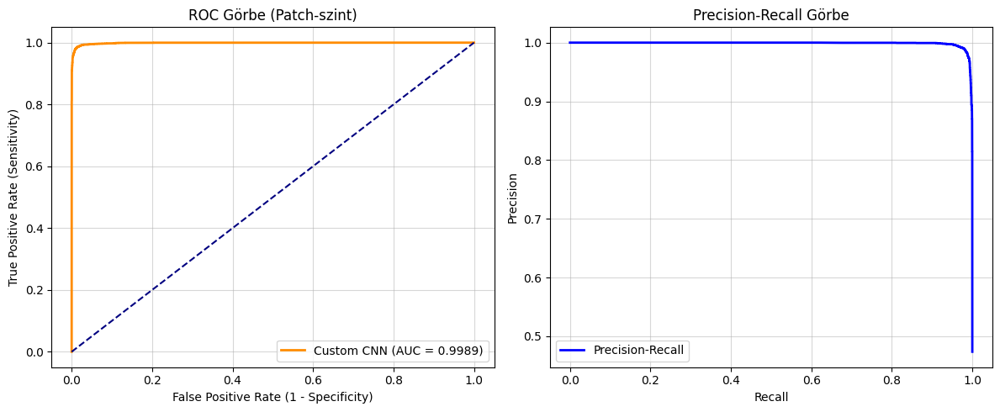

In [ ]:
from sklearn.metrics import roc_curve, precision_recall_curve, auc
import matplotlib.pyplot as plt

# JAVÍTÁS: A korábban legenerált test_targets és test_probs változók használata
fpr, tpr, _ = roc_curve(test_targets, test_probs)
roc_auc = auc(fpr, tpr)

# PR görbe kiszámítása a megfelelő változókkal
precision, recall, _ = precision_recall_curve(test_targets, test_probs)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC Görbe rajzolása
axes[0].plot(fpr, tpr, color='darkorange', lw=2, label=f'Custom CNN (AUC = {roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--')
axes[0].set_title('ROC Görbe (Patch-szint)')
axes[0].set_xlabel('False Positive Rate (1 - Specificity)')
axes[0].set_ylabel('True Positive Rate (Sensitivity)')
axes[0].legend(loc="lower right")
axes[0].grid(True, alpha=0.5)

# Precision-Recall Görbe rajzolása
axes[1].plot(recall, precision, color='blue', lw=2, label='Precision-Recall')
axes[1].set_title('Precision-Recall Görbe')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()
axes[1].grid(True, alpha=0.5)

plt.tight_layout()
plt.savefig("roc_pr_curves.png", dpi=300)
plt.show()

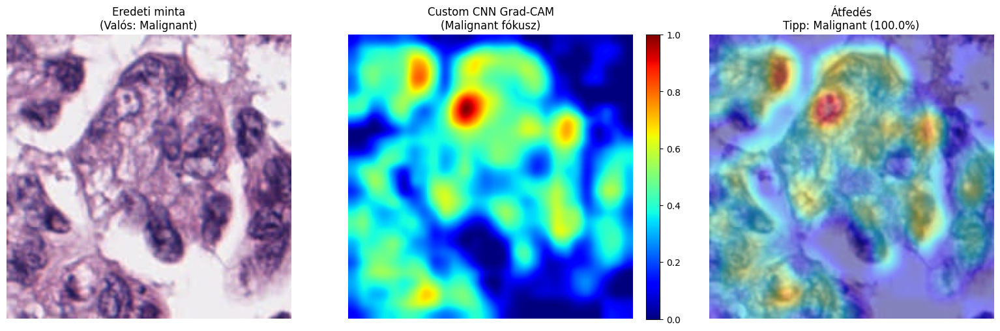

Kép elérési útja: /content/Dataset/test/malignant/tumor_TCGA-EL-A3MX_14112_30240.jpg
Predikció: Malignant (Malignant: 100.00%, Normal: 0.00%)


In [ ]:
import os
import glob
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms

# 1. Beállítások és modell betöltése
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_NAME = "custom_cnn_sub90k_checkpoint.pth"

model = CustomCNN(num_classes=2).to(DEVICE)
checkpoint = torch.load(CHECKPOINT_NAME, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

# 2. Hook-ok regisztrálása a Custom CNN utolsó konvolúciós rétegére (block4)
target_layer = model.block4[0]  # block4 Conv2d rétege

activations = []
gradients = []

def forward_hook(module, input, output):
    activations.append(output)

def backward_hook(module, grad_in, grad_out):
    gradients.append(grad_out[0])

target_layer.register_forward_hook(forward_hook)
target_layer.register_full_backward_hook(backward_hook)

# 3. Minta kép kiválasztása a teszthalmazból
# Tetszés szerint módosíthatod az indexet vagy az osztályt ('malignant' / 'normal')
test_image_paths = glob.glob("/content/Dataset/test/malignant/*.jpg")
sample_path = test_image_paths[0]
raw_img = Image.open(sample_path).convert("RGB")

preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
input_tensor = preprocess(raw_img).unsqueeze(0).to(DEVICE)

# 4. Forward és Backward pass
activations.clear()
gradients.clear()

output = model(input_tensor)
probs = F.softmax(output, dim=1).squeeze().detach().cpu().numpy()
pred_class = torch.argmax(output, dim=1).item()

class_names = {0: "Malignant", 1: "Normal"}

# A predikált osztály gradiensének visszavezetése
score = output[0, pred_class]
model.zero_grad()
score.backward()

# 5. Grad-CAM kalkuláció
pooled_gradients = torch.mean(gradients[0], dim=[0, 2, 3])
act = activations[0].squeeze(0)

cam = torch.zeros(act.shape[1:], dtype=torch.float32, device=DEVICE)
for i in range(len(pooled_gradients)):
    cam += pooled_gradients[i] * act[i]

cam = F.relu(cam)
cam = cam.detach().cpu().numpy()
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

cam_resized = Image.fromarray(np.uint8(255 * cam)).resize((raw_img.width, raw_img.height), Image.BICUBIC)
cam_resized = np.asarray(cam_resized) / 255.0

# 6. Megjelenítés
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(raw_img)
axes[0].set_title("Eredeti minta\n(Valós: Malignant)")
axes[0].axis("off")

im1 = axes[1].imshow(cam_resized, cmap="jet", vmin=0, vmax=1)
axes[1].set_title(f"Custom CNN Grad-CAM\n({class_names[pred_class]} fókusz)")
axes[1].axis("off")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

axes[2].imshow(raw_img)
axes[2].imshow(cam_resized, cmap="jet", alpha=0.45)
axes[2].set_title(f"Átfedés\nTipp: {class_names[pred_class]} ({probs[pred_class]*100:.1f}%)")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("viz_custom_cnn_180k_gradcam.png", dpi=300)
plt.show()

print(f"Kép elérési útja: {sample_path}")
print(f"Predikció: {class_names[pred_class]} (Malignant: {probs[0]*100:.2f}%, Normal: {probs[1]*100:.2f}%)")

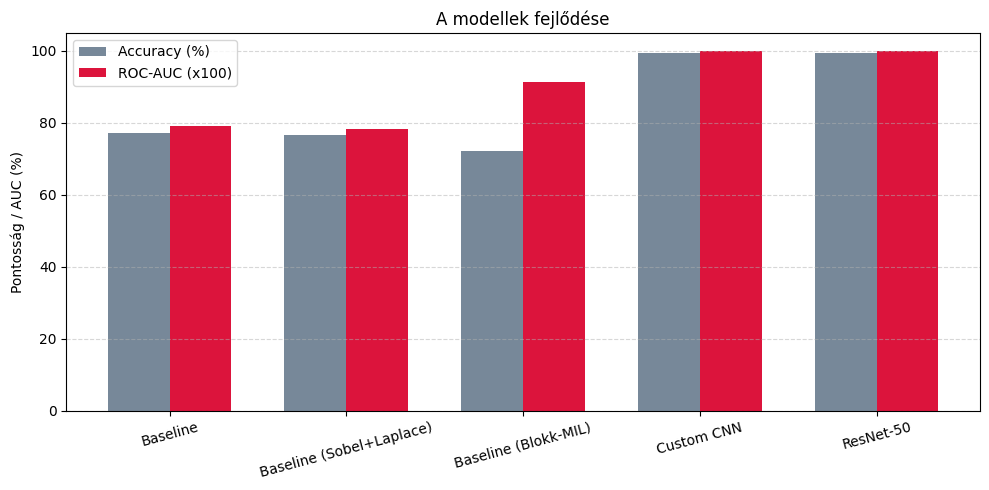

In [ ]:
models = ['Baseline', 'Baseline (Sobel+Laplace)', 'Baseline (Blokk-MIL)', 'Custom CNN', 'ResNet-50']
accuracy = [77.18, 76.53, 72.10, 99.36, 99.51]
auc_scores = [0.7901, 0.7841, 0.9126, 0.9998, 1.0000]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - width/2, accuracy, width, label='Accuracy (%)', color='lightslategrey')
ax.bar(x + width/2, [a * 100 for a in auc_scores], width, label='ROC-AUC (x100)', color='crimson')

ax.set_ylabel('Pontosság / AUC (%)')
ax.set_title('A modellek fejlődése')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=15)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("model_evolution_comparison.png", dpi=300)
plt.show()

# Páciens szintű tesztelés:
A teszthalmazból kinyerem a páciens id-kat aztán a hozzájuk tartozó patcheke t kiértékelem a modellel majd az eredményt átlagolva kapok egy százalékot, ha ez nagyobb mint 50 akkor malignant az eredmény.
Kiszámolom 90k-s és 180k-s checkpointtal is

A teszthalmazban talált egyedi betegek száma: 20 db

Páciensenkénti aggregáció futtatása...
Beteg: TCGA-BJ-A28R    | Típus: malignant | Patchek:  300 db | Átlag Malignant Valószínűség:  98.4% | Eredmény: ok
Beteg: TCGA-BJ-A28R    | Típus: normal    | Patchek:  300 db | Átlag Malignant Valószínűség:   0.2% | Eredmény: ok
Beteg: TCGA-BJ-A45E    | Típus: malignant | Patchek:  300 db | Átlag Malignant Valószínűség:  95.3% | Eredmény: ok
Beteg: TCGA-BJ-A45E    | Típus: normal    | Patchek:  300 db | Átlag Malignant Valószínűség:   0.2% | Eredmény: ok
Beteg: TCGA-BJ-A4O9    | Típus: malignant | Patchek:  598 db | Átlag Malignant Valószínűség:  97.1% | Eredmény: ok
Beteg: TCGA-BJ-A4O9    | Típus: normal    | Patchek:  300 db | Átlag Malignant Valószínűség:   0.1% | Eredmény: ok
Beteg: TCGA-E8-A2JQ    | Típus: malignant | Patchek:  300 db | Átlag Malignant Valószínűség:  97.2% | Eredmény: ok
Beteg: TCGA-E8-A2JQ    | Típus: normal    | Patchek:  300 db | Átlag Malignant Valószínűség:   0.1% | E

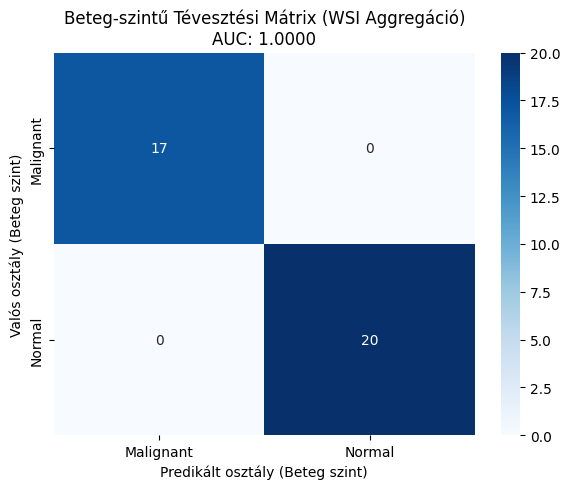


=== BETEG-SZINTŰ OSZTÁLYOZÁSI JELENTÉS ===
              precision    recall  f1-score   support

   Malignant       1.00      1.00      1.00        17
      Normal       1.00      1.00      1.00        20

    accuracy                           1.00        37
   macro avg       1.00      1.00      1.00        37
weighted avg       1.00      1.00      1.00        37



In [ ]:
import os
import glob
from collections import defaultdict
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from torchvision import transforms
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# 1. Beállítások és modell betöltése
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_NAME = "custom_cnn_best_checkpoint.pth"

model = CustomCNN(num_classes=2).to(DEVICE)
checkpoint = torch.load(CHECKPOINT_NAME, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

# 2. Transzformáció
preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 3. Páciens-azonosító kinyerése és patchek feltérképezése a teszthalmazban
def extract_patient_id(file_path):
    fname = os.path.basename(file_path)
    for part in fname.split("_"):
        if part.startswith("TCGA-"):
            return part
    return None

test_dir = "/content/Dataset/test"
# Struktúra: patient_samples[patient_id][true_class_name] = [fpath1, fpath2, ...]
patient_samples = defaultdict(lambda: defaultdict(list))

for cls_name in ["malignant", "normal"]:
    for fpath in glob.glob(os.path.join(test_dir, cls_name, "*.jpg")):
        pid = extract_patient_id(fpath)
        if pid:
            patient_samples[pid][cls_name].append(fpath)

print(f"A teszthalmazban talált egyedi betegek száma: {len(patient_samples)} db")

# 4. Páciens-szintű predikció aggregáció (Mean pooling & Majority vote)
# Osztályindexek: 0: malignant, 1: normal
patient_true_labels = []
patient_pred_labels = []
patient_mean_probs = []

print("\nPáciensenkénti aggregáció futtatása...")

with torch.no_grad():
    for pid, classes_dict in sorted(patient_samples.items()):
        for true_cls, files in classes_dict.items():
            true_label_idx = 0 if true_cls == "malignant" else 1

            # Batch-ekben kiértékeljük az adott beteg adott metszetének patcheit
            batch_tensors = []
            mal_probs_list = []

            for fpath in files:
                img = Image.open(fpath).convert("RGB")
                batch_tensors.append(preprocess(img))

                if len(batch_tensors) == 64:
                    inputs = torch.stack(batch_tensors).to(DEVICE)
                    outputs = model(inputs)
                    probs = F.softmax(outputs, dim=1)
                    mal_probs_list.extend(probs[:, 0].cpu().numpy())  # 0: malignant prob
                    batch_tensors.clear()

            if batch_tensors:
                inputs = torch.stack(batch_tensors).to(DEVICE)
                outputs = model(inputs)
                probs = F.softmax(outputs, dim=1)
                mal_probs_list.extend(probs[:, 0].cpu().numpy())

            # Páciens-szintű döntés: a daganatos valószínűségek átlaga a metszeten
            mean_mal_prob = float(np.mean(mal_probs_list))
            pred_cls_idx = 0 if mean_mal_prob >= 0.5 else 1  # 0: malignant, 1: normal

            patient_true_labels.append(true_label_idx)
            patient_pred_labels.append(pred_cls_idx)
            patient_mean_probs.append(mean_mal_prob)

            status = "ok" if pred_cls_idx == true_label_idx else "nok"
            print(f"Beteg: {pid:<15} | Típus: {true_cls:<9} | Patchek: {len(files):>4} db "
                  f"| Átlag Malignant Valószínűség: {mean_mal_prob*100:5.1f}% | Eredmény: {status}")

# 5. Beteg-szintű tévesztési mátrix és metrikák
target_names = ["Malignant", "Normal"]
cm = confusion_matrix(patient_true_labels, patient_pred_labels)

# AUC számításhoz a cél: 1 ha malignant (0-s index), 0 ha normal (1-es index)
binary_targets = [1 if t == 0 else 0 for t in patient_true_labels]
patient_auc = roc_auc_score(binary_targets, patient_mean_probs)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=target_names, yticklabels=target_names)
plt.xlabel("Predikált osztály (Beteg szint)")
plt.ylabel("Valós osztály (Beteg szint)")
plt.title(f"Beteg-szintű Tévesztési Mátrix (WSI Aggregáció)\nAUC: {patient_auc:.4f}")
plt.tight_layout()
plt.show()

print("\n=== BETEG-SZINTŰ OSZTÁLYOZÁSI JELENTÉS ===")
print(classification_report(patient_true_labels, patient_pred_labels, target_names=target_names))

In [ ]:
CHECKPOINT_NAME = "custom_cnn_sub180k_checkpoint.pth"
BUCKET_NAME = "diplomamunka-patches-2026"

!aws s3 cp s3://{BUCKET_NAME}/{CHECKPOINT_NAME} /content/{CHECKPOINT_NAME}
CHECKPOINT_NAME = "custom_cnn_sub90k_checkpoint.pth"
BUCKET_NAME = "diplomamunka-patches-2026"

!aws s3 cp s3://{BUCKET_NAME}/{CHECKPOINT_NAME} /content/{CHECKPOINT_NAME}

download: s3://diplomamunka-patches-2026/custom_cnn_sub180k_checkpoint.pth to ./custom_cnn_sub180k_checkpoint.pth
download: s3://diplomamunka-patches-2026/custom_cnn_sub90k_checkpoint.pth to ./custom_cnn_sub90k_checkpoint.pth


A teszthalmazban talált egyedi betegek száma: 20 db

Páciensenkénti aggregáció futtatása...
Beteg: TCGA-BJ-A28R    | Típus: malignant | Patchek:  300 db | Átlag Malignant Valószínűség:  96.5% | Eredmény: ok
Beteg: TCGA-BJ-A28R    | Típus: normal    | Patchek:  300 db | Átlag Malignant Valószínűség:   0.0% | Eredmény: ok
Beteg: TCGA-BJ-A45E    | Típus: malignant | Patchek:  300 db | Átlag Malignant Valószínűség:  88.5% | Eredmény: ok
Beteg: TCGA-BJ-A45E    | Típus: normal    | Patchek:  300 db | Átlag Malignant Valószínűség:   0.0% | Eredmény: ok
Beteg: TCGA-BJ-A4O9    | Típus: malignant | Patchek:  598 db | Átlag Malignant Valószínűség:  90.9% | Eredmény: ok
Beteg: TCGA-BJ-A4O9    | Típus: normal    | Patchek:  300 db | Átlag Malignant Valószínűség:   0.0% | Eredmény: ok
Beteg: TCGA-E8-A2JQ    | Típus: malignant | Patchek:  300 db | Átlag Malignant Valószínűség:  99.2% | Eredmény: ok
Beteg: TCGA-E8-A2JQ    | Típus: normal    | Patchek:  300 db | Átlag Malignant Valószínűség:   0.0% | E

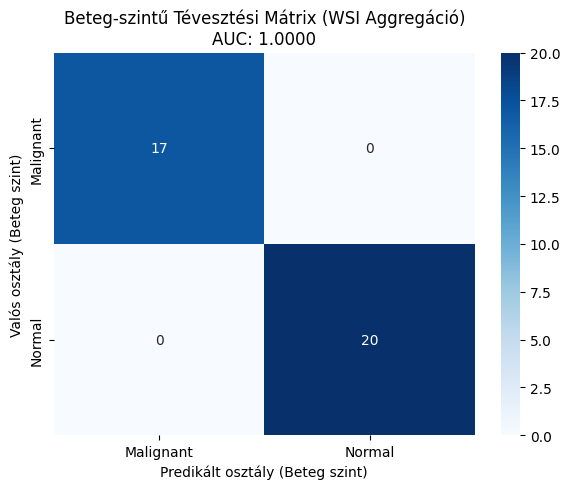


=== BETEG-SZINTŰ OSZTÁLYOZÁSI JELENTÉS ===
              precision    recall  f1-score   support

   Malignant       1.00      1.00      1.00        17
      Normal       1.00      1.00      1.00        20

    accuracy                           1.00        37
   macro avg       1.00      1.00      1.00        37
weighted avg       1.00      1.00      1.00        37



In [ ]:


import os
import glob
from collections import defaultdict
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from torchvision import transforms
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# 1. Beállítások és modell betöltése
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_NAME = "custom_cnn_sub180k_checkpoint.pth"

model = CustomCNN(num_classes=2).to(DEVICE)
checkpoint = torch.load(CHECKPOINT_NAME, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

# 2. Transzformáció
preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 3. Páciens-azonosító kinyerése és patchek feltérképezése a teszthalmazban
def extract_patient_id(file_path):
    fname = os.path.basename(file_path)
    for part in fname.split("_"):
        if part.startswith("TCGA-"):
            return part
    return None

test_dir = "/content/Dataset/test"
# Struktúra: patient_samples[patient_id][true_class_name] = [fpath1, fpath2, ...]
patient_samples = defaultdict(lambda: defaultdict(list))

for cls_name in ["malignant", "normal"]:
    for fpath in glob.glob(os.path.join(test_dir, cls_name, "*.jpg")):
        pid = extract_patient_id(fpath)
        if pid:
            patient_samples[pid][cls_name].append(fpath)

print(f"A teszthalmazban talált egyedi betegek száma: {len(patient_samples)} db")

# 4. Páciens-szintű predikció aggregáció (Mean pooling & Majority vote)
# Osztályindexek: 0: malignant, 1: normal
patient_true_labels = []
patient_pred_labels = []
patient_mean_probs = []

print("\nPáciensenkénti aggregáció futtatása...")

with torch.no_grad():
    for pid, classes_dict in sorted(patient_samples.items()):
        for true_cls, files in classes_dict.items():
            true_label_idx = 0 if true_cls == "malignant" else 1

            # Batch-ekben kiértékeljük az adott beteg adott metszetének patcheit
            batch_tensors = []
            mal_probs_list = []

            for fpath in files:
                img = Image.open(fpath).convert("RGB")
                batch_tensors.append(preprocess(img))

                if len(batch_tensors) == 64:
                    inputs = torch.stack(batch_tensors).to(DEVICE)
                    outputs = model(inputs)
                    probs = F.softmax(outputs, dim=1)
                    mal_probs_list.extend(probs[:, 0].cpu().numpy())  # 0: malignant prob
                    batch_tensors.clear()

            if batch_tensors:
                inputs = torch.stack(batch_tensors).to(DEVICE)
                outputs = model(inputs)
                probs = F.softmax(outputs, dim=1)
                mal_probs_list.extend(probs[:, 0].cpu().numpy())

            # Páciens-szintű döntés: a daganatos valószínűségek átlaga a metszeten
            mean_mal_prob = float(np.mean(mal_probs_list))
            pred_cls_idx = 0 if mean_mal_prob >= 0.5 else 1  # 0: malignant, 1: normal

            patient_true_labels.append(true_label_idx)
            patient_pred_labels.append(pred_cls_idx)
            patient_mean_probs.append(mean_mal_prob)

            status = "ok" if pred_cls_idx == true_label_idx else "nok"
            print(f"Beteg: {pid:<15} | Típus: {true_cls:<9} | Patchek: {len(files):>4} db "
                  f"| Átlag Malignant Valószínűség: {mean_mal_prob*100:5.1f}% | Eredmény: {status}")

# 5. Beteg-szintű tévesztési mátrix és metrikák
target_names = ["Malignant", "Normal"]
cm = confusion_matrix(patient_true_labels, patient_pred_labels)

# AUC számításhoz a cél: 1 ha malignant (0-s index), 0 ha normal (1-es index)
binary_targets = [1 if t == 0 else 0 for t in patient_true_labels]
patient_auc = roc_auc_score(binary_targets, patient_mean_probs)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=target_names, yticklabels=target_names)
plt.xlabel("Predikált osztály (Beteg szint)")
plt.ylabel("Valós osztály (Beteg szint)")
plt.title(f"Beteg-szintű Tévesztési Mátrix (WSI Aggregáció)\nAUC: {patient_auc:.4f}")
plt.tight_layout()
plt.show()

print("\n=== BETEG-SZINTŰ OSZTÁLYOZÁSI JELENTÉS ===")
print(classification_report(patient_true_labels, patient_pred_labels, target_names=target_names))

A teszthalmazban talált egyedi betegek száma: 20 db

Páciensenkénti aggregáció futtatása...
Beteg: TCGA-BJ-A28R    | Típus: malignant | Patchek:  300 db | Átlag Malignant Valószínűség:  97.2% | Eredmény: ok
Beteg: TCGA-BJ-A28R    | Típus: normal    | Patchek:  300 db | Átlag Malignant Valószínűség:   1.0% | Eredmény: ok
Beteg: TCGA-BJ-A45E    | Típus: malignant | Patchek:  300 db | Átlag Malignant Valószínűség:  98.5% | Eredmény: ok
Beteg: TCGA-BJ-A45E    | Típus: normal    | Patchek:  300 db | Átlag Malignant Valószínűség:   1.0% | Eredmény: ok
Beteg: TCGA-BJ-A4O9    | Típus: malignant | Patchek:  598 db | Átlag Malignant Valószínűség:  99.7% | Eredmény: ok
Beteg: TCGA-BJ-A4O9    | Típus: normal    | Patchek:  300 db | Átlag Malignant Valószínűség:   0.2% | Eredmény: ok
Beteg: TCGA-E8-A2JQ    | Típus: malignant | Patchek:  300 db | Átlag Malignant Valószínűség: 100.0% | Eredmény: ok
Beteg: TCGA-E8-A2JQ    | Típus: normal    | Patchek:  300 db | Átlag Malignant Valószínűség:   3.5% | E

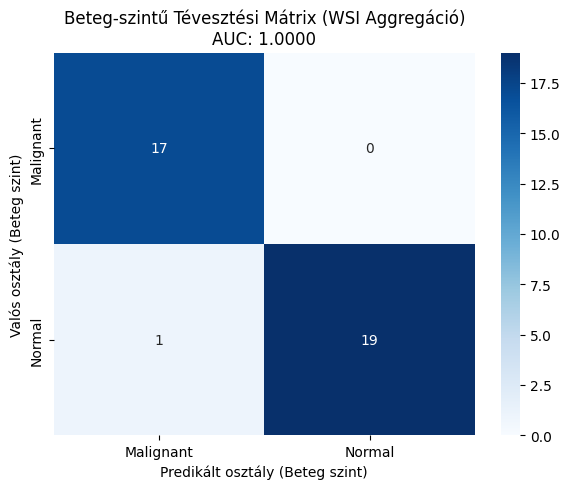


=== BETEG-SZINTŰ OSZTÁLYOZÁSI JELENTÉS ===
              precision    recall  f1-score   support

   Malignant       0.94      1.00      0.97        17
      Normal       1.00      0.95      0.97        20

    accuracy                           0.97        37
   macro avg       0.97      0.97      0.97        37
weighted avg       0.97      0.97      0.97        37



In [ ]:


import os
import glob
from collections import defaultdict
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from torchvision import transforms
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# 1. Beállítások és modell betöltése
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_NAME = "custom_cnn_sub90k_checkpoint.pth"

model = CustomCNN(num_classes=2).to(DEVICE)
checkpoint = torch.load(CHECKPOINT_NAME, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

# 2. Transzformáció
preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 3. Páciens-azonosító kinyerése és patchek feltérképezése a teszthalmazban
def extract_patient_id(file_path):
    fname = os.path.basename(file_path)
    for part in fname.split("_"):
        if part.startswith("TCGA-"):
            return part
    return None

test_dir = "/content/Dataset/test"
# Struktúra: patient_samples[patient_id][true_class_name] = [fpath1, fpath2, ...]
patient_samples = defaultdict(lambda: defaultdict(list))

for cls_name in ["malignant", "normal"]:
    for fpath in glob.glob(os.path.join(test_dir, cls_name, "*.jpg")):
        pid = extract_patient_id(fpath)
        if pid:
            patient_samples[pid][cls_name].append(fpath)

print(f"A teszthalmazban talált egyedi betegek száma: {len(patient_samples)} db")

# 4. Páciens-szintű predikció aggregáció (Mean pooling & Majority vote)
# Osztályindexek: 0: malignant, 1: normal
patient_true_labels = []
patient_pred_labels = []
patient_mean_probs = []

print("\nPáciensenkénti aggregáció futtatása...")

with torch.no_grad():
    for pid, classes_dict in sorted(patient_samples.items()):
        for true_cls, files in classes_dict.items():
            true_label_idx = 0 if true_cls == "malignant" else 1

            # Batch-ekben kiértékeljük az adott beteg adott metszetének patcheit
            batch_tensors = []
            mal_probs_list = []

            for fpath in files:
                img = Image.open(fpath).convert("RGB")
                batch_tensors.append(preprocess(img))

                if len(batch_tensors) == 64:
                    inputs = torch.stack(batch_tensors).to(DEVICE)
                    outputs = model(inputs)
                    probs = F.softmax(outputs, dim=1)
                    mal_probs_list.extend(probs[:, 0].cpu().numpy())  # 0: malignant prob
                    batch_tensors.clear()

            if batch_tensors:
                inputs = torch.stack(batch_tensors).to(DEVICE)
                outputs = model(inputs)
                probs = F.softmax(outputs, dim=1)
                mal_probs_list.extend(probs[:, 0].cpu().numpy())

            # Páciens-szintű döntés: a daganatos valószínűségek átlaga a metszeten
            mean_mal_prob = float(np.mean(mal_probs_list))
            pred_cls_idx = 0 if mean_mal_prob >= 0.5 else 1  # 0: malignant, 1: normal

            patient_true_labels.append(true_label_idx)
            patient_pred_labels.append(pred_cls_idx)
            patient_mean_probs.append(mean_mal_prob)

            status = "ok" if pred_cls_idx == true_label_idx else "nok"
            print(f"Beteg: {pid:<15} | Típus: {true_cls:<9} | Patchek: {len(files):>4} db "
                  f"| Átlag Malignant Valószínűség: {mean_mal_prob*100:5.1f}% | Eredmény: {status}")

# 5. Beteg-szintű tévesztési mátrix és metrikák
target_names = ["Malignant", "Normal"]
cm = confusion_matrix(patient_true_labels, patient_pred_labels)

# AUC számításhoz a cél: 1 ha malignant (0-s index), 0 ha normal (1-es index)
binary_targets = [1 if t == 0 else 0 for t in patient_true_labels]
patient_auc = roc_auc_score(binary_targets, patient_mean_probs)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=target_names, yticklabels=target_names)
plt.xlabel("Predikált osztály (Beteg szint)")
plt.ylabel("Valós osztály (Beteg szint)")
plt.title(f"Beteg-szintű Tévesztési Mátrix (WSI Aggregáció)\nAUC: {patient_auc:.4f}")
plt.tight_layout()
plt.show()

print("\n=== BETEG-SZINTŰ OSZTÁLYOZÁSI JELENTÉS ===")
print(classification_report(patient_true_labels, patient_pred_labels, target_names=target_names))

Az egyetlen félre diagnosztizált beteg, leginkább félrediagnosztizált patch-ének a grad-cam-ja

Megtalált normál patchek száma (TCGA-EM-A1CV): 300 db

Legnagyobb hiba: normal_TCGA-EM-A1CV_47712_6272.jpg
Modell által jósolt Malignant valószínűség erre a patchre: 99.99%


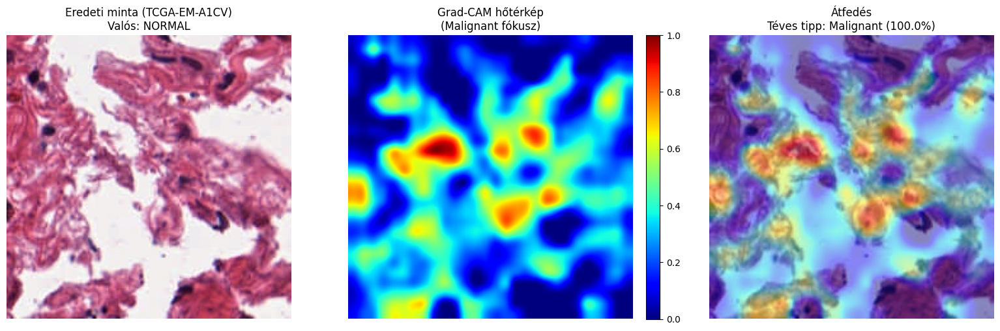

In [ ]:
import os
import glob
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms

# 1. Beállítások és modell betöltése (Custom CNN)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_NAME = "custom_cnn_sub90k_checkpoint.pth"

model = CustomCNN(num_classes=2).to(DEVICE)
checkpoint = torch.load(CHECKPOINT_NAME, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

# 2. Hook-ok regisztrálása a Custom CNN utolsó konvolúciós rétegére
target_layer = model.block4[0]
activations, gradients = [], []

def forward_hook(module, input, output):
    activations.append(output)

def backward_hook(module, grad_in, grad_out):
    gradients.append(grad_out[0])

target_layer.register_forward_hook(forward_hook)
target_layer.register_full_backward_hook(backward_hook)

preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 3. Kifejezetten a hibás TCGA-EM-A1CV beteg normal patcheinek begyűjtése
TARGET_PATIENT = "TCGA-EM-A1CV"
normal_patches = glob.glob(f"/content/Dataset/test/normal/*{TARGET_PATIENT}*.jpg")
print(f"Megtalált normál patchek száma ({TARGET_PATIENT}): {len(normal_patches)} db")

# Megkeressük a leginkább tévesztett (legmagasabb malignant valószínűségű) patch-et
highest_mal_prob = -1.0
worst_patch_path = None

with torch.no_grad():
    for p in normal_patches:
        img = Image.open(p).convert("RGB")
        tensor = preprocess(img).unsqueeze(0).to(DEVICE)
        out = model(tensor)
        p_mal = F.softmax(out, dim=1)[0, 0].item()  # 0: malignant prob
        if p_mal > highest_mal_prob:
            highest_mal_prob = p_mal
            worst_patch_path = p

print(f"\nLegnagyobb hiba: {os.path.basename(worst_patch_path)}")
print(f"Modell által jósolt Malignant valószínűség erre a patchre: {highest_mal_prob*100:.2f}%")

# 4. Grad-CAM futtatása erre a konkrét hibás képre
raw_img = Image.open(worst_patch_path).convert("RGB")
input_tensor = preprocess(raw_img).unsqueeze(0).to(DEVICE)

activations.clear()
gradients.clear()

output = model(input_tensor)
probs = F.softmax(output, dim=1).squeeze().detach().cpu().numpy()

# A Malignant osztály (0) gradiensét kérjük le, hogy lássuk, MIT nézett daganatnak
score = output[0, 0]
model.zero_grad()
score.backward()

# 5. Hőtérkép kalkuláció
pooled_gradients = torch.mean(gradients[0], dim=[0, 2, 3])
act = activations[0].squeeze(0)

cam = torch.zeros(act.shape[1:], dtype=torch.float32, device=DEVICE)
for i in range(len(pooled_gradients)):
    cam += pooled_gradients[i] * act[i]

cam = F.relu(cam)
cam = cam.detach().cpu().numpy()
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

cam_resized = Image.fromarray(np.uint8(255 * cam)).resize((raw_img.width, raw_img.height), Image.BICUBIC)
cam_resized = np.asarray(cam_resized) / 255.0

# 6. Megjelenítés
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(raw_img)
axes[0].set_title(f"Eredeti minta ({TARGET_PATIENT})\nValós: NORMAL")
axes[0].axis("off")

im1 = axes[1].imshow(cam_resized, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("Grad-CAM hőtérkép\n(Malignant fókusz)")
axes[1].axis("off")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

axes[2].imshow(raw_img)
axes[2].imshow(cam_resized, cmap="jet", alpha=0.45)
axes[2].set_title(f"Átfedés\nTéves tipp: Malignant ({probs[0]*100:.1f}%)")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("viz_error_analysis_gradcam.png", dpi=300)
plt.show()